In [1]:
# ============================================================
# SEDIMENTARY STRUCTURE ANALYSIS PIPELINE
# ============================================================
# AI-assisted identification + quantitative image analysis
# + paleocurrent analysis + sedimentological interpretation
#
# STEP 01 : IMPORT LIBRARIES
# ============================================================

# ------------------------------------------------------------
# Operating system / file handling
# ------------------------------------------------------------
import os
import glob
import json
import math
import base64
import warnings

# ------------------------------------------------------------
# Numerical / data analysis
# ------------------------------------------------------------
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Image processing
# ------------------------------------------------------------
import cv2
from PIL import Image

# ------------------------------------------------------------
# Scientific image processing
# ------------------------------------------------------------
from scipy import ndimage
from scipy.ndimage import distance_transform_edt
from scipy.interpolate import UnivariateSpline
from scipy.spatial import cKDTree

# ------------------------------------------------------------
# Scikit-image
# ------------------------------------------------------------
from skimage.morphology import skeletonize
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.measure import regionprops, label

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Machine learning / deep learning
# ------------------------------------------------------------
import torch
import torch.nn as nn
import torchvision.transforms as transforms

# ------------------------------------------------------------
# Optional: segmentation_models_pytorch
# Will be used later if required
# ------------------------------------------------------------
try:
    import segmentation_models_pytorch as smp
    SMP_AVAILABLE = True
except ImportError:
    SMP_AVAILABLE = False

# ------------------------------------------------------------
# SVG export
# ------------------------------------------------------------
import svgwrite

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------
from scipy import stats

# ------------------------------------------------------------
# Warnings
# ------------------------------------------------------------
warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("SEDIMENTARY STRUCTURE ANALYSIS PIPELINE")
print("=" * 70)

print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {DEVICE}")
print(f"OpenCV version  : {cv2.__version__}")
print(f"NumPy version   : {np.__version__}")
print("=" * 70)

SEDIMENTARY STRUCTURE ANALYSIS PIPELINE
PyTorch version : 2.7.1+cpu
Device          : cpu
OpenCV version  : 4.13.0
NumPy version   : 2.1.3


In [2]:
from pathlib import Path
import torch
import pandas as pd
import timm
from PIL import Image
from torchvision import transforms

# ============================================================
# PATHS & CONFIGURATION
# ============================================================
IMAGE_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS43.png"
)

MODEL_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test"
    r"\Benchmark_v2\Benchmark_Results\VisionTransformer_Results"
    r"\Saved_Models\DeiT_Small_Run3.pth"
)

RESULT_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test"
    r"\Sedimentary_Structure_Analysis\Results"
)

AI_PREDICTION_DIR = RESULT_DIR / "01_AI_Prediction"
AI_PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["BSS", "CL", "FS", "HBCS", "HCS", "PCS", "PL", "RM", "TCS"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# LOAD MODEL
# ============================================================
model = timm.create_model(
    "deit_small_patch16_224",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
)

model.to(DEVICE).eval()

# ============================================================
# IMAGE TRANSFORMATION & PREDICTION
# ============================================================
transform = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

image = Image.open(IMAGE_PATH).convert("RGB")
tensor = transform(image).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    probabilities = torch.softmax(model(tensor), dim=1)[0]

# ============================================================
# SAVE ALL 9 PREDICTIONS
# ============================================================
all_predictions = {
    "Image": IMAGE_PATH.name,
    **{
        CLASS_NAMES[i]: round(probabilities[i].item() * 100, 2)
        for i in range(len(CLASS_NAMES))
    }
}

csv_path = AI_PREDICTION_DIR / f"{IMAGE_PATH.stem}_AI_Predictions.csv"
pd.DataFrame([all_predictions]).to_csv(csv_path, index=False)

# ============================================================
# DISPLAY ONLY TOP 3
# ============================================================
top_prob, top_idx = torch.topk(probabilities, 3)

print("\nTOP 3 Sedimentary Structure Predictions")

for rank, (prob, idx) in enumerate(zip(top_prob, top_idx), 1):
    print(
        f"{rank}. {CLASS_NAMES[idx]}: "
        f"{prob.item() * 100:.2f}%"
    )

print(f"\nCSV saved: {csv_path}")


TOP 3 Sedimentary Structure Predictions
1. HCS: 99.21%
2. PL: 0.51%
3. CL: 0.11%

CSV saved: C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\01_AI_Prediction\HCS43_AI_Predictions.csv


STEP 03 : IMAGE PREPROCESSING
Input image used:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS43.png
Original image: HCS43.png | 256 × 256
------------------------------------------------------------
Original size : 256 × 256
Processed size: 256 × 74
Padding removed: True
Removed: Left=0px, Right=0px, Top=91px, Bottom=91px
Saved: C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png


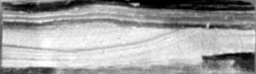


✔ STEP 03 COMPLETED


In [3]:
# ============================================================
# STEP 03 : LOAD SAME INPUT IMAGE + REMOVE IMAGE FRAME
# ============================================================

import os
import numpy as np
from PIL import Image
from IPython.display import display

# ------------------------------------------------------------
# IMPORTANT:
# Use EXACTLY the same IMAGE_PATH defined in STEP 02.
# Do NOT define another image path here.
# ------------------------------------------------------------

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Input image not found:\n{IMAGE_PATH}"
    )

# Keep an explicit record of the image used throughout pipeline
PIPELINE_IMAGE_PATH = IMAGE_PATH

print("=" * 60)
print("STEP 03 : IMAGE PREPROCESSING")
print("=" * 60)

print("Input image used:")
print(PIPELINE_IMAGE_PATH)

# ------------------------------------------------------------
# Load EXACT SAME image used in Step 02
# ------------------------------------------------------------

image_pil = Image.open(PIPELINE_IMAGE_PATH)
image_pil.load()

ORIGINAL_IMAGE_WIDTH, ORIGINAL_IMAGE_HEIGHT = image_pil.size
ORIGINAL_IMAGE_NAME = PIPELINE_IMAGE_PATH.name

print(
    "Original image:",
    ORIGINAL_IMAGE_NAME,
    "|",
    ORIGINAL_IMAGE_WIDTH,
    "×",
    ORIGINAL_IMAGE_HEIGHT
)

# ------------------------------------------------------------
# Convert safely to RGB
# ------------------------------------------------------------

if image_pil.mode == "RGBA":

    arr = np.asarray(image_pil)

    rgb = arr[:, :, :3]
    alpha = arr[:, :, 3]

else:

    rgb = np.asarray(
        image_pil.convert("RGB")
    )

    alpha = np.full(
        rgb.shape[:2],
        255,
        dtype=np.uint8
    )

h, w = rgb.shape[:2]

# ------------------------------------------------------------
# Detect uniform external frame
# ------------------------------------------------------------

corner = np.concatenate([
    rgb[:5, :5].reshape(-1, 3),
    rgb[:5, -5:].reshape(-1, 3),
    rgb[-5:, :5].reshape(-1, 3),
    rgb[-5:, -5:].reshape(-1, 3)
])

bg = np.median(corner, axis=0)

diff = np.max(
    np.abs(
        rgb.astype(np.int16)
        - bg.astype(np.int16)
    ),
    axis=2
)

# Pixels close to background colour
border_like = diff <= 15

# Transparent pixels are considered padding
border_like[alpha < 10] = True

# ------------------------------------------------------------
# Determine rows/columns containing actual image content
# ------------------------------------------------------------

row_score = border_like.mean(axis=1)
col_score = border_like.mean(axis=0)

rows = np.where(row_score < 0.90)[0]
cols = np.where(col_score < 0.90)[0]

if len(rows) == 0 or len(cols) == 0:

    raise RuntimeError(
        "Could not identify image frame safely."
    )

y1, y2 = rows[0], rows[-1]
x1, x2 = cols[0], cols[-1]

# ------------------------------------------------------------
# Crop frame
# ------------------------------------------------------------

processed = Image.fromarray(
    rgb[
        y1:y2 + 1,
        x1:x2 + 1
    ]
)

LAMINA_WORKING_WIDTH, LAMINA_WORKING_HEIGHT = processed.size

# ------------------------------------------------------------
# Record removed padding
# ------------------------------------------------------------

PADDING_LEFT_PX = x1
PADDING_RIGHT_PX = w - 1 - x2
PADDING_TOP_PX = y1
PADDING_BOTTOM_PX = h - 1 - y2

LAMINA_PADDING_REMOVED = any([
    PADDING_LEFT_PX,
    PADDING_RIGHT_PX,
    PADDING_TOP_PX,
    PADDING_BOTTOM_PX
])

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

PREPROCESSED_DIR = (
    Path(
        r"C:\Users\Frontech\Desktop\Codes\Combined Data set"
    )
    / "New Test"
    / "Sedimentary_Structure_Analysis"
    / "Results"
    / "02_Lamina_Detection"
    / "01_Preprocessed"
)

PREPROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Save preprocessed image
# ------------------------------------------------------------

base = PIPELINE_IMAGE_PATH.stem

PROCESSED_IMAGE_PATH = (
    PREPROCESSED_DIR
    / f"{base}_preprocessed.png"
)

processed.save(PROCESSED_IMAGE_PATH)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("-" * 60)

print(
    "Original size :",
    ORIGINAL_IMAGE_WIDTH,
    "×",
    ORIGINAL_IMAGE_HEIGHT
)

print(
    "Processed size:",
    LAMINA_WORKING_WIDTH,
    "×",
    LAMINA_WORKING_HEIGHT
)

print(
    "Padding removed:",
    LAMINA_PADDING_REMOVED
)

print(
    "Removed:",
    f"Left={PADDING_LEFT_PX}px, "
    f"Right={PADDING_RIGHT_PX}px, "
    f"Top={PADDING_TOP_PX}px, "
    f"Bottom={PADDING_BOTTOM_PX}px"
)

print(
    "Saved:",
    PROCESSED_IMAGE_PATH
)

display(processed)

print("\n✔ STEP 03 COMPLETED")

In [4]:
# ============================================================
# STEP 04 : GEOLOGICAL AND IMAGE METADATA
# ============================================================

import os
import pandas as pd
from PIL import Image

print("=" * 65)
print("STEP 04 : GEOLOGICAL AND IMAGE METADATA")
print("=" * 65)


# ============================================================
# 1. VERIFY STEP 03 OUTPUT
# ============================================================

if "PROCESSED_IMAGE_PATH" not in globals():
    raise RuntimeError(
        "❌ Run STEP 03 first."
    )

if not os.path.isfile(PROCESSED_IMAGE_PATH):
    raise RuntimeError(
        "❌ Preprocessed image not found:\n"
        + str(PROCESSED_IMAGE_PATH)
    )


# ============================================================
# 2. ORIGINAL IMAGE DIMENSIONS
# ============================================================
#
# These dimensions refer to the original source image.
#
# They are retained only as metadata.
#
# They are NOT used for lamina geometry calculations.
# ============================================================

if (
    "ORIGINAL_IMAGE_WIDTH" not in globals()
    or
    "ORIGINAL_IMAGE_HEIGHT" not in globals()
):

    raise RuntimeError(
        "❌ Original image dimensions are not available.\n"
        "Please run the previous step first."
    )


print("\nOriginal image")
print(
    f"  Dimensions : "
    f"{ORIGINAL_IMAGE_WIDTH} × "
    f"{ORIGINAL_IMAGE_HEIGHT} px"
)


# ============================================================
# 3. PREPROCESSED NON-PADDED IMAGE DIMENSIONS
# ============================================================
#
# IMPORTANT:
#
# Pixel dimensions are automatically obtained from the actual
# saved PREPROCESSED NON-PADDED image.
#
# The user does NOT enter pixel dimensions manually.
#
# These are the dimensions used for:
#   - automated lamina detection
#   - automated geometry
#   - manual SVG coordinate mapping
#   - thickness
#   - spacing
#
# ============================================================

with Image.open(PROCESSED_IMAGE_PATH) as im:

    IMAGE_WIDTH, IMAGE_HEIGHT = im.size

IMAGE_WIDTH = int(IMAGE_WIDTH)
IMAGE_HEIGHT = int(IMAGE_HEIGHT)


if IMAGE_WIDTH <= 0 or IMAGE_HEIGHT <= 0:

    raise RuntimeError(
        "❌ Invalid preprocessed image dimensions."
    )


print("\nPreprocessed non-padded image")

print(
    f"  Pixel dimensions : "
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)

print(
    f"  File             : "
    f"{PROCESSED_IMAGE_PATH}"
)


# ============================================================
# 4. SEDIMENTOLOGICAL INFORMATION
# ============================================================

LITHOLOGY = input(
    "\nLithology "
    "(e.g., sandstone, siltstone, mudstone, shale): "
).strip()

GRAIN_SIZE = input(
    "Grain size "
    "(fine, medium, coarse; e.g., fine sandstone, "
    "medium sandstone, fine siltstone, coarse silt): "
).strip()

SORTING = input(
    "Sorting "
    "(very well sorted, well sorted, moderately sorted, "
    "poorly sorted, very poorly sorted): "
).strip()

GRAIN_SHAPE = input(
    "Grain shape "
    "(optional; angular, subangular, subrounded, rounded): "
).strip()


# ============================================================
# 5. IMAGE INFORMATION
# ============================================================

IMAGE_TYPE = input(
    "\nImage type "
    "(outcrop, slab, core, hand specimen, thin section, "
    "polished section): "
).strip()

IMAGE_QUALITY = input(
    "Image quality "
    "(excellent, good, moderate, poor): "
).strip()


# ============================================================
# 6. PHYSICAL IMAGE DIMENSIONS AND SCALE
# ============================================================

print("\n" + "-" * 65)
print("PHYSICAL IMAGE DIMENSIONS AND SCALE")
print("-" * 65)

print(
    "\nThe pixel dimensions have already been obtained "
    "automatically from the preprocessed non-padded image."
)

print(
    f"Pixel dimensions : "
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)

print(
    "\nEnter the corresponding PHYSICAL dimensions "
    "of this same preprocessed non-padded image."
)

IMAGE_WIDTH_CM = float(
    input(
        "Physical image width (cm): "
    ).strip()
)

IMAGE_HEIGHT_CM = float(
    input(
        "Physical image height (cm): "
    ).strip()
)


if IMAGE_WIDTH_CM <= 0:

    raise ValueError(
        "❌ Physical image width must be greater than zero."
    )

if IMAGE_HEIGHT_CM <= 0:

    raise ValueError(
        "❌ Physical image height must be greater than zero."
    )


# ============================================================
# 7. SCALE BAR INFORMATION
# ============================================================
#
# The scale bar is optional.
#
# If available, it provides an independent scale check.
#
# The physical image dimensions remain the dimensions entered
# above and are not replaced by the scale-bar calculation.
#
# ============================================================

scale_available = input(
    "\nIs a scale bar available? (yes/no): "
).strip().lower()


SCALE_BAR_LENGTH_CM = None
SCALE_BAR_PIXELS = None


if scale_available in ["yes", "y"]:

    SCALE_BAR_LENGTH_CM = float(
        input(
            "Scale bar length (cm): "
        ).strip()
    )

    SCALE_BAR_PIXELS = float(
        input(
            "Scale bar length in pixels "
            "in the preprocessed image: "
        ).strip()
    )

    if SCALE_BAR_LENGTH_CM <= 0:

        raise ValueError(
            "❌ Scale-bar length must be greater than zero."
        )

    if SCALE_BAR_PIXELS <= 0:

        raise ValueError(
            "❌ Scale-bar pixel length must be greater than zero."
        )

    SCALE_METHOD = (
        "Physical image dimensions "
        "+ scale-bar check"
    )

else:

    SCALE_METHOD = (
        "Physical dimensions of "
        "preprocessed non-padded image"
    )


# ============================================================
# 8. CALCULATE PIXEL SCALE FROM IMAGE DIMENSIONS
# ============================================================
#
# Physical dimensions:
#
#     IMAGE_WIDTH_CM
#     IMAGE_HEIGHT_CM
#
# Pixel dimensions:
#
#     IMAGE_WIDTH
#     IMAGE_HEIGHT
#
# Therefore:
#
#     CM_PER_PIXEL_X =
#         IMAGE_WIDTH_CM / IMAGE_WIDTH
#
#     CM_PER_PIXEL_Y =
#         IMAGE_HEIGHT_CM / IMAGE_HEIGHT
#
# ============================================================

CM_PER_PIXEL_X = (
    IMAGE_WIDTH_CM /
    IMAGE_WIDTH
)

CM_PER_PIXEL_Y = (
    IMAGE_HEIGHT_CM /
    IMAGE_HEIGHT
)


# ============================================================
# 9. CHECK X/Y SCALE AGREEMENT
# ============================================================

scale_difference_percent = (
    abs(
        CM_PER_PIXEL_X -
        CM_PER_PIXEL_Y
    )
    /
    (
        (
            CM_PER_PIXEL_X +
            CM_PER_PIXEL_Y
        ) / 2.0
    )
) * 100.0


print("\nCalculated scale")

print(
    "  X scale :",
    f"{CM_PER_PIXEL_X:.10f}",
    "cm/pixel"
)

print(
    "  Y scale :",
    f"{CM_PER_PIXEL_Y:.10f}",
    "cm/pixel"
)

print(
    "  Difference :",
    f"{scale_difference_percent:.3f}%"
)


if scale_difference_percent > 2.0:

    print(
        "\n⚠ WARNING:"
    )

    print(
        "Width and height scales differ by",
        f"{scale_difference_percent:.2f}%."
    )

    print(
        "The pipeline will continue using the mean "
        "isotropic scale."
    )


# ============================================================
# 10. AUTHORITATIVE SCALE
# ============================================================
#
# The existing analysis methodology uses one scale for:
#
#   - lamina thickness
#   - lamina spacing
#   - curve length
#   - automated measurements
#   - manual measurements
#
# Therefore use the mean X/Y scale.
#
# ============================================================

CM_PER_PIXEL = (
    CM_PER_PIXEL_X +
    CM_PER_PIXEL_Y
) / 2.0


PIXEL_PER_CM = (
    1.0 /
    CM_PER_PIXEL
)


# ============================================================
# 11. OPTIONAL SCALE-BAR CHECK
# ============================================================

if scale_available in ["yes", "y"]:

    SCALE_BAR_CM_PER_PIXEL = (
        SCALE_BAR_LENGTH_CM /
        SCALE_BAR_PIXELS
    )

    scale_bar_difference_percent = (
        abs(
            SCALE_BAR_CM_PER_PIXEL -
            CM_PER_PIXEL
        )
        /
        CM_PER_PIXEL
    ) * 100.0

    print("\nScale-bar check")

    print(
        "  Scale-bar cm/pixel :",
        f"{SCALE_BAR_CM_PER_PIXEL:.10f}"
    )

    print(
        "  Image cm/pixel     :",
        f"{CM_PER_PIXEL:.10f}"
    )

    print(
        "  Difference         :",
        f"{scale_bar_difference_percent:.3f}%"
    )

else:

    SCALE_BAR_CM_PER_PIXEL = None
    scale_bar_difference_percent = None


# ============================================================
# 12. IMAGE ORIENTATION
# ============================================================

print("\n" + "-" * 65)
print("IMAGE ORIENTATION")
print("-" * 65)

IMAGE_LEFT_AZIMUTH = None
IMAGE_RIGHT_AZIMUTH = None

azimuth_known = input(
    "Is the image left-to-right azimuth known? (yes/no): "
).strip().lower()


if azimuth_known in ["yes", "y"]:

    IMAGE_LEFT_AZIMUTH = (
        float(
            input(
                "Left-to-right azimuth (0–360°): "
            ).strip()
        ) % 360
    )

    IMAGE_RIGHT_AZIMUTH = (
        IMAGE_LEFT_AZIMUTH +
        180
    ) % 360


# ============================================================
# 13. BEDDING ORIENTATION
# ============================================================

print("\n" + "-" * 65)
print("BEDDING ORIENTATION")
print("-" * 65)

BEDDING_STRIKE = None
BEDDING_DIP = None
BEDDING_DIP_DIRECTION = None

bedding_known = input(
    "Is bedding orientation known? (yes/no): "
).strip().lower()


if bedding_known in ["yes", "y"]:

    BEDDING_STRIKE = float(
        input(
            "Bedding strike (0–360°): "
        ).strip()
    )

    BEDDING_DIP = float(
        input(
            "Bedding dip angle (°): "
        ).strip()
    )

    BEDDING_DIP_DIRECTION = float(
        input(
            "Bedding dip direction (0–360°): "
        ).strip()
    )


# ============================================================
# 14. ADDITIONAL GEOLOGICAL INFORMATION
# ============================================================

print("\n" + "-" * 65)
print("ADDITIONAL GEOLOGICAL INFORMATION")
print("-" * 65)

STRATIGRAPHIC_UNIT = input(
    "Formation / Member / Group (optional): "
).strip()

GEOLOGICAL_AGE = input(
    "Geological age (optional): "
).strip()

ASSOCIATED_STRUCTURES = input(
    "Associated sedimentary structures "
    "(optional; e.g., ripple marks, mud cracks, "
    "flute casts, bioturbation): "
).strip()

PETROGRAPHIC_INFO = input(
    "Petrographic information "
    "(optional; e.g., quartz-rich, feldspathic, "
    "matrix-rich, grain contacts): "
).strip()

ADDITIONAL_OBSERVATIONS = input(
    "Additional observations (optional): "
).strip()


# ============================================================
# 15. FINAL VALIDATION
# ============================================================

if CM_PER_PIXEL <= 0:

    raise RuntimeError(
        "❌ CM_PER_PIXEL must be greater than zero."
    )


if PIXEL_PER_CM <= 0:

    raise RuntimeError(
        "❌ PIXEL_PER_CM must be greater than zero."
    )


if IMAGE_WIDTH_CM <= 0:

    raise RuntimeError(
        "❌ IMAGE_WIDTH_CM must be greater than zero."
    )


if IMAGE_HEIGHT_CM <= 0:

    raise RuntimeError(
        "❌ IMAGE_HEIGHT_CM must be greater than zero."
    )


# ============================================================
# 16. METADATA SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("METADATA SUMMARY")
print("=" * 65)


print("\nOriginal image")

print(
    "  Dimensions      :",
    f"{ORIGINAL_IMAGE_WIDTH} × "
    f"{ORIGINAL_IMAGE_HEIGHT} px"
)


print("\nPreprocessed non-padded image")

print(
    "  Pixel dimensions:",
    f"{IMAGE_WIDTH} × "
    f"{IMAGE_HEIGHT} px"
)

print(
    "  Physical size   :",
    f"{IMAGE_WIDTH_CM:.8f} × "
    f"{IMAGE_HEIGHT_CM:.8f} cm"
)


print("\nScale")

print(
    "  Method          :",
    SCALE_METHOD
)

print(
    "  X cm/pixel      :",
    f"{CM_PER_PIXEL_X:.10f}"
)

print(
    "  Y cm/pixel      :",
    f"{CM_PER_PIXEL_Y:.10f}"
)

print(
    "  CM_PER_PIXEL    :",
    f"{CM_PER_PIXEL:.10f}"
)

print(
    "  PIXEL_PER_CM    :",
    f"{PIXEL_PER_CM:.6f}"
)

print(
    "  X/Y difference  :",
    f"{scale_difference_percent:.3f}%"
)


if scale_available in ["yes", "y"]:

    print(
        "  Scale-bar check :",
        f"{scale_bar_difference_percent:.3f}% difference"
    )


print("\nSedimentological information")

print("  Lithology       :", LITHOLOGY)
print("  Grain size      :", GRAIN_SIZE)
print("  Sorting         :", SORTING)
print("  Grain shape     :", GRAIN_SHAPE)


print("\nImage information")

print("  Image type      :", IMAGE_TYPE)
print("  Image quality   :", IMAGE_QUALITY)


print("\nStratigraphic context")

print("  Unit            :", STRATIGRAPHIC_UNIT)
print("  Age             :", GEOLOGICAL_AGE)
print("  Associated      :", ASSOCIATED_STRUCTURES)
print("  Petrography     :", PETROGRAPHIC_INFO)
print("  Observations    :", ADDITIONAL_OBSERVATIONS)


# ============================================================
# 17. SAVE METADATA TO CSV
# ============================================================

STEP04_OUTPUT_DIR = os.path.join(
    os.path.dirname(PROCESSED_IMAGE_PATH),
    "..",
    "03_Metadata"
)

os.makedirs(
    STEP04_OUTPUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# IMAGE NAME
# ------------------------------------------------------------

IMAGE_NAME = os.path.splitext(
    os.path.basename(PROCESSED_IMAGE_PATH)
)[0]


# ------------------------------------------------------------
# METADATA RECORD
# ------------------------------------------------------------

metadata_record = {

    # --------------------------------------------------------
    # IDENTIFICATION
    # --------------------------------------------------------

    "Image_Name":
        IMAGE_NAME,

    "Processed_Image_Path":
        str(PROCESSED_IMAGE_PATH),

    # --------------------------------------------------------
    # ORIGINAL IMAGE
    # --------------------------------------------------------

    "Original_Image_Width_px":
        ORIGINAL_IMAGE_WIDTH,

    "Original_Image_Height_px":
        ORIGINAL_IMAGE_HEIGHT,

    # --------------------------------------------------------
    # PREPROCESSED NON-PADDED IMAGE
    # --------------------------------------------------------

    "Image_Width_px":
        IMAGE_WIDTH,

    "Image_Height_px":
        IMAGE_HEIGHT,

    "Image_Width_cm":
        IMAGE_WIDTH_CM,

    "Image_Height_cm":
        IMAGE_HEIGHT_CM,

    # --------------------------------------------------------
    # SCALE
    # --------------------------------------------------------

    "Scale_Method":
        SCALE_METHOD,

    "CM_Per_Pixel_X":
        CM_PER_PIXEL_X,

    "CM_Per_Pixel_Y":
        CM_PER_PIXEL_Y,

    "CM_Per_Pixel":
        CM_PER_PIXEL,

    "Pixel_Per_CM":
        PIXEL_PER_CM,

    "Scale_Difference_Percent":
        scale_difference_percent,

    # --------------------------------------------------------
    # SCALE BAR
    # --------------------------------------------------------

    "Scale_Bar_Length_cm":
        SCALE_BAR_LENGTH_CM,

    "Scale_Bar_Pixels":
        SCALE_BAR_PIXELS,

    "Scale_Bar_CM_Per_Pixel":
        SCALE_BAR_CM_PER_PIXEL,

    "Scale_Bar_Difference_Percent":
        scale_bar_difference_percent,

    # --------------------------------------------------------
    # SEDIMENTOLOGICAL INFORMATION
    # --------------------------------------------------------

    "Lithology":
        LITHOLOGY,

    "Grain_Size":
        GRAIN_SIZE,

    "Sorting":
        SORTING,

    "Grain_Shape":
        GRAIN_SHAPE,

    # --------------------------------------------------------
    # IMAGE INFORMATION
    # --------------------------------------------------------

    "Image_Type":
        IMAGE_TYPE,

    "Image_Quality":
        IMAGE_QUALITY,

    # --------------------------------------------------------
    # IMAGE ORIENTATION
    # --------------------------------------------------------

    "Image_Left_Azimuth":
        IMAGE_LEFT_AZIMUTH,

    "Image_Right_Azimuth":
        IMAGE_RIGHT_AZIMUTH,

    # --------------------------------------------------------
    # BEDDING ORIENTATION
    # --------------------------------------------------------

    "Bedding_Strike":
        BEDDING_STRIKE,

    "Bedding_Dip":
        BEDDING_DIP,

    "Bedding_Dip_Direction":
        BEDDING_DIP_DIRECTION,

    # --------------------------------------------------------
    # GEOLOGICAL INFORMATION
    # --------------------------------------------------------

    "Stratigraphic_Unit":
        STRATIGRAPHIC_UNIT,

    "Geological_Age":
        GEOLOGICAL_AGE,

    "Associated_Structures":
        ASSOCIATED_STRUCTURES,

    "Petrographic_Info":
        PETROGRAPHIC_INFO,

    "Additional_Observations":
        ADDITIONAL_OBSERVATIONS
}


# ------------------------------------------------------------
# DATAFRAME
# ------------------------------------------------------------

metadata_df = pd.DataFrame(
    [metadata_record]
)


# ------------------------------------------------------------
# OUTPUT CSV
# ------------------------------------------------------------

METADATA_CSV_PATH = os.path.join(
    STEP04_OUTPUT_DIR,
    f"{IMAGE_NAME}_metadata.csv"
)


metadata_df.to_csv(
    METADATA_CSV_PATH,
    index=False
)


# ============================================================
# 18. AUTHORITATIVE VARIABLES FOR ALL DOWNSTREAM STEPS
# ============================================================

print("\n" + "-" * 65)
print("AUTHORITATIVE VARIABLES FOR DOWNSTREAM STEPS")
print("-" * 65)

print(
    f"IMAGE_WIDTH       = "
    f"{IMAGE_WIDTH} px"
)

print(
    f"IMAGE_HEIGHT      = "
    f"{IMAGE_HEIGHT} px"
)

print(
    f"IMAGE_WIDTH_CM    = "
    f"{IMAGE_WIDTH_CM:.8f} cm"
)

print(
    f"IMAGE_HEIGHT_CM   = "
    f"{IMAGE_HEIGHT_CM:.8f} cm"
)

print(
    f"CM_PER_PIXEL      = "
    f"{CM_PER_PIXEL:.10f} cm/pixel"
)

print(
    f"PIXEL_PER_CM      = "
    f"{PIXEL_PER_CM:.6f} pixel/cm"
)


# ============================================================
# 19. CSV CONFIRMATION
# ============================================================

print("\n" + "-" * 65)
print("STEP 04 METADATA SAVED")
print("-" * 65)

print(
    "CSV file:",
    METADATA_CSV_PATH
)

print(
    "Rows:",
    len(metadata_df)
)

print(
    "Columns:",
    len(metadata_df.columns)
)


# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 65)
print("✔ STEP 04 COMPLETED")
print("=" * 65)

print(
    "✔ Original image dimensions retained"
)

print(
    "✔ Preprocessed non-padded pixel dimensions "
    "read automatically"
)

print(
    "✔ Preprocessed physical dimensions entered in cm"
)

print(
    "✔ CM_PER_PIXEL calculated"
)

print(
    "✔ Pixel and physical dimensions saved"
)

print(
    "✔ Metadata saved as CSV"
)

print(
    "✔ No hard-coded image dimensions"
)

print(
    "✔ No hard-coded scale"
)

print("=" * 65)

STEP 04 : GEOLOGICAL AND IMAGE METADATA

Original image
  Dimensions : 256 × 256 px

Preprocessed non-padded image
  Pixel dimensions : 256 × 74 px
  File             : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png



Lithology (e.g., sandstone, siltstone, mudstone, shale):  Silstone
Grain size (fine, medium, coarse; e.g., fine sandstone, medium sandstone, fine siltstone, coarse silt):  fine
Sorting (very well sorted, well sorted, moderately sorted, poorly sorted, very poorly sorted):  moderate
Grain shape (optional; angular, subangular, subrounded, rounded):  subrounded

Image type (outcrop, slab, core, hand specimen, thin section, polished section):  outcrop
Image quality (excellent, good, moderate, poor):  poor



-----------------------------------------------------------------
PHYSICAL IMAGE DIMENSIONS AND SCALE
-----------------------------------------------------------------

The pixel dimensions have already been obtained automatically from the preprocessed non-padded image.
Pixel dimensions : 256 × 74 px

Enter the corresponding PHYSICAL dimensions of this same preprocessed non-padded image.


Physical image width (cm):  7.46
Physical image height (cm):  2.17

Is a scale bar available? (yes/no):  no



Calculated scale
  X scale : 0.0291406250 cm/pixel
  Y scale : 0.0293243243 cm/pixel
  Difference : 0.628%

-----------------------------------------------------------------
IMAGE ORIENTATION
-----------------------------------------------------------------


...


-----------------------------------------------------------------
BEDDING ORIENTATION
-----------------------------------------------------------------


Is bedding orientation known? (yes/no):  no



-----------------------------------------------------------------
ADDITIONAL GEOLOGICAL INFORMATION
-----------------------------------------------------------------


Formation / Member / Group (optional):  NA
Geological age (optional):  NA
Associated sedimentary structures (optional; e.g., ripple marks, mud cracks, flute casts, bioturbation):  NA
Petrographic information (optional; e.g., quartz-rich, feldspathic, matrix-rich, grain contacts):  NA
Additional observations (optional):  NA



METADATA SUMMARY

Original image
  Dimensions      : 256 × 256 px

Preprocessed non-padded image
  Pixel dimensions: 256 × 74 px
  Physical size   : 7.46000000 × 2.17000000 cm

Scale
  Method          : Physical dimensions of preprocessed non-padded image
  X cm/pixel      : 0.0291406250
  Y cm/pixel      : 0.0293243243
  CM_PER_PIXEL    : 0.0292324747
  PIXEL_PER_CM    : 34.208530
  X/Y difference  : 0.628%

Sedimentological information
  Lithology       : Silstone
  Grain size      : fine
  Sorting         : moderate
  Grain shape     : subrounded

Image information
  Image type      : outcrop
  Image quality   : poor

Stratigraphic context
  Unit            : NA
  Age             : NA
  Associated      : NA
  Petrography     : NA
  Observations    : NA

-----------------------------------------------------------------
AUTHORITATIVE VARIABLES FOR DOWNSTREAM STEPS
-----------------------------------------------------------------
IMAGE_WIDTH       = 256 px
IMAGE_HEIGHT      = 74 px
IM

In [5]:
# ============================================================
# STEP 05 : STRUCTURE-BASED ANALYSIS ROUTING
# ============================================================

# Top-1 AI prediction
AI_PREDICTED_STRUCTURE = CLASS_NAMES[top_idx[0]]
AI_PREDICTION_CONFIDENCE = top_prob[0].item() * 100

predicted_structure = AI_PREDICTED_STRUCTURE.strip().upper()

LAMINA_BEARING_STRUCTURES = {
    "CL", "HBCS", "HCS", "PCS", "PL", "TCS"
}

LAMINA_ANALYSIS_REQUIRED = predicted_structure in LAMINA_BEARING_STRUCTURES

ANALYSIS_ROUTE = (
    "LAMINA_ANALYSIS"
    if LAMINA_ANALYSIS_REQUIRED
    else "DIRECT_INTERPRETATION"
)

print("=" * 65)
print("STEP 05 : STRUCTURE ROUTING")
print("=" * 65)

print(f"Predicted structure : {predicted_structure}")
print(f"Confidence          : {AI_PREDICTION_CONFIDENCE:.2f}%")
print(f"Analysis route      : {ANALYSIS_ROUTE}")

if LAMINA_ANALYSIS_REQUIRED:
    print("\n✔ Lamina-bearing structure")
    print("✔ Continue with lamina detection")
else:
    print("\n✔ Non-lamina-bearing structure")
    print("✔ Skip lamina detection")

print("=" * 65)

STEP 05 : STRUCTURE ROUTING
Predicted structure : HCS
Confidence          : 99.21%
Analysis route      : LAMINA_ANALYSIS

✔ Lamina-bearing structure
✔ Continue with lamina detection


In [6]:
# ============================================================
# STEP 06 : LAMINA DETECTION
# ============================================================

print("=" * 70)
print("STEP 06 : LAMINA DETECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "PROCESSED_IMAGE_PATH",
    "AI_PREDICTED_STRUCTURE",
    "AI_PREDICTION_CONFIDENCE",
    "CM_PER_PIXEL",
    "LAMINA_ANALYSIS_REQUIRED"
]

missing = [v for v in required_variables if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing required variables:\n" + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. STOP IF NOT LAMINA-BEARING
# ------------------------------------------------------------

if not LAMINA_ANALYSIS_REQUIRED:

    print(f"\nStructure  : {AI_PREDICTED_STRUCTURE}")
    print(f"Confidence : {AI_PREDICTION_CONFIDENCE:.2f}%")
    print("✔ Lamina analysis not required.")
    print("✔ Proceed directly to geological interpretation.")

else:

    # --------------------------------------------------------
    # 3. STRUCTURE
    # --------------------------------------------------------

    STRUCTURE_CLASS = AI_PREDICTED_STRUCTURE.strip().upper()

    LAMINA_CLASSES = {
        "CL", "HBCS", "HCS", "PCS", "PL", "TCS"
    }

    if STRUCTURE_CLASS not in LAMINA_CLASSES:
        raise RuntimeError(
            f"{STRUCTURE_CLASS} is not defined "
            "as a lamina-bearing structure."
        )

    # --------------------------------------------------------
    # 4. VERIFY IMAGE
    # --------------------------------------------------------

    if not os.path.isfile(PROCESSED_IMAGE_PATH):
        raise FileNotFoundError(
            f"Processed image not found:\n{PROCESSED_IMAGE_PATH}"
        )

    gray = cv2.imread(
        str(PROCESSED_IMAGE_PATH),
        cv2.IMREAD_GRAYSCALE
    )

    if gray is None:
        raise RuntimeError(
            f"Could not read processed image:\n{PROCESSED_IMAGE_PATH}"
        )

    h, w = gray.shape

    # --------------------------------------------------------
    # 5. SCALE
    # --------------------------------------------------------

    px_to_cm = float(CM_PER_PIXEL)

    if px_to_cm <= 0:
        raise ValueError("CM_PER_PIXEL must be greater than zero.")

    # --------------------------------------------------------
    # 6. STRUCTURE-SPECIFIC PARAMETERS
    # --------------------------------------------------------

    PARAMETERS = {
        "PL":   {"percentile": 42, "lap": -2},
        "PCS":  {"percentile": 45, "lap": -2},
        "HBCS": {"percentile": 45, "lap": -2},
        "HCS":  {"percentile": 43, "lap": -2},
        "TCS":  {"percentile": 43, "lap": -2},
        "CL":   {"percentile": 40, "lap": -2}
    }

    params = PARAMETERS[STRUCTURE_CLASS]

    # --------------------------------------------------------
    # 7. CLAHE
    # --------------------------------------------------------

    clahe = cv2.createCLAHE(
        clipLimit=3.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    # --------------------------------------------------------
    # 8. MULTI-ORIENTATION GABOR
    # --------------------------------------------------------

    energy = np.zeros(
        (h, w),
        dtype=np.float32
    )

    for theta in np.linspace(
        0, np.pi, 12, endpoint=False
    ):

        kernel = cv2.getGaborKernel(
            (31, 31),
            6.0,
            theta,
            12.0,
            0.6,
            0,
            cv2.CV_32F
        )

        response = cv2.filter2D(
            enhanced,
            cv2.CV_32F,
            kernel
        )

        np.maximum(
            energy,
            np.abs(response),
            out=energy
        )

    # --------------------------------------------------------
    # 9. SMOOTHING + LAPLACIAN
    # --------------------------------------------------------

    energy = cv2.normalize(
        energy,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    energy_blur = cv2.GaussianBlur(
        energy,
        (5, 5),
        0
    )

    lap = cv2.Laplacian(
        energy_blur,
        cv2.CV_64F
    )

    # --------------------------------------------------------
    # 10. CENTRAL ROI
    # --------------------------------------------------------

    ROI_FRACTION = 0.95

    roi_h = int(h * ROI_FRACTION)
    roi_w = int(w * ROI_FRACTION)

    margin_y = (h - roi_h) // 2
    margin_x = (w - roi_w) // 2

    valid_region = np.zeros(
        (h, w),
        dtype=bool
    )

    valid_region[
        margin_y:margin_y + roi_h,
        margin_x:margin_x + roi_w
    ] = True

    # --------------------------------------------------------
    # 11. RIDGE DETECTION
    # --------------------------------------------------------

    energy_threshold = np.percentile(
        energy_blur[valid_region],
        params["percentile"]
    )

    ridge_zone = (
        (lap < params["lap"]) &
        (energy_blur > energy_threshold) &
        valid_region
    )

    # --------------------------------------------------------
    # 12. SKELETON + DISTANCE MAP
    # --------------------------------------------------------

    ridge_center = skeletonize(ridge_zone)

    dist_map = distance_transform_edt(ridge_zone)

    # --------------------------------------------------------
    # 13. SAVE OUTPUTS
    # --------------------------------------------------------

    LAMINA_DETECTION_ROI = valid_region
    LAMINA_ROI_FRACTION = ROI_FRACTION
    LAMINA_ROI_MARGIN_X = margin_x
    LAMINA_ROI_MARGIN_Y = margin_y

    LAMINA_ENERGY_THRESHOLD = float(
        energy_threshold
    )

    LAMINA_DIST_MAP = dist_map
    LAMINA_RIDGE_ZONE = ridge_zone
    LAMINA_RIDGE_CENTER = ridge_center
    LAMINA_WORKING_IMAGE_PATH = PROCESSED_IMAGE_PATH

    # --------------------------------------------------------
    # 14. SUMMARY
    # --------------------------------------------------------

    print(f"\nStructure          : {STRUCTURE_CLASS}")
    print(f"Confidence         : {AI_PREDICTION_CONFIDENCE:.2f}%")
    print(f"Input image        : {PROCESSED_IMAGE_PATH}")
    print(f"Image size         : {w} × {h} px")
    print(f"Scale              : {px_to_cm:.8f} cm/pixel")
    print("Gabor orientations : 12")
    print(f"Threshold percentile: {params['percentile']}")
    print(f"Energy threshold   : {energy_threshold:.2f}")
    print(f"Candidate pixels   : {np.sum(LAMINA_RIDGE_ZONE)}")
    print(f"Skeleton pixels    : {np.sum(LAMINA_RIDGE_CENTER)}")
    print(f"ROI                : {ROI_FRACTION * 100:.1f}%")

    print("\n✔ Same Step 03 image used")
    print("✔ No second crop")
    print("✔ No resizing")
    print("✔ No second AI prediction")
    print("✔ Structure-specific parameters applied")
    print("✔ Gabor ridge detection completed")
    print("✔ Skeletonization completed")
    print("✔ Distance map generated")
    print("\n✔ STEP 06 COMPLETED")

STEP 06 : LAMINA DETECTION

Structure          : HCS
Confidence         : 99.21%
Input image        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png
Image size         : 256 × 74 px
Scale              : 0.02923247 cm/pixel
Gabor orientations : 12
Threshold percentile: 43
Energy threshold   : 35.00
Candidate pixels   : 5363
Skeleton pixels    : 1880
ROI                : 95.0%

✔ Same Step 03 image used
✔ No second crop
✔ No resizing
✔ No second AI prediction
✔ Structure-specific parameters applied
✔ Gabor ridge detection completed
✔ Skeletonization completed
✔ Distance map generated

✔ STEP 06 COMPLETED


In [7]:
# ============================================================
# STEP 07 : LAMINA CANDIDATE EXTRACTION
# ============================================================
#
# INPUT FROM STEP 06
# ------------------
# LAMINA_RIDGE_CENTER
# LAMINA_RIDGE_ZONE
# STRUCTURE_CLASS
# LAMINA_ROI_MARGIN_X
# LAMINA_ROI_MARGIN_Y
#
# OUTPUT FOR STEP 08
# ------------------
# lamina_candidates
#
# Purpose:
#   Convert the detected lamina skeleton into individual
#   connected components and retain components large enough
#   to represent potential laminae.
#
# No image reload
# No Gabor processing
# No second ROI
# No AI prediction
# No dip calculation
# ============================================================

import cv2
import numpy as np
import gc


print("=" * 70)
print("STEP 07 : LAMINA CANDIDATE EXTRACTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY STEP 06 OUTPUTS
# ------------------------------------------------------------

required_variables = [
    "LAMINA_RIDGE_CENTER",
    "LAMINA_RIDGE_ZONE",
    "STRUCTURE_CLASS"
]

missing = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing:

    raise RuntimeError(
        "Missing STEP 06 output(s): "
        + ", ".join(missing)
        + "\nRun STEP 06 first."
    )


# ------------------------------------------------------------
# 2. USE STEP 06 SKELETON DIRECTLY
# ------------------------------------------------------------

ridge_center = np.asarray(
    LAMINA_RIDGE_CENTER,
    dtype=bool
)

ridge_zone = np.asarray(
    LAMINA_RIDGE_ZONE,
    dtype=bool
)

h, w = ridge_center.shape

print(
    "Structure       :",
    STRUCTURE_CLASS
)

print(
    "Image size      :",
    f"{w} × {h} px"
)

print(
    "Skeleton pixels :",
    int(np.sum(ridge_center))
)


# ------------------------------------------------------------
# 3. STRUCTURE-SPECIFIC MINIMUM COMPONENT SIZE
# ------------------------------------------------------------
#
# These values are applied to connected skeleton components.
# They are NOT image resizing or physical-size thresholds.
# ------------------------------------------------------------

MIN_COMPONENT_PIXELS = {

    "PL":   35,
    "PCS":  40,
    "HBCS": 40,
    "HCS":  35,
    "TCS":  35,
    "CL":   30

}.get(
    STRUCTURE_CLASS
)

if MIN_COMPONENT_PIXELS is None:

    raise RuntimeError(
        f"Unsupported structure: {STRUCTURE_CLASS}"
    )

print(
    "Minimum component:",
    MIN_COMPONENT_PIXELS,
    "pixels"
)


# ------------------------------------------------------------
# 4. CONVERT SKELETON TO BINARY IMAGE
# ------------------------------------------------------------

skeleton_uint8 = (
    ridge_center.astype(np.uint8) * 255
)


# ------------------------------------------------------------
# 5. CONNECTED-COMPONENT ANALYSIS
# ------------------------------------------------------------

num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        skeleton_uint8,
        connectivity=8
    )
)

initial_components = (
    num_labels - 1
)

print(
    "Initial components:",
    initial_components
)


# ------------------------------------------------------------
# 6. EXISTING ROI FROM STEP 06
# ------------------------------------------------------------
#
# Do NOT create another ROI.
# Use the exact ROI boundaries already established.
# ------------------------------------------------------------

margin_x = int(
    globals().get(
        "LAMINA_ROI_MARGIN_X",
        0
    )
)

margin_y = int(
    globals().get(
        "LAMINA_ROI_MARGIN_Y",
        0
    )
)

roi_x_min = margin_x
roi_y_min = margin_y

roi_x_max = (
    w - margin_x - 1
)

roi_y_max = (
    h - margin_y - 1
)


# ------------------------------------------------------------
# 7. EXTRACT CANDIDATES
# ------------------------------------------------------------

lamina_candidates = []

rejected_small = 0


for component_id in range(
    1,
    num_labels
):

    # --------------------------------------------------------
    # Component area
    # --------------------------------------------------------

    area = int(
        stats[
            component_id,
            cv2.CC_STAT_AREA
        ]
    )

    if area < MIN_COMPONENT_PIXELS:

        rejected_small += 1

        continue


    # --------------------------------------------------------
    # Bounding box
    # --------------------------------------------------------

    x0 = int(
        stats[
            component_id,
            cv2.CC_STAT_LEFT
        ]
    )

    y0 = int(
        stats[
            component_id,
            cv2.CC_STAT_TOP
        ]
    )

    width = int(
        stats[
            component_id,
            cv2.CC_STAT_WIDTH
        ]
    )

    height = int(
        stats[
            component_id,
            cv2.CC_STAT_HEIGHT
        ]
    )


    # --------------------------------------------------------
    # Extract component coordinates
    # --------------------------------------------------------

    component_mask = (
        labels[
            y0:y0 + height,
            x0:x0 + width
        ]
        == component_id
    )

    yy, xx = np.where(
        component_mask
    )

    if len(xx) < MIN_COMPONENT_PIXELS:

        rejected_small += 1

        continue


    xs = (
        xx.astype(np.float32)
        + x0
    )

    ys = (
        yy.astype(np.float32)
        + y0
    )


    # --------------------------------------------------------
    # ROI boundary contact
    # --------------------------------------------------------

    touches_roi_boundary = bool(

        np.any(
            xs <= roi_x_min
        )

        or

        np.any(
            xs >= roi_x_max
        )

        or

        np.any(
            ys <= roi_y_min
        )

        or

        np.any(
            ys >= roi_y_max
        )
    )


    # --------------------------------------------------------
    # Component centroid
    # --------------------------------------------------------

    centroid_x = float(
        np.mean(xs)
    )

    centroid_y = float(
        np.mean(ys)
    )


    # --------------------------------------------------------
    # Store candidate
    # --------------------------------------------------------

    lamina_candidates.append({

        "component_id":
            int(component_id),

        "x":
            xs,

        "y":
            ys,

        "pixel_count":
            int(area),

        "x_min":
            int(np.min(xs)),

        "x_max":
            int(np.max(xs)),

        "y_min":
            int(np.min(ys)),

        "y_max":
            int(np.max(ys)),

        "width":
            int(
                np.max(xs)
                - np.min(xs)
                + 1
            ),

        "height":
            int(
                np.max(ys)
                - np.min(ys)
                + 1
            ),

        "centroid_x":
            centroid_x,

        "centroid_y":
            centroid_y,

        "roi_boundary":
            touches_roi_boundary
    })


# ------------------------------------------------------------
# 8. STABLE SPATIAL ORDER
# ------------------------------------------------------------
#
# This gives reproducible candidate ordering before Step 08
# assigns final lamina IDs.
# ------------------------------------------------------------

lamina_candidates.sort(
    key=lambda candidate: (
        candidate["centroid_y"],
        candidate["centroid_x"]
    )
)


# ------------------------------------------------------------
# 9. RELEASE LARGE TEMPORARY ARRAYS
# ------------------------------------------------------------

del skeleton_uint8
del labels
del stats
del centroids

gc.collect()


# ------------------------------------------------------------
# 10. SUMMARY
# ------------------------------------------------------------

boundary_candidates = sum(
    candidate["roi_boundary"]
    for candidate in lamina_candidates
)


print("\n" + "=" * 70)
print("LAMINA CANDIDATE EXTRACTION RESULT")
print("=" * 70)

print(
    "Structure             :",
    STRUCTURE_CLASS
)

print(
    "Initial components    :",
    initial_components
)

print(
    "Rejected as too small :",
    rejected_small
)

print(
    "Accepted candidates   :",
    len(lamina_candidates)
)

print(
    "ROI-boundary candidates:",
    boundary_candidates
)


if lamina_candidates:

    component_sizes = np.asarray(
        [
            candidate["pixel_count"]
            for candidate
            in lamina_candidates
        ],
        dtype=np.float32
    )

    print(
        "Candidate size range  :",
        int(component_sizes.min()),
        "–",
        int(component_sizes.max()),
        "pixels"
    )

    print(
        "Mean candidate size   :",
        f"{component_sizes.mean():.2f}",
        "pixels"
    )

    print(
        "Median candidate size :",
        f"{np.median(component_sizes):.2f}",
        "pixels"
    )

    del component_sizes

else:

    print(
        "\n⚠ No lamina candidates survived "
        "the minimum-component filter."
    )


# ------------------------------------------------------------
# 11. FINAL STATUS
# ------------------------------------------------------------

print("\n✔ Used STEP 06 skeleton directly")
print("✔ Existing ROI retained")
print("✔ No image reloaded")
print("✔ No Gabor processing repeated")
print("✔ No second crop")
print("✔ No AI prediction")
print("✔ Structure-specific filtering applied")
print("✔ Candidate coordinates retained")
print("✔ STEP 07 COMPLETED")

STEP 07 : LAMINA CANDIDATE EXTRACTION
Structure       : HCS
Image size      : 256 × 74 px
Skeleton pixels : 1880
Minimum component: 35 pixels
Initial components: 41

LAMINA CANDIDATE EXTRACTION RESULT
Structure             : HCS
Initial components    : 41
Rejected as too small : 26
Accepted candidates   : 15
ROI-boundary candidates: 5
Candidate size range  : 38 – 362 pixels
Mean candidate size   : 114.93 pixels
Median candidate size : 59.00 pixels

✔ Used STEP 06 skeleton directly
✔ Existing ROI retained
✔ No image reloaded
✔ No Gabor processing repeated
✔ No second crop
✔ No AI prediction
✔ Structure-specific filtering applied
✔ Candidate coordinates retained
✔ STEP 07 COMPLETED


In [8]:
# ============================================================
# STEP 08 : LAMINA PATH EXTRACTION
# ============================================================
#
# INPUT FROM STEP 07
# ------------------
# lamina_candidates
# STRUCTURE_CLASS
#
# OUTPUT FOR STEP 09
# ------------------
# lamina_curves
#
# Purpose:
#   Convert each connected lamina candidate into an ordered
#   centreline/path for subsequent QC and geometric analysis.
#
# No image reload
# No Gabor processing
# No second skeletonization
# No AI prediction
# No dip calculation
# ============================================================

import numpy as np


print("=" * 70)
print("STEP 08 : LAMINA PATH EXTRACTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY STEP 07
# ------------------------------------------------------------

required = [
    "lamina_candidates",
    "STRUCTURE_CLASS"
]

missing = [
    variable
    for variable in required
    if variable not in globals()
]

if missing:

    raise RuntimeError(
        "Missing STEP 07 output(s): "
        + ", ".join(missing)
        + "\nRun STEP 07 first."
    )


# ------------------------------------------------------------
# 2. STRUCTURE-SPECIFIC MINIMUM PATH LENGTH
# ------------------------------------------------------------

MIN_PATH_LENGTH = {

    "PL":   20,
    "PCS":  20,
    "HBCS": 20,
    "HCS":  18,
    "TCS":  18,
    "CL":   15

}.get(
    STRUCTURE_CLASS,
    20
)


print(
    "Structure          :",
    STRUCTURE_CLASS
)

print(
    "Minimum path length:",
    MIN_PATH_LENGTH,
    "pixels"
)

print(
    "Input candidates   :",
    len(lamina_candidates)
)


# ------------------------------------------------------------
# 3. ORDER A SKELETON COMPONENT
# ------------------------------------------------------------

def order_lamina_path(x, y):

    """
    Convert an unordered set of skeleton pixels into an
    ordered centreline path.

    Preference:
        1. Start from an endpoint when available.
        2. Follow the direction of the previous segment.
        3. Continue until no unused neighbouring pixel exists.

    Returns
    -------
    x_path, y_path
        Ordered coordinates, or (None, None) if invalid.
    """

    points = set(
        zip(
            np.asarray(
                x,
                dtype=np.int32
            ),
            np.asarray(
                y,
                dtype=np.int32
            )
        )
    )

    if len(points) < 3:
        return None, None


    # --------------------------------------------------------
    # Build 8-connected neighbourhood
    # --------------------------------------------------------

    neighbours = {}

    for point in points:

        px, py = point

        neighbours[point] = [

            (
                px + dx,
                py + dy
            )

            for dx in (-1, 0, 1)

            for dy in (-1, 0, 1)

            if (dx != 0 or dy != 0)

            and (
                px + dx,
                py + dy
            ) in points
        ]


    # --------------------------------------------------------
    # Prefer a skeleton endpoint
    # --------------------------------------------------------

    endpoints = [

        point

        for point, neighbours_here
        in neighbours.items()

        if len(neighbours_here) == 1
    ]


    # Start from the upper-most/left-most endpoint.
    # If no endpoint exists, use the upper-most/left-most
    # skeleton pixel.

    start_candidates = (
        endpoints
        if endpoints
        else list(points)
    )

    start = min(
        start_candidates,
        key=lambda point: (
            point[1],
            point[0]
        )
    )


    # --------------------------------------------------------
    # Trace path
    # --------------------------------------------------------

    path = [start]

    used = {start}

    previous = None
    current = start


    while True:

        candidates = [

            point

            for point
            in neighbours[current]

            if point not in used

            and point != previous
        ]


        if not candidates:
            break


        # ----------------------------------------------------
        # First step
        # ----------------------------------------------------

        if previous is None:

            next_point = min(
                candidates,
                key=lambda point: (
                    point[1],
                    point[0]
                )
            )


        # ----------------------------------------------------
        # Subsequent steps:
        # prefer continuation of current direction
        # ----------------------------------------------------

        else:

            vx = (
                current[0]
                - previous[0]
            )

            vy = (
                current[1]
                - previous[1]
            )

            vnorm = np.hypot(
                vx,
                vy
            )


            if vnorm == 0:

                next_point = candidates[0]

            else:

                def direction_score(point):

                    qx = (
                        point[0]
                        - current[0]
                    )

                    qy = (
                        point[1]
                        - current[1]
                    )

                    qnorm = np.hypot(
                        qx,
                        qy
                    )

                    if qnorm == 0:
                        return -1.0

                    return (
                        vx * qx
                        +
                        vy * qy
                    ) / (
                        vnorm * qnorm
                    )


                next_point = max(
                    candidates,
                    key=direction_score
                )


        previous = current
        current = next_point

        path.append(current)
        used.add(current)


    # --------------------------------------------------------
    # Validate
    # --------------------------------------------------------

    if len(path) < 3:

        return None, None


    path = np.asarray(
        path,
        dtype=np.float32
    )


    return (
        path[:, 0],
        path[:, 1]
    )


# ------------------------------------------------------------
# 4. EXTRACT ORDERED LAMINA CURVES
# ------------------------------------------------------------

lamina_curves = []

rejected_short = 0
rejected_invalid = 0


for candidate in lamina_candidates:

    x_path, y_path = order_lamina_path(
        candidate["x"],
        candidate["y"]
    )


    # --------------------------------------------------------
    # Invalid path
    # --------------------------------------------------------

    if x_path is None:

        rejected_invalid += 1

        continue


    # --------------------------------------------------------
    # Calculate centreline length
    # --------------------------------------------------------

    curve_length_px = float(
        np.sum(
            np.hypot(
                np.diff(x_path),
                np.diff(y_path)
            )
        )
    )


    # --------------------------------------------------------
    # Remove very short paths
    # --------------------------------------------------------

    if curve_length_px < MIN_PATH_LENGTH:

        rejected_short += 1

        continue


    # --------------------------------------------------------
    # Store ordered curve
    # --------------------------------------------------------

    lamina_curves.append({

        "component_id":
            candidate["component_id"],

        "x":
            x_path,

        "y":
            y_path,

        "curve_length_px":
            curve_length_px,

        "roi_boundary":
            bool(
                candidate.get(
                    "roi_boundary",
                    False
                )
            ),

        "pixel_count":
            candidate.get(
                "pixel_count",
                len(x_path)
            ),

        "x_min":
            float(np.min(x_path)),

        "x_max":
            float(np.max(x_path)),

        "y_min":
            float(np.min(y_path)),

        "y_max":
            float(np.max(y_path))
    })


# ------------------------------------------------------------
# 5. ORDER LAMINAE SPATIALLY
# ------------------------------------------------------------
#
# Final lamina IDs are assigned here.
# Ordering is primarily vertical (Y), then horizontal (X).
# ------------------------------------------------------------

lamina_curves.sort(
    key=lambda curve: (
        float(np.mean(curve["y"])),
        float(np.mean(curve["x"]))
    )
)


# ------------------------------------------------------------
# 6. ASSIGN FINAL LAMINA IDs
# ------------------------------------------------------------

for lamina_id, curve in enumerate(
    lamina_curves,
    start=1
):

    curve["lamina_id"] = (
        lamina_id
    )


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LAMINA PATH EXTRACTION RESULT")
print("=" * 70)

print(
    "Input candidates       :",
    len(lamina_candidates)
)

print(
    "Rejected invalid       :",
    rejected_invalid
)

print(
    "Rejected short         :",
    rejected_short
)

print(
    "Accepted lamina paths  :",
    len(lamina_curves)
)


if lamina_curves:

    lengths = np.asarray(
        [
            curve["curve_length_px"]
            for curve in lamina_curves
        ],
        dtype=np.float32
    )

    print(
        "Path length range      :",
        f"{lengths.min():.2f}",
        "–",
        f"{lengths.max():.2f}",
        "px"
    )

    print(
        "Mean path length       :",
        f"{lengths.mean():.2f}",
        "px"
    )

    print(
        "Median path length     :",
        f"{np.median(lengths):.2f}",
        "px"
    )

    print(
        "Lamina IDs             :",
        f"1–{len(lamina_curves)}"
    )


else:

    print(
        "\n⚠ No valid lamina paths survived."
    )


print("\n✔ Used STEP 07 candidates directly")
print("✔ No image reloaded")
print("✔ No Gabor processing repeated")
print("✔ No second skeletonization")
print("✔ Ordered lamina centreline generated")
print("✔ Final lamina IDs assigned")
print("✔ Ready for STEP 09 QC")

print("\n✔ STEP 08 COMPLETED")

STEP 08 : LAMINA PATH EXTRACTION
Structure          : HCS
Minimum path length: 18 pixels
Input candidates   : 15

LAMINA PATH EXTRACTION RESULT
Input candidates       : 15
Rejected invalid       : 0
Rejected short         : 1
Accepted lamina paths  : 14
Path length range      : 31.00 – 250.53 px
Mean path length       : 96.54 px
Median path length     : 58.52 px
Lamina IDs             : 1–14

✔ Used STEP 07 candidates directly
✔ No image reloaded
✔ No Gabor processing repeated
✔ No second skeletonization
✔ Ordered lamina centreline generated
✔ Final lamina IDs assigned
✔ Ready for STEP 09 QC

✔ STEP 08 COMPLETED


In [9]:
# ============================================================
# STEP 09 : LAMINA QUALITY CONTROL (QC)
# ============================================================
#
# INPUT FROM STEP 08
# ------------------
# lamina_curves
# STRUCTURE_CLASS
# CM_PER_PIXEL
#
# OUTPUT FOR STEP 10
# ------------------
# qc_results
# accepted_lamina_curves
#
# QC checks:
#   1. Minimum centreline length
#   2. Point density / continuity
#   3. Excessive segmentation gaps
#   4. Excessive curvature
#   5. ROI-boundary contact
#
# No image reload
# No AI prediction
# No Gabor processing
# No second skeletonization
# No dip calculation
# ============================================================

import numpy as np


print("=" * 70)
print("STEP 09 : LAMINA QUALITY CONTROL")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY STEP 08 OUTPUT
# ------------------------------------------------------------

required_variables = [
    "lamina_curves",
    "STRUCTURE_CLASS",
    "CM_PER_PIXEL"
]

missing = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing:

    raise RuntimeError(
        "Missing required variable(s): "
        + ", ".join(missing)
        + "\nRun STEP 08 first."
    )


# ------------------------------------------------------------
# 2. STRUCTURE-SPECIFIC QC PARAMETERS
# ------------------------------------------------------------

QC_PARAMETERS = {

    "PL": {
        "min_length_px": 20,
        "max_gap_px": 12,
        "max_curvature": 0.35
    },

    "PCS": {
        "min_length_px": 20,
        "max_gap_px": 12,
        "max_curvature": 0.40
    },

    "HBCS": {
        "min_length_px": 20,
        "max_gap_px": 15,
        "max_curvature": 0.50
    },

    "HCS": {
        "min_length_px": 18,
        "max_gap_px": 15,
        "max_curvature": 0.55
    },

    "TCS": {
        "min_length_px": 18,
        "max_gap_px": 15,
        "max_curvature": 0.50
    },

    "CL": {
        "min_length_px": 15,
        "max_gap_px": 15,
        "max_curvature": 0.70
    }
}


if STRUCTURE_CLASS not in QC_PARAMETERS:

    raise RuntimeError(
        f"No QC parameters defined for "
        f"{STRUCTURE_CLASS}"
    )


qc_params = QC_PARAMETERS[
    STRUCTURE_CLASS
]


# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def calculate_curve_length(x, y):

    return float(
        np.sum(
            np.hypot(
                np.diff(x),
                np.diff(y)
            )
        )
    )


def calculate_max_gap(x, y):

    if len(x) < 2:
        return np.inf

    gaps = np.hypot(
        np.diff(x),
        np.diff(y)
    )

    return float(
        np.max(gaps)
    )


def calculate_mean_point_spacing(x, y):

    if len(x) < 2:
        return np.inf

    spacing = np.hypot(
        np.diff(x),
        np.diff(y)
    )

    return float(
        np.mean(spacing)
    )


def calculate_curvature(x, y):

    """
    Estimate curvature using changes in local tangent
    direction.

    Returns a normalized mean curvature measure.
    """

    if len(x) < 5:

        return 0.0

    dx = np.gradient(x)
    dy = np.gradient(y)

    angles = np.unwrap(
        np.arctan2(
            dy,
            dx
        )
    )

    dangle = np.diff(
        angles
    )

    dangle = np.abs(
        np.arctan2(
            np.sin(dangle),
            np.cos(dangle)
        )
    )

    if len(dangle) == 0:
        return 0.0

    return float(
        np.mean(dangle)
    )


# ------------------------------------------------------------
# 4. QC ANALYSIS
# ------------------------------------------------------------

qc_results = []

accepted_lamina_curves = []

rejected_lamina_curves = []


for curve in lamina_curves:

    lamina_id = int(
        curve["lamina_id"]
    )

    x = np.asarray(
        curve["x"],
        dtype=np.float32
    )

    y = np.asarray(
        curve["y"],
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Basic validity
    # --------------------------------------------------------

    valid_coordinates = (

        len(x) >= 3

        and

        len(y) >= 3

        and

        len(x) == len(y)

        and

        np.all(np.isfinite(x))

        and

        np.all(np.isfinite(y))
    )


    if not valid_coordinates:

        qc_results.append({

            "lamina_id": lamina_id,

            "status": "REJECTED",

            "reason": "Invalid coordinates",

            "length_px": 0.0,

            "length_cm": 0.0,

            "max_gap_px": np.inf,

            "mean_spacing_px": np.inf,

            "curvature": np.inf,

            "roi_boundary": bool(
                curve.get(
                    "roi_boundary",
                    False
                )
            )
        })

        rejected_lamina_curves.append(
            curve
        )

        continue


    # --------------------------------------------------------
    # Geometry checks
    # --------------------------------------------------------

    length_px = calculate_curve_length(
        x,
        y
    )

    length_cm = (
        length_px
        * float(CM_PER_PIXEL)
    )

    max_gap_px = calculate_max_gap(
        x,
        y
    )

    mean_spacing_px = (
        calculate_mean_point_spacing(
            x,
            y
        )
    )

    curvature = calculate_curvature(
        x,
        y
    )

    roi_boundary = bool(
        curve.get(
            "roi_boundary",
            False
        )
    )


    # --------------------------------------------------------
    # Individual QC flags
    # --------------------------------------------------------

    length_ok = (
        length_px
        >= qc_params["min_length_px"]
    )

    gap_ok = (
        max_gap_px
        <= qc_params["max_gap_px"]
    )

    curvature_ok = (
        curvature
        <= qc_params["max_curvature"]
    )


    # --------------------------------------------------------
    # Determine QC status
    # --------------------------------------------------------

    failed_checks = []

    if not length_ok:

        failed_checks.append(
            "short_length"
        )

    if not gap_ok:

        failed_checks.append(
            "large_gap"
        )

    if not curvature_ok:

        failed_checks.append(
            "excessive_curvature"
        )


    # --------------------------------------------------------
    # Boundary contact is recorded but does NOT
    # automatically reject a lamina.
    #
    # This is important because a genuine lamina can
    # legitimately leave the image field.
    # --------------------------------------------------------

    if failed_checks:

        status = "REJECTED"

        reason = "; ".join(
            failed_checks
        )

        rejected_lamina_curves.append(
            curve
        )

    else:

        status = "ACCEPTED"

        reason = "Pass"

        accepted_lamina_curves.append(
            curve
        )


    # --------------------------------------------------------
    # Store QC result
    # --------------------------------------------------------

    qc_results.append({

        "lamina_id":
            lamina_id,

        "status":
            status,

        "reason":
            reason,

        "length_px":
            float(length_px),

        "length_cm":
            float(length_cm),

        "max_gap_px":
            float(max_gap_px),

        "mean_spacing_px":
            float(mean_spacing_px),

        "curvature":
            float(curvature),

        "roi_boundary":
            roi_boundary,

        "length_ok":
            bool(length_ok),

        "gap_ok":
            bool(gap_ok),

        "curvature_ok":
            bool(curvature_ok)
    })


# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

accepted_count = len(
    accepted_lamina_curves
)

rejected_count = len(
    rejected_lamina_curves
)

total_count = len(
    lamina_curves
)


if total_count > 0:

    acceptance_rate = (
        accepted_count
        / total_count
        * 100
    )

else:

    acceptance_rate = 0.0


# ------------------------------------------------------------
# 6. PRINT QC SUMMARY
# ------------------------------------------------------------

print(
    "Structure              :",
    STRUCTURE_CLASS
)

print(
    "Total lamina candidates:",
    total_count
)

print(
    "Accepted               :",
    accepted_count
)

print(
    "Rejected               :",
    rejected_count
)

print(
    "Acceptance rate        :",
    f"{acceptance_rate:.1f}%"
)

print(
    "Minimum length         :",
    qc_params["min_length_px"],
    "px"
)

print(
    "Maximum allowed gap    :",
    qc_params["max_gap_px"],
    "px"
)

print(
    "Maximum curvature      :",
    qc_params["max_curvature"]
)


# ------------------------------------------------------------
# 7. QC TABLE
# ------------------------------------------------------------

if qc_results:

    print("\nQC RESULTS")

    print(
        "-" * 95
    )

    print(
        f"{'ID':>4} "
        f"{'Status':>10} "
        f"{'Length(px)':>12} "
        f"{'Gap(px)':>10} "
        f"{'Curvature':>12} "
        f"{'Boundary':>10}"
    )

    print(
        "-" * 95
    )

    for qc in qc_results:

        print(
            f"{qc['lamina_id']:>4} "
            f"{qc['status']:>10} "
            f"{qc['length_px']:>12.2f} "
            f"{qc['max_gap_px']:>10.2f} "
            f"{qc['curvature']:>12.4f} "
            f"{str(qc['roi_boundary']):>10}"
        )


# ------------------------------------------------------------
# 8. VARIABLES FOR STEP 10
# ------------------------------------------------------------

ACCEPTED_LAMINA_COUNT = (
    accepted_count
)

REJECTED_LAMINA_COUNT = (
    rejected_count
)

LAMINA_ACCEPTANCE_RATE = (
    acceptance_rate
)


# ------------------------------------------------------------
# 9. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)

print(
    "✔ Used STEP 08 lamina curves directly"
)

print(
    "✔ No image reloaded"
)

print(
    "✔ No AI prediction repeated"
)

print(
    "✔ No Gabor processing repeated"
)

print(
    "✔ No second skeletonization"
)

print(
    "✔ Length QC completed"
)

print(
    "✔ Continuity/gap QC completed"
)

print(
    "✔ Curvature QC completed"
)

print(
    "✔ ROI-boundary condition recorded"
)

print(
    "✔ Accepted curves prepared for geometry"
)

print(
    "✔ STEP 09 COMPLETED"
)

print("=" * 70)

STEP 09 : LAMINA QUALITY CONTROL
Structure              : HCS
Total lamina candidates: 14
Accepted               : 14
Rejected               : 0
Acceptance rate        : 100.0%
Minimum length         : 18 px
Maximum allowed gap    : 15 px
Maximum curvature      : 0.55

QC RESULTS
-----------------------------------------------------------------------------------------------
  ID     Status   Length(px)    Gap(px)    Curvature   Boundary
-----------------------------------------------------------------------------------------------
   1   ACCEPTED        88.90       1.41       0.0630       True
   2   ACCEPTED       114.31       1.41       0.0656       True
   3   ACCEPTED       250.53       1.41       0.0856      False
   4   ACCEPTED        54.07       1.41       0.0892      False
   5   ACCEPTED       246.38       1.41       0.0500       True
   6   ACCEPTED       112.31       1.41       0.0681      False
   7   ACCEPTED        31.00       1.00       0.0000       True
   8   ACCEPTED

In [10]:
# ============================================================
# STEP 10 : LAMINA GEOMETRIC ANALYSIS
# ============================================================
#
# INPUT FROM STEP 09
# ------------------
# accepted_lamina_curves
# qc_results
# LAMINA_DIST_MAP
# STRUCTURE_CLASS
#
# SCALE / IMAGE METADATA
# ----------------------
# Automatically read from STEP 04 metadata CSV
#
# Step 04 metadata provides:
#   IMAGE_WIDTH
#   IMAGE_HEIGHT
#   IMAGE_WIDTH_CM
#   IMAGE_HEIGHT_CM
#   CM_PER_PIXEL
#   PIXEL_PER_CM
#
# OUTPUT FOR STEP 11
# ------------------
# lamina_dip_results
# lamina_thickness_results
# spacing_pairs
# lamina_spacing_results
# lamina_geometry_results
# summary_geometry
#
# MEASUREMENTS
# ------------
#   1. Apparent dip
#   2. Apparent thickness
#   3. Lamina spacing
#
# KERNEL-SAFE DESIGN
# ------------------
#   - No pairwise N × M distance matrices
#   - Maximum 50 thickness samples / lamina
#   - Maximum 25 spacing samples / lamina pair
#   - No image reload
#   - No new image arrays
#   - No AI prediction
#   - No repeated detection
#
# IMPORTANT
# ---------
# No image dimensions or scale are hard-coded.
# Step 04 metadata CSV is authoritative.
#
# ============================================================


import os
import numpy as np
import pandas as pd


print("=" * 70)
print("STEP 10 : LAMINA GEOMETRIC ANALYSIS")
print("=" * 70)


# ============================================================
# 1. VERIFY REQUIRED INPUTS
# ============================================================

required = [
    "accepted_lamina_curves",
    "LAMINA_DIST_MAP",
    "STRUCTURE_CLASS",
    "PROCESSED_IMAGE_PATH",
]

missing = [
    v
    for v in required
    if v not in globals()
]

if missing:

    raise RuntimeError(
        "\n❌ Missing required variable(s):\n"
        + "\n".join(
            f"   - {v}"
            for v in missing
        )
        + "\n\nRun STEP 03 / STEP 04 / STEP 09 first."
    )


print("\n✓ Required Step 09 / Step 04 variables verified")


# ============================================================
# 2. IDENTIFY CURRENT IMAGE
# ============================================================

PROCESSED_IMAGE_PATH = os.path.abspath(
    str(PROCESSED_IMAGE_PATH)
)

IMAGE_NAME = os.path.splitext(
    os.path.basename(PROCESSED_IMAGE_PATH)
)[0]


print("\nCurrent processed image:")
print(
    "  Image name :", IMAGE_NAME
)
print(
    "  Image path :", PROCESSED_IMAGE_PATH
)


# ============================================================
# 3. LOCATE STEP 04 METADATA CSV AUTOMATICALLY
# ============================================================
#
# Step 04 saves metadata in:
#
#   <processed-image-directory>/../03_Metadata/
#
# Filename:
#
#   <IMAGE_NAME>_metadata.csv
#
# NO USER INPUT IS REQUIRED.
#
# ============================================================

STEP04_OUTPUT_DIR = os.path.abspath(
    os.path.join(
        os.path.dirname(PROCESSED_IMAGE_PATH),
        "..",
        "03_Metadata"
    )
)


METADATA_CSV_PATH = os.path.join(
    STEP04_OUTPUT_DIR,
    f"{IMAGE_NAME}_metadata.csv"
)


print("\nStep 04 metadata:")
print(
    "  Directory :", STEP04_OUTPUT_DIR
)
print(
    "  CSV       :", METADATA_CSV_PATH
)


# ============================================================
# 4. VERIFY STEP 04 METADATA CSV
# ============================================================

if not os.path.isfile(
    METADATA_CSV_PATH
):

    raise FileNotFoundError(
        "\n❌ STEP 04 metadata CSV was not found.\n\n"
        f"Expected file:\n"
        f"{METADATA_CSV_PATH}\n\n"
        "Please run STEP 04 first.\n"
        "STEP 10 does NOT accept a manually entered scale."
    )


print(
    "\n✓ Step 04 metadata CSV found."
)


# ============================================================
# 5. READ STEP 04 METADATA
# ============================================================

try:

    metadata_df = pd.read_csv(
        METADATA_CSV_PATH
    )

except Exception as e:

    raise RuntimeError(
        "\n❌ Could not read Step 04 metadata CSV.\n"
        f"{e}"
    )


if metadata_df.empty:

    raise RuntimeError(
        "\n❌ Step 04 metadata CSV is empty."
    )


metadata = metadata_df.iloc[0]


# ============================================================
# 6. VERIFY REQUIRED METADATA COLUMNS
# ============================================================

required_metadata_columns = [

    "Image_Name",

    "Processed_Image_Path",

    "Image_Width_px",
    "Image_Height_px",

    "Image_Width_cm",
    "Image_Height_cm",

    "CM_Per_Pixel",
    "Pixel_Per_CM",

]


missing_metadata_columns = [

    col
    for col in required_metadata_columns
    if col not in metadata_df.columns

]


if missing_metadata_columns:

    raise RuntimeError(

        "\n❌ Step 04 metadata CSV is missing "
        "required column(s):\n"

        + "\n".join(
            f"   - {c}"
            for c in missing_metadata_columns
        )

        + "\n\n"
        "Please rerun the updated STEP 04."
    )


# ============================================================
# 7. VERIFY METADATA BELONGS TO CURRENT IMAGE
# ============================================================

metadata_image_name = str(
    metadata["Image_Name"]
).strip()


if metadata_image_name != IMAGE_NAME:

    raise RuntimeError(

        "\n❌ Step 04 metadata/image mismatch.\n\n"

        f"Current image : {IMAGE_NAME}\n"
        f"Metadata image: {metadata_image_name}\n\n"

        "STEP 10 will not use metadata from another image."
    )


# ============================================================
# 8. GET AUTHORITATIVE IMAGE DIMENSIONS + SCALE
# ============================================================
#
# IMPORTANT:
#
# These values now come ONLY from Step 04 metadata.
#
# No hard-coded dimensions.
# No hard-coded scale.
#
# ============================================================

try:

    IMAGE_WIDTH = int(
        float(
            metadata["Image_Width_px"]
        )
    )

    IMAGE_HEIGHT = int(
        float(
            metadata["Image_Height_px"]
        )
    )

    IMAGE_WIDTH_CM = float(
        metadata["Image_Width_cm"]
    )

    IMAGE_HEIGHT_CM = float(
        metadata["Image_Height_cm"]
    )

    CM_PER_PIXEL = float(
        metadata["CM_Per_Pixel"]
    )

    PIXEL_PER_CM = float(
        metadata["Pixel_Per_CM"]
    )

except Exception as e:

    raise RuntimeError(

        "\n❌ Invalid numerical value in "
        "Step 04 metadata CSV.\n"

        f"{e}"

    )


# ============================================================
# 9. VALIDATE AUTHORITATIVE SCALE
# ============================================================

if IMAGE_WIDTH <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_WIDTH from Step 04."
    )


if IMAGE_HEIGHT <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_HEIGHT from Step 04."
    )


if IMAGE_WIDTH_CM <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_WIDTH_CM from Step 04."
    )


if IMAGE_HEIGHT_CM <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_HEIGHT_CM from Step 04."
    )


if CM_PER_PIXEL <= 0:

    raise RuntimeError(
        "❌ Invalid CM_PER_PIXEL from Step 04."
    )


if PIXEL_PER_CM <= 0:

    raise RuntimeError(
        "❌ Invalid PIXEL_PER_CM from Step 04."
    )


# ============================================================
# 10. VERIFY PIXEL ↔ CM RELATIONSHIP
# ============================================================

expected_pixel_per_cm = (
    1.0 /
    CM_PER_PIXEL
)


if not np.isclose(
    PIXEL_PER_CM,
    expected_pixel_per_cm,
    rtol=1e-5,
    atol=1e-8
):

    raise RuntimeError(

        "\n❌ Step 04 scale metadata is internally "
        "inconsistent.\n\n"

        f"CM_PER_PIXEL : {CM_PER_PIXEL:.10f}\n"
        f"Pixel_Per_CM : {PIXEL_PER_CM:.6f}\n"
        f"Expected     : {expected_pixel_per_cm:.6f}\n\n"

        "Please rerun STEP 04."
    )


# ============================================================
# ============================================================
# 11. VALIDATE PHYSICAL IMAGE DIMENSIONS
# ============================================================
#
# Step 04 is authoritative.
# Do NOT independently recalculate physical dimensions here.
#
# Step 10 only verifies that the values are positive and
# then uses CM_PER_PIXEL for all geometry calculations.
#
# ============================================================

if IMAGE_WIDTH_CM <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_WIDTH_CM from Step 04."
    )


if IMAGE_HEIGHT_CM <= 0:

    raise RuntimeError(
        "❌ Invalid IMAGE_HEIGHT_CM from Step 04."
    )


print(
    "\n✓ Physical image dimensions accepted "
    "directly from Step 04 metadata."
)

# ============================================================
# 12. DEFINE LOCAL SCALE VARIABLE
# ============================================================

px_to_cm = float(
    CM_PER_PIXEL
)


# ============================================================
# 13. DISPLAY AUTHORITATIVE METADATA
# ============================================================

print("\n" + "-" * 70)
print("AUTHORITATIVE STEP 04 METADATA")
print("-" * 70)

print(
    "Image width       :",
    IMAGE_WIDTH,
    "px"
)

print(
    "Image height      :",
    IMAGE_HEIGHT,
    "px"
)

print(
    "Physical width    :",
    f"{IMAGE_WIDTH_CM:.8f}",
    "cm"
)

print(
    "Physical height   :",
    f"{IMAGE_HEIGHT_CM:.8f}",
    "cm"
)

print(
    "CM_PER_PIXEL      :",
    f"{CM_PER_PIXEL:.10f}",
    "cm/pixel"
)

print(
    "PIXEL_PER_CM      :",
    f"{PIXEL_PER_CM:.6f}",
    "pixel/cm"
)

print(
    "Metadata CSV      :",
    METADATA_CSV_PATH
)

print("-" * 70)


# ============================================================
# 14. STRUCTURE CLASS
# ============================================================

STRUCTURE_CLASS = str(
    STRUCTURE_CLASS
).strip().upper()


SUPPORTED = [
    "PL",
    "PCS",
    "HBCS",
    "HCS",
    "TCS",
    "CL"
]


if STRUCTURE_CLASS not in SUPPORTED:

    raise RuntimeError(

        f"\n❌ Unsupported structure: "
        f"{STRUCTURE_CLASS}\n\n"

        f"Supported structures:\n"
        f"{', '.join(SUPPORTED)}"

    )


# ============================================================
# 15. DISTANCE MAP
# ============================================================

dist_map = np.asarray(
    LAMINA_DIST_MAP,
    dtype=np.float32
)


if dist_map.ndim != 2:

    raise RuntimeError(
        "\n❌ LAMINA_DIST_MAP must be a 2-D array."
    )


# ------------------------------------------------------------
# Verify distance-map dimensions against Step 04 dimensions
# ------------------------------------------------------------

dist_height = int(
    dist_map.shape[0]
)

dist_width = int(
    dist_map.shape[1]
)


if (
    dist_width != IMAGE_WIDTH
    or
    dist_height != IMAGE_HEIGHT
):

    raise RuntimeError(

        "\n❌ Distance-map/image-dimension mismatch.\n\n"

        f"Step 04 image : "
        f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px\n"

        f"Distance map  : "
        f"{dist_width} × {dist_height} px\n\n"

        "The distance map must correspond to the "
        "same processed working image."
    )


print(
    "\nStructure       :",
    STRUCTURE_CLASS
)

print(
    "Scale           :",
    f"{px_to_cm:.10f}",
    "cm/pixel"
)

print(
    "Accepted laminae:",
    len(accepted_lamina_curves)
)

print(
    "Distance map    :",
    f"{dist_width} × {dist_height} px"
)


# ============================================================
# 16. STRUCTURE-SPECIFIC SMOOTHING
# ============================================================

SMOOTH_WINDOW = {

    "PL":   7,
    "PCS":  7,
    "HBCS": 9,
    "HCS":  9,
    "TCS":  9,
    "CL":  11

}[STRUCTURE_CLASS]


# ============================================================
# 17. MEMORY-FRIENDLY NO-PADDING SMOOTHING
# ============================================================

def smooth_no_padding(
    values,
    window
):

    values = np.asarray(
        values,
        dtype=np.float32
    )

    n = len(values)

    if n < 5:

        return values.copy()

    window = min(
        int(window),
        n
    )

    if window % 2 == 0:

        window -= 1

    if window < 3:

        return values.copy()

    half = window // 2

    result = np.empty(
        n,
        dtype=np.float32
    )

    cumulative = np.concatenate(

        (
            np.array(
                [0.0],
                dtype=np.float64
            ),

            np.cumsum(
                values,
                dtype=np.float64
            )

        )

    )

    for i in range(n):

        left = max(
            0,
            i - half
        )

        right = min(
            n,
            i + half + 1
        )

        result[i] = (

            cumulative[right]
            -
            cumulative[left]

        ) / (

            right -
            left

        )

    del cumulative

    return result


# ============================================================
# 18. APPARENT DIP
# ============================================================

lamina_dip_results = []


for i, L in enumerate(
    accepted_lamina_curves,
    start=1
):

    x = smooth_no_padding(
        L["x"],
        SMOOTH_WINDOW
    )

    y = smooth_no_padding(
        L["y"],
        SMOOTH_WINDOW
    )


    if len(x) < 5:

        del x
        del y

        continue


    # --------------------------------------------------------
    # LOCAL ORIENTATION
    # --------------------------------------------------------

    dx = np.gradient(
        x
    )

    dy = np.gradient(
        y
    )


    angle = np.degrees(
        np.arctan2(
            dy,
            dx
        )
    )


    orientation = (
        (angle + 90.0)
        % 180.0
    ) - 90.0


    dip = np.abs(
        orientation
    )


    # --------------------------------------------------------
    # ROBUST DIP
    # --------------------------------------------------------

    if len(dip) >= 10:

        lo, hi = np.percentile(
            dip,
            [5, 95]
        )

        dip_use = dip[
            (dip >= lo)
            &
            (dip <= hi)
        ]

    else:

        dip_use = dip


    if len(dip_use) == 0:

        dip_use = dip


    mean_dip = float(
        np.mean(
            dip_use
        )
    )

    median_dip = float(
        np.median(
            dip_use
        )
    )

    min_dip = float(
        np.min(
            dip_use
        )
    )

    max_dip = float(
        np.max(
            dip_use
        )
    )


    # --------------------------------------------------------
    # MEAN ORIENTATION
    # --------------------------------------------------------

    theta = np.radians(
        orientation * 2.0
    )

    mean_theta = (
        0.5 *
        np.arctan2(
            np.mean(
                np.sin(theta)
            ),
            np.mean(
                np.cos(theta)
            )
        )
    )

    mean_orientation = float(
        np.degrees(
            mean_theta
        )
    )


    orientation_range = float(
        np.ptp(
            orientation
        )
    )


    # ========================================================
    # APPARENT THICKNESS
    # ========================================================
    #
    # EXACT EXISTING METHOD:
    #
    #   Maximum 50 samples
    #   radius = dist_map[y, x]
    #   thickness = 2 × radius × cm/pixel
    #
    # ========================================================

    thickness = []


    sample_count = min(
        50,
        len(x)
    )


    sample_ids = np.linspace(
        0,
        len(x) - 1,
        sample_count,
        dtype=int
    )


    for idx in sample_ids:

        xi = int(
            np.clip(
                round(
                    float(
                        x[idx]
                    )
                ),
                0,
                dist_map.shape[1] - 1
            )
        )

        yi = int(
            np.clip(
                round(
                    float(
                        y[idx]
                    )
                ),
                0,
                dist_map.shape[0] - 1
            )
        )


        radius = float(
            dist_map[
                yi,
                xi
            ]
        )


        if radius > 0:

            thickness.append(

                2.0 *
                radius *
                px_to_cm

            )


    if thickness:

        t = np.asarray(
            thickness,
            dtype=np.float32
        )

        mean_thickness = float(
            np.mean(t)
        )

        median_thickness = float(
            np.median(t)
        )

        min_thickness = float(
            np.min(t)
        )

        max_thickness = float(
            np.max(t)
        )

        del t

    else:

        # Keep the existing automated convention
        mean_thickness = 0.0
        median_thickness = 0.0
        min_thickness = 0.0
        max_thickness = 0.0


    # ========================================================
    # CURVE LENGTH
    # ========================================================

    length_px = float(
        L.get(
            "curve_length_px",
            0.0
        )
    )


    length_cm = (
        length_px *
        px_to_cm
    )


    # ========================================================
    # STORE RESULT
    # ========================================================

    lamina_dip_results.append({

        "lamina_id":
            int(
                L.get(
                    "lamina_id",
                    i
                )
            ),

        "component_id":
            L.get(
                "component_id",
                None
            ),

        "x":
            x,

        "y":
            y,

        "mean_dip":
            mean_dip,

        "median_dip":
            median_dip,

        "min_dip":
            min_dip,

        "max_dip":
            max_dip,

        "mean_orientation":
            mean_orientation,

        "orientation_range":
            orientation_range,

        "mean_thickness_cm":
            mean_thickness,

        "median_thickness_cm":
            median_thickness,

        "min_thickness_cm":
            min_thickness,

        "max_thickness_cm":
            max_thickness,

        "curve_length_px":
            length_px,

        "curve_length_cm":
            length_cm,

        "roi_boundary":
            bool(
                L.get(
                    "roi_boundary",
                    False
                )
            )

    })


    # Free temporary arrays
    del x
    del y
    del dx
    del dy
    del angle
    del orientation
    del dip
    del dip_use


# ============================================================
# 19. LIGHTWEIGHT ADJACENT-LAMINA SPACING
# ============================================================
#
# EXACT EXISTING METHOD:
#
#   1. Sort laminae by mean Y
#   2. Take adjacent laminae
#   3. Maximum 25 samples from lamina A
#   4. Calculate local tangent
#   5. Calculate local normal
#   6. Project lamina B onto local normal
#   7. Take minimum distance
#   8. Convert pixel distance → cm
#
# NO N × M DISTANCE MATRIX.
#
# ============================================================

spacing_pairs = []


ordered = sorted(

    lamina_dip_results,

    key=lambda L:
        float(
            np.mean(
                L["y"]
            )
        )

)


MAX_SAMPLES = 25


for i in range(
    len(ordered) - 1
):

    A = ordered[i]

    B = ordered[i + 1]


    x1 = A["x"]
    y1 = A["y"]

    x2 = B["x"]
    y2 = B["y"]


    if (
        len(x1) < 5
        or
        len(x2) < 5
    ):

        continue


    # --------------------------------------------------------
    # Maximum 25 samples
    # --------------------------------------------------------

    ids = np.linspace(

        1,

        len(x1) - 2,

        min(
            MAX_SAMPLES,
            len(x1) - 2
        ),

        dtype=int

    )


    distances = []


    # --------------------------------------------------------
    # LOCAL NORMAL DISTANCE
    # --------------------------------------------------------

    for idx in ids:


        # ----------------------------------------------------
        # Local tangent
        # ----------------------------------------------------

        dx_local = (

            x1[idx + 1]
            -
            x1[idx - 1]

        )

        dy_local = (

            y1[idx + 1]
            -
            y1[idx - 1]

        )


        norm = np.hypot(

            dx_local,
            dy_local

        )


        if norm <= 0:

            continue


        # ----------------------------------------------------
        # Local normal
        # ----------------------------------------------------

        nx = (
            -dy_local /
            norm
        )

        ny = (
            dx_local /
            norm
        )


        # ----------------------------------------------------
        # Memory-safe projection
        #
        # Only one 1-D distance array is created.
        # ----------------------------------------------------

        distance = np.abs(

            (x2 - x1[idx]) * nx
            +
            (y2 - y1[idx]) * ny

        )


        if len(distance):

            distances.append(

                float(
                    np.min(
                        distance
                    )
                )

            )


        del distance


    # --------------------------------------------------------
    # STORE SPACING
    # --------------------------------------------------------

    if distances:

        d_px = np.asarray(
            distances,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Convert pixel → cm
        # using EXACT Step 04 scale
        # ----------------------------------------------------

        d_cm = (
            d_px *
            px_to_cm
        )


        spacing_pairs.append({

            "lamina_1":
                A["lamina_id"],

            "lamina_2":
                B["lamina_id"],

            "min_px":
                float(
                    np.min(
                        d_px
                    )
                ),

            "max_px":
                float(
                    np.max(
                        d_px
                    )
                ),

            "mean_px":
                float(
                    np.mean(
                        d_px
                    )
                ),

            "median_px":
                float(
                    np.median(
                        d_px
                    )
                ),

            "min_cm":
                float(
                    np.min(
                        d_cm
                    )
                ),

            "max_cm":
                float(
                    np.max(
                        d_cm
                    )
                ),

            "mean_cm":
                float(
                    np.mean(
                        d_cm
                    )
                ),

            "median_cm":
                float(
                    np.median(
                        d_cm
                    )
                )

        })


        del d_px
        del d_cm


    del distances


# ============================================================
# 20. ALIAS FOR DOWNSTREAM COMPATIBILITY
# ============================================================

lamina_spacing_results = (
    spacing_pairs
)


# ============================================================
# 21. CREATE COMBINED LAMINA GEOMETRY RESULTS
# ============================================================

lamina_geometry_results = []


for L in lamina_dip_results:

    lamina_geometry_results.append({

        "lamina_id":
            L["lamina_id"],

        "component_id":
            L["component_id"],

        "mean_dip_deg":
            L["mean_dip"],

        "median_dip_deg":
            L["median_dip"],

        "min_dip_deg":
            L["min_dip"],

        "max_dip_deg":
            L["max_dip"],

        "mean_orientation_deg":
            L["mean_orientation"],

        "orientation_range_deg":
            L["orientation_range"],

        "mean_thickness_cm":
            L["mean_thickness_cm"],

        "median_thickness_cm":
            L["median_thickness_cm"],

        "min_thickness_cm":
            L["min_thickness_cm"],

        "max_thickness_cm":
            L["max_thickness_cm"],

        "curve_length_px":
            L["curve_length_px"],

        "curve_length_cm":
            L["curve_length_cm"],

        "roi_boundary":
            L["roi_boundary"]

    })


# ============================================================
# 22. IMAGE-LEVEL SUMMARY
# ============================================================

if lamina_dip_results:

    dips = np.asarray(

        [
            L["mean_dip"]

            for L in lamina_dip_results

            if np.isfinite(
                L["mean_dip"]
            )

        ],

        dtype=np.float32

    )


    thickness = np.asarray(

        [
            L["mean_thickness_cm"]

            for L in lamina_dip_results

            if L["mean_thickness_cm"] > 0

        ],

        dtype=np.float32

    )

else:

    dips = np.array(
        [],
        dtype=np.float32
    )

    thickness = np.array(
        [],
        dtype=np.float32
    )


# ------------------------------------------------------------
# Spacing summary uses median spacing of each adjacent pair
# ------------------------------------------------------------

spacing = np.asarray(

    [
        P["median_cm"]

        for P in spacing_pairs

        if np.isfinite(
            P["median_cm"]
        )

    ],

    dtype=np.float32

)


# ============================================================
# 23. SUMMARY DICTIONARY
# ============================================================

summary_geometry = {

    "structure_class":
        STRUCTURE_CLASS,

    "lamina_count":
        len(lamina_dip_results),

    "spacing_pair_count":
        len(spacing_pairs),

    "mean_dip_deg":
        float(
            np.mean(dips)
        )
        if len(dips)
        else 0.0,

    "median_dip_deg":
        float(
            np.median(dips)
        )
        if len(dips)
        else 0.0,

    "min_dip_deg":
        float(
            np.min(dips)
        )
        if len(dips)
        else 0.0,

    "max_dip_deg":
        float(
            np.max(dips)
        )
        if len(dips)
        else 0.0,

    "mean_thickness_cm":
        float(
            np.mean(thickness)
        )
        if len(thickness)
        else 0.0,

    "median_thickness_cm":
        float(
            np.median(thickness)
        )
        if len(thickness)
        else 0.0,

    "min_thickness_cm":
        float(
            np.min(thickness)
        )
        if len(thickness)
        else 0.0,

    "max_thickness_cm":
        float(
            np.max(thickness)
        )
        if len(thickness)
        else 0.0,

    "mean_spacing_cm":
        float(
            np.mean(spacing)
        )
        if len(spacing)
        else 0.0,

    "median_spacing_cm":
        float(
            np.median(spacing)
        )
        if len(spacing)
        else 0.0,

    "min_spacing_cm":
        float(
            np.min(spacing)
        )
        if len(spacing)
        else 0.0,

    "max_spacing_cm":
        float(
            np.max(spacing)
        )
        if len(spacing)
        else 0.0
}


# ============================================================
# 24. FREE SUMMARY ARRAYS
# ============================================================

del dips
del thickness
del spacing


# ============================================================
# 25. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("LAMINA GEOMETRY RESULT")
print("=" * 70)


print(
    "\nImage            :",
    IMAGE_NAME
)

print(
    "Structure        :",
    STRUCTURE_CLASS
)

print(
    "Working image    :",
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)

print(
    "Physical image   :",
    f"{IMAGE_WIDTH_CM:.6f} × "
    f"{IMAGE_HEIGHT_CM:.6f} cm"
)

print(
    "CM_PER_PIXEL     :",
    f"{CM_PER_PIXEL:.10f}"
)

print(
    "Laminae          :",
    len(lamina_dip_results)
)

print(
    "Spacing pairs    :",
    len(spacing_pairs)
)


# ============================================================
# 26. APPARENT DIP
# ============================================================

print("\nAPPARENT DIP")

print(
    "Mean             :",
    round(
        summary_geometry[
            "mean_dip_deg"
        ],
        2
    ),
    "°"
)

print(
    "Median           :",
    round(
        summary_geometry[
            "median_dip_deg"
        ],
        2
    ),
    "°"
)

print(
    "Min              :",
    round(
        summary_geometry[
            "min_dip_deg"
        ],
        2
    ),
    "°"
)

print(
    "Max              :",
    round(
        summary_geometry[
            "max_dip_deg"
        ],
        2
    ),
    "°"
)


# ============================================================
# 27. APPARENT THICKNESS
# ============================================================

print("\nAPPARENT THICKNESS")

print(
    "Mean             :",
    round(
        summary_geometry[
            "mean_thickness_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Median           :",
    round(
        summary_geometry[
            "median_thickness_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Min              :",
    round(
        summary_geometry[
            "min_thickness_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Max              :",
    round(
        summary_geometry[
            "max_thickness_cm"
        ],
        4
    ),
    "cm"
)


# ============================================================
# 28. SPACING
# ============================================================

print("\nSPACING")

print(
    "Mean             :",
    round(
        summary_geometry[
            "mean_spacing_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Median           :",
    round(
        summary_geometry[
            "median_spacing_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Min              :",
    round(
        summary_geometry[
            "min_spacing_cm"
        ],
        4
    ),
    "cm"
)

print(
    "Max              :",
    round(
        summary_geometry[
            "max_spacing_cm"
        ],
        4
    ),
    "cm"
)


# ============================================================
# 29. FINAL CHECK
# ============================================================

print("\n" + "=" * 70)

print("✓ Step 04 metadata CSV used automatically")
print("✓ No manual CSV path required")
print("✓ No hard-coded image dimensions")
print("✓ No hard-coded physical scale")
print("✓ Image dimensions verified against distance map")
print("✓ Exact Step 04 CM_PER_PIXEL used")
print("✓ Apparent dip calculated")
print("✓ Apparent thickness calculated")
print("✓ Lamina spacing calculated")
print("✓ Maximum 50 thickness samples / lamina")
print("✓ Maximum 25 spacing samples / lamina pair")
print("✓ No N × M distance matrix")
print("✓ No image reloaded")
print("✓ No new image arrays")
print("✓ No AI prediction")
print("✓ No repeated lamina detection")
print("✓ Results ready for STEP 11")

print("=" * 70)
print("✔ STEP 10 COMPLETED")
print("=" * 70)

STEP 10 : LAMINA GEOMETRIC ANALYSIS

✓ Required Step 09 / Step 04 variables verified

Current processed image:
  Image name : HCS43_preprocessed
  Image path : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png

Step 04 metadata:
  Directory : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\03_Metadata
  CSV       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\03_Metadata\HCS43_preprocessed_metadata.csv

✓ Step 04 metadata CSV found.

✓ Physical image dimensions accepted directly from Step 04 metadata.

----------------------------------------------------------------------
AUTHORITATIVE STEP 04 METADATA
----------------------------------------------------------------------
Image width       : 256 px
Image height      : 74 px
Physical width  

In [11]:
# ============================================================
# STEP 11 : LAMINA RESULTS EXPORT + DIAGNOSTIC OVERLAY
#             + APPARENT DIP PLOTS
#             + SELF-CONTAINED EDITABLE SVG
# ============================================================

# INPUT:
#   lamina_dip_results
#   spacing_pairs
#   summary_geometry
#   qc_results
#   STRUCTURE_CLASS
#   PROCESSED_IMAGE_PATH
#
# OUTPUT:
#
# Results
# └── 02_Lamina_Detection
#     ├── 02_CSV
#     │   ├── <image>_lamina_wise.csv
#     │   ├── <image>_spacing.csv
#     │   ├── <image>_lamina_summary.csv
#     │   └── <image>_lamina_QC.csv
#     │
#     ├── 03_Overlay
#     │   ├── <image>_lamina_overlay.png
#     │   └── <image>_lamina_overlay.svg
#     │
#     └── 04_Dip_Plot
#         ├── <image>_apparent_dip.png
#         └── <image>_apparent_dip_histogram.png
#
# KERNEL-FRIENDLY:
#   ✔ No pandas
#   ✔ No DataFrames
#   ✔ No Matplotlib
#   ✔ PIL-only dip plots
#   ✔ No geometry recalculation
#   ✔ No model loading
#   ✔ No repeated AI prediction
#   ✔ Dip plot uses scalar values only
#   ✔ Plot created before overlay
#   ✔ Overlay created only once
#   ✔ Temporary coordinate arrays released
#   ✔ SVG contains embedded Step 03 image
#   ✔ SVG is portable between computers
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import csv
import cv2
import numpy as np


print("=" * 70)
print("STEP 11 : LAMINA RESULTS EXPORT")
print("=" * 70)


# ============================================================
# 2. VERIFY REQUIRED VARIABLES
# ============================================================

required = [
    "lamina_dip_results",
    "spacing_pairs",
    "summary_geometry",
    "qc_results",
    "STRUCTURE_CLASS",
    "PROCESSED_IMAGE_PATH"
]

missing = [
    v for v in required
    if v not in globals()
]

if missing:

    raise RuntimeError(
        "Missing required variable(s): "
        + ", ".join(missing)
        + "\nRun previous steps first."
    )


# ============================================================
# 3. VERIFY STEP 03 IMAGE EXISTS
# ============================================================

if not os.path.isfile(PROCESSED_IMAGE_PATH):

    raise RuntimeError(
        "Preprocessed Step 03 image not found:\n"
        + str(PROCESSED_IMAGE_PATH)
    )


print(
    "\nStructure :",
    STRUCTURE_CLASS
)


# ============================================================
# 4. OUTPUT DIRECTORIES
# ============================================================

RESULTS_DIR = (
    r"C:\Users\Frontech\Desktop\Codes"
    r"\Combined Data set\New Test"
    r"\Sedimentary_Structure_Analysis"
    r"\Results\02_Lamina_Detection"
)

CSV_DIR = os.path.join(
    RESULTS_DIR,
    "02_CSV"
)

OVERLAY_DIR = os.path.join(
    RESULTS_DIR,
    "03_Overlay"
)

DIP_PLOT_DIR = os.path.join(
    RESULTS_DIR,
    "04_Dip_Plot"
)

os.makedirs(
    CSV_DIR,
    exist_ok=True
)

os.makedirs(
    OVERLAY_DIR,
    exist_ok=True
)

os.makedirs(
    DIP_PLOT_DIR,
    exist_ok=True
)


# ============================================================
# 5. IMAGE NAME
# ============================================================

if "IMAGE_PATH" in globals():

    export_name = os.path.splitext(
        os.path.basename(
            str(IMAGE_PATH)
        )
    )[0]

elif "PIPELINE_IMAGE_NAME" in globals():

    export_name = str(
        PIPELINE_IMAGE_NAME
    )

else:

    export_name = "current_image"


print(
    "Image name:",
    export_name
)


# ============================================================
# 6. LAMINA-WISE CSV
# ============================================================

lamina_csv = os.path.join(
    CSV_DIR,
    export_name + "_lamina_wise.csv"
)

LAMINA_FIELDS = [
    "image_name",
    "structure_class",
    "lamina_id",
    "component_id",
    "curve_length_px",
    "curve_length_cm",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_orientation_deg",
    "orientation_range_deg",
    "mean_apparent_thickness_cm",
    "median_apparent_thickness_cm",
    "min_apparent_thickness_cm",
    "max_apparent_thickness_cm",
    "roi_boundary"
]

with open(
    lamina_csv,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=LAMINA_FIELDS,
        extrasaction="ignore"
    )

    writer.writeheader()

    for L in lamina_dip_results:

        writer.writerow({

            "image_name":
                export_name,

            "structure_class":
                STRUCTURE_CLASS,

            "lamina_id":
                L.get("lamina_id"),

            "component_id":
                L.get("component_id"),

            "curve_length_px":
                L.get(
                    "curve_length_px",
                    np.nan
                ),

            "curve_length_cm":
                L.get(
                    "curve_length_cm",
                    np.nan
                ),

            "mean_dip_deg":
                L.get(
                    "mean_dip",
                    np.nan
                ),

            "median_dip_deg":
                L.get(
                    "median_dip",
                    np.nan
                ),

            "min_dip_deg":
                L.get(
                    "min_dip",
                    np.nan
                ),

            "max_dip_deg":
                L.get(
                    "max_dip",
                    np.nan
                ),

            "mean_orientation_deg":
                L.get(
                    "mean_orientation",
                    np.nan
                ),

            "orientation_range_deg":
                L.get(
                    "orientation_range",
                    np.nan
                ),

            "mean_apparent_thickness_cm":
                L.get(
                    "mean_thickness_cm",
                    np.nan
                ),

            "median_apparent_thickness_cm":
                L.get(
                    "median_thickness_cm",
                    np.nan
                ),

            "min_apparent_thickness_cm":
                L.get(
                    "min_thickness_cm",
                    np.nan
                ),

            "max_apparent_thickness_cm":
                L.get(
                    "max_thickness_cm",
                    np.nan
                ),

            "roi_boundary":
                L.get(
                    "roi_boundary",
                    False
                )
        })


print(
    "✔ Lamina-wise CSV saved"
)


# ============================================================
# 7. SPACING CSV
# ============================================================

spacing_csv = os.path.join(
    CSV_DIR,
    export_name + "_spacing.csv"
)

SPACING_FIELDS = [
    "image_name",
    "structure_class",
    "lamina_1",
    "lamina_2",
    "min_cm",
    "max_cm",
    "mean_cm",
    "median_cm"
]

with open(
    spacing_csv,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=SPACING_FIELDS,
        extrasaction="ignore"
    )

    writer.writeheader()

    for S in spacing_pairs:

        writer.writerow({

            "image_name":
                export_name,

            "structure_class":
                STRUCTURE_CLASS,

            "lamina_1":
                S.get("lamina_1"),

            "lamina_2":
                S.get("lamina_2"),

            "min_cm":
                S.get(
                    "min_cm",
                    np.nan
                ),

            "max_cm":
                S.get(
                    "max_cm",
                    np.nan
                ),

            "mean_cm":
                S.get(
                    "mean_cm",
                    np.nan
                ),

            "median_cm":
                S.get(
                    "median_cm",
                    np.nan
                )
        })


print(
    "✔ Spacing CSV saved"
)


# ============================================================
# 8. SUMMARY CSV
# ============================================================

summary_csv = os.path.join(
    CSV_DIR,
    export_name + "_lamina_summary.csv"
)

SUMMARY_FIELDS = [
    "image_name",
    "structure_class",
    "lamina_count",
    "spacing_pair_count",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_thickness_cm",
    "median_thickness_cm",
    "min_thickness_cm",
    "max_thickness_cm",
    "mean_spacing_cm",
    "median_spacing_cm",
    "min_spacing_cm",
    "max_spacing_cm"
]

with open(
    summary_csv,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=SUMMARY_FIELDS,
        extrasaction="ignore"
    )

    writer.writeheader()

    writer.writerow({

        "image_name":
            export_name,

        "structure_class":
            STRUCTURE_CLASS,

        **summary_geometry
    })


print(
    "✔ Summary CSV saved"
)


# ============================================================
# 9. QC CSV
# ============================================================

qc_csv = os.path.join(
    CSV_DIR,
    export_name + "_lamina_QC.csv"
)

if qc_results:

    qc_fields = [
        "image_name",
        "structure_class"
    ]

    for key in qc_results[0].keys():

        if key not in qc_fields:

            qc_fields.append(
                key
            )

else:

    qc_fields = [
        "image_name",
        "structure_class"
    ]


with open(
    qc_csv,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=qc_fields,
        extrasaction="ignore"
    )

    writer.writeheader()

    for Q in qc_results:

        row = {
            "image_name":
                export_name,

            "structure_class":
                STRUCTURE_CLASS
        }

        row.update(Q)

        writer.writerow(row)


print(
    "✔ QC CSV saved"
)


# ============================================================
# 10. EXTRACT SCALAR DIP VALUES — ONCE ONLY
# ============================================================

dip_ids = []
dip_values = []

for L in lamina_dip_results:

    raw_value = L.get(
        "mean_dip",
        np.nan
    )

    try:

        value = float(
            raw_value
        )

    except (
        TypeError,
        ValueError
    ):

        continue

    if not np.isfinite(value):

        continue

    try:

        lamina_id = int(
            L["lamina_id"]
        )

    except (
        TypeError,
        ValueError,
        KeyError
    ):

        continue

    dip_ids.append(
        lamina_id
    )

    dip_values.append(
        value
    )


print(
    "✔ Valid dip measurements:",
    len(dip_values)
)


# ============================================================
# 11. APPARENT DIP PLOTS — PIL ONLY
# ============================================================

print(
    "\nGenerating apparent-dip plots using PIL..."
)

from PIL import Image, ImageDraw, ImageFont


# ============================================================
# 11A. OUTPUT PATHS
# ============================================================

dip_plot_path = os.path.join(
    DIP_PLOT_DIR,
    export_name + "_apparent_dip.png"
)

dip_histogram_path = os.path.join(
    DIP_PLOT_DIR,
    export_name + "_apparent_dip_histogram.png"
)


# ============================================================
# 11B. FONTS
# ============================================================

try:

    font_regular = ImageFont.truetype(
        "arial.ttf",
        22
    )

    font_small = ImageFont.truetype(
        "arial.ttf",
        17
    )

    font_title = ImageFont.truetype(
        "arialbd.ttf",
        26
    )

except:

    font_regular = ImageFont.load_default()
    font_small = ImageFont.load_default()
    font_title = ImageFont.load_default()


# ============================================================
# 11C. FIGURE 1 — LAMINA-WISE APPARENT DIP
# ============================================================

PLOT_WIDTH = 1000
PLOT_HEIGHT = 650

MARGIN_LEFT = 110
MARGIN_RIGHT = 45
MARGIN_TOP = 90
MARGIN_BOTTOM = 100

plot_image = Image.new(
    "RGB",
    (
        PLOT_WIDTH,
        PLOT_HEIGHT
    ),
    "white"
)

draw = ImageDraw.Draw(
    plot_image
)

title = (
    STRUCTURE_CLASS
    + " — Lamina Apparent Dip"
)

bbox = draw.textbbox(
    (0, 0),
    title,
    font=font_title
)

title_width = (
    bbox[2] - bbox[0]
)

draw.text(
    (
        (PLOT_WIDTH - title_width) / 2,
        25
    ),
    title,
    fill="black",
    font=font_title
)

plot_left = MARGIN_LEFT
plot_right = (
    PLOT_WIDTH - MARGIN_RIGHT
)

plot_top = MARGIN_TOP
plot_bottom = (
    PLOT_HEIGHT - MARGIN_BOTTOM
)

if len(dip_values) == 0:

    message = (
        "No valid apparent-dip measurements"
    )

    bbox = draw.textbbox(
        (0, 0),
        message,
        font=font_regular
    )

    message_width = (
        bbox[2] - bbox[0]
    )

    message_height = (
        bbox[3] - bbox[1]
    )

    draw.text(
        (
            (PLOT_WIDTH - message_width) / 2,
            (PLOT_HEIGHT - message_height) / 2
        ),
        message,
        fill="black",
        font=font_regular
    )

else:

    dip_min = min(dip_values)
    dip_max = max(dip_values)

    if dip_min == dip_max:

        y_min = dip_min - 5.0
        y_max = dip_max + 5.0

    else:

        padding = (
            dip_max - dip_min
        ) * 0.10

        y_min = dip_min - padding
        y_max = dip_max + padding

    x_min = min(dip_ids)
    x_max = max(dip_ids)

    if x_min == x_max:

        x_min_plot = x_min - 1
        x_max_plot = x_max + 1

    else:

        x_min_plot = x_min
        x_max_plot = x_max

    x_range = (
        x_max_plot
        - x_min_plot
    )

    y_range = (
        y_max
        - y_min
    )

    def map_x(value):

        return int(
            round(
                plot_left
                +
                (
                    (value - x_min_plot)
                    /
                    x_range
                )
                *
                (
                    plot_right
                    - plot_left
                )
            )
        )

    def map_y(value):

        return int(
            round(
                plot_bottom
                -
                (
                    (value - y_min)
                    /
                    y_range
                )
                *
                (
                    plot_bottom
                    - plot_top
                )
            )
        )

    GRID_COUNT = 5

    for i in range(
        GRID_COUNT + 1
    ):

        grid_value = (
            y_min
            +
            i
            *
            (y_max - y_min)
            /
            GRID_COUNT
        )

        py = map_y(
            grid_value
        )

        draw.line(
            (
                plot_left,
                py,
                plot_right,
                py
            ),
            fill=(
                220,
                220,
                220
            ),
            width=1
        )

        label = (
            f"{grid_value:.1f}"
        )

        bbox = draw.textbbox(
            (0, 0),
            label,
            font=font_small
        )

        label_width = (
            bbox[2] - bbox[0]
        )

        label_height = (
            bbox[3] - bbox[1]
        )

        draw.text(
            (
                plot_left
                - label_width
                - 10,
                py
                - label_height / 2
            ),
            label,
            fill="black",
            font=font_small
        )

    draw.line(
        (
            plot_left,
            plot_top,
            plot_left,
            plot_bottom
        ),
        fill="black",
        width=2
    )

    draw.line(
        (
            plot_left,
            plot_bottom,
            plot_right,
            plot_bottom
        ),
        fill="black",
        width=2
    )

    label_step = max(
        1,
        len(dip_ids) // 10
    )

    for i, lamina_id in enumerate(
        dip_ids
    ):

        if (
            len(dip_ids) <= 20
            or
            i % label_step == 0
            or
            i == len(dip_ids) - 1
        ):

            px = map_x(
                lamina_id
            )

            label = str(
                lamina_id
            )

            bbox = draw.textbbox(
                (0, 0),
                label,
                font=font_small
            )

            label_width = (
                bbox[2] - bbox[0]
            )

            draw.text(
                (
                    px - label_width / 2,
                    plot_bottom + 12
                ),
                label,
                fill="black",
                font=font_small
            )

    points = []

    for x, y in zip(
        dip_ids,
        dip_values
    ):

        points.append(
            (
                map_x(x),
                map_y(y)
            )
        )

    if len(points) >= 2:

        draw.line(
            points,
            fill="black",
            width=3
        )

    radius = 5

    for px, py in points:

        draw.ellipse(
            (
                px - radius,
                py - radius,
                px + radius,
                py + radius
            ),
            fill="black"
        )

    mean_dip = (
        sum(dip_values)
        /
        len(dip_values)
    )

    sorted_values = sorted(
        dip_values
    )

    n = len(
        sorted_values
    )

    if n % 2 == 1:

        median_dip = (
            sorted_values[
                n // 2
            ]
        )

    else:

        median_dip = (
            sorted_values[
                n // 2 - 1
            ]
            +
            sorted_values[
                n // 2
            ]
        ) / 2.0

    mean_y = map_y(
        mean_dip
    )

    draw.line(
        (
            plot_left,
            mean_y,
            plot_right,
            mean_y
        ),
        fill=(
            100,
            100,
            100
        ),
        width=2
    )

    median_y = map_y(
        median_dip
    )

    draw.line(
        (
            plot_left,
            median_y,
            plot_right,
            median_y
        ),
        fill=(
            150,
            150,
            150
        ),
        width=1
    )

    draw.text(
        (
            plot_right - 185,
            mean_y - 28
        ),
        f"Mean = {mean_dip:.2f}°",
        fill="black",
        font=font_small
    )

    draw.text(
        (
            plot_right - 185,
            median_y + 6
        ),
        f"Median = {median_dip:.2f}°",
        fill="black",
        font=font_small
    )

    x_label = "Lamina ID"

    bbox = draw.textbbox(
        (0, 0),
        x_label,
        font=font_regular
    )

    x_label_width = (
        bbox[2] - bbox[0]
    )

    draw.text(
        (
            (
                plot_left
                + plot_right
                - x_label_width
            ) / 2,
            PLOT_HEIGHT - 50
        ),
        x_label,
        fill="black",
        font=font_regular
    )

    y_label = "Apparent dip (°)"

    y_bbox = draw.textbbox(
        (0, 0),
        y_label,
        font=font_regular
    )

    y_text_width = (
        y_bbox[2] - y_bbox[0]
    )

    y_text_height = (
        y_bbox[3] - y_bbox[1]
    )

    y_label_image = Image.new(
        "RGBA",
        (
            y_text_width + 10,
            y_text_height + 10
        ),
        (
            255,
            255,
            255,
            0
        )
    )

    y_label_draw = ImageDraw.Draw(
        y_label_image
    )

    y_label_draw.text(
        (
            5,
            5
        ),
        y_label,
        fill="black",
        font=font_regular
    )

    y_label_image = y_label_image.rotate(
        90,
        expand=True
    )

    plot_image.paste(
        y_label_image,
        (
            15,
            int(
                (
                    PLOT_HEIGHT
                    -
                    y_label_image.height
                ) / 2
            )
        ),
        y_label_image
    )

    del y_label_draw
    del y_label_image


plot_image.save(
    dip_plot_path,
    format="PNG",
    optimize=True
)

del draw
del plot_image

print(
    "✔ Lamina-wise apparent-dip plot saved"
)


# ============================================================
# 11D. FIGURE 2 — APPARENT DIP HISTOGRAM
# ============================================================

print(
    "Generating apparent-dip histogram..."
)

HIST_WIDTH = 1000
HIST_HEIGHT = 650

HIST_LEFT = 110
HIST_RIGHT = 45
HIST_TOP = 90
HIST_BOTTOM = 100

hist_image = Image.new(
    "RGB",
    (
        HIST_WIDTH,
        HIST_HEIGHT
    ),
    "white"
)

hist_draw = ImageDraw.Draw(
    hist_image
)

hist_title = (
    STRUCTURE_CLASS
    + " — Apparent Dip Distribution"
)

bbox = hist_draw.textbbox(
    (0, 0),
    hist_title,
    font=font_title
)

hist_title_width = (
    bbox[2] - bbox[0]
)

hist_draw.text(
    (
        (HIST_WIDTH - hist_title_width) / 2,
        25
    ),
    hist_title,
    fill="black",
    font=font_title
)

hist_left = HIST_LEFT
hist_right = (
    HIST_WIDTH - HIST_RIGHT
)

hist_top = HIST_TOP
hist_bottom = (
    HIST_HEIGHT - HIST_BOTTOM
)

BIN_EDGES = [
    0,
    15,
    30,
    45,
    60,
    75,
    90
]

BIN_COUNTS = [
    0,
    0,
    0,
    0,
    0,
    0
]

for value in dip_values:

    if (
        value >= 0
        and
        value <= 90
    ):

        if value == 90:

            BIN_COUNTS[-1] += 1

        else:

            bin_index = int(
                value // 15
            )

            if 0 <= bin_index < 6:

                BIN_COUNTS[
                    bin_index
                ] += 1


max_count = max(
    BIN_COUNTS
)

if max_count == 0:

    y_max_count = 1

else:

    y_max_count = max_count


grid_steps = 5

for i in range(
    grid_steps + 1
):

    count_value = (
        y_max_count
        *
        i
        /
        grid_steps
    )

    py = (
        hist_bottom
        -
        (
            count_value
            /
            y_max_count
        )
        *
        (
            hist_bottom
            -
            hist_top
        )
    )

    hist_draw.line(
        (
            hist_left,
            py,
            hist_right,
            py
        ),
        fill=(
            220,
            220,
            220
        ),
        width=1
    )

    count_label = str(
        int(round(count_value))
    )

    bbox = hist_draw.textbbox(
        (0, 0),
        count_label,
        font=font_small
    )

    label_width = (
        bbox[2] - bbox[0]
    )

    label_height = (
        bbox[3] - bbox[1]
    )

    hist_draw.text(
        (
            hist_left
            - label_width
            - 10,
            py
            - label_height / 2
        ),
        count_label,
        fill="black",
        font=font_small
    )

hist_draw.line(
    (
        hist_left,
        hist_top,
        hist_left,
        hist_bottom
    ),
    fill="black",
    width=2
)

hist_draw.line(
    (
        hist_left,
        hist_bottom,
        hist_right,
        hist_bottom
    ),
    fill="black",
    width=2
)

plot_width = (
    hist_right
    - hist_left
)

bin_width_px = (
    plot_width
    /
    6
)

for i, count in enumerate(
    BIN_COUNTS
):

    x0 = int(
        round(
            hist_left
            +
            i
            *
            bin_width_px
            +
            8
        )
    )

    x1 = int(
        round(
            hist_left
            +
            (i + 1)
            *
            bin_width_px
            -
            8
        )
    )

    bar_height = (
        (
            count
            /
            y_max_count
        )
        *
        (
            hist_bottom
            - hist_top
        )
    )

    y0 = int(
        round(
            hist_bottom
            - bar_height
        )
    )

    hist_draw.rectangle(
        (
            x0,
            y0,
            x1,
            hist_bottom
        ),
        fill=(
            80,
            80,
            80
        ),
        outline="black",
        width=1
    )

    count_text = str(
        count
    )

    bbox = hist_draw.textbbox(
        (0, 0),
        count_text,
        font=font_small
    )

    count_width = (
        bbox[2] - bbox[0]
    )

    hist_draw.text(
        (
            (
                x0
                + x1
                - count_width
            ) / 2,
            y0 - 25
        ),
        count_text,
        fill="black",
        font=font_small
    )

for i, edge in enumerate(
    BIN_EDGES
):

    px = int(
        round(
            hist_left
            +
            (
                edge
                /
                90.0
            )
            *
            plot_width
        )
    )

    hist_draw.line(
        (
            px,
            hist_bottom,
            px,
            hist_bottom + 7
        ),
        fill="black",
        width=2
    )

    label = str(
        edge
    )

    bbox = hist_draw.textbbox(
        (0, 0),
        label,
        font=font_small
    )

    label_width = (
        bbox[2] - bbox[0]
    )

    hist_draw.text(
        (
            px
            - label_width / 2,
            hist_bottom + 12
        ),
        label,
        fill="black",
        font=font_small
    )

hist_x_label = (
    "Apparent dip (°)"
)

bbox = hist_draw.textbbox(
    (0, 0),
    hist_x_label,
    font=font_regular
)

hist_x_width = (
    bbox[2] - bbox[0]
)

hist_draw.text(
    (
        (
            hist_left
            + hist_right
            - hist_x_width
        ) / 2,
        HIST_HEIGHT - 50
    ),
    hist_x_label,
    fill="black",
    font=font_regular
)

hist_y_label = (
    "Number of laminae"
)

hist_y_bbox = hist_draw.textbbox(
    (0, 0),
    hist_y_label,
    font=font_regular
)

hist_y_width = (
    hist_y_bbox[2]
    - hist_y_bbox[0]
)

hist_y_height = (
    hist_y_bbox[3]
    - hist_y_bbox[1]
)

hist_y_image = Image.new(
    "RGBA",
    (
        hist_y_width + 10,
        hist_y_height + 10
    ),
    (
        255,
        255,
        255,
        0
    )
)

hist_y_draw = ImageDraw.Draw(
    hist_y_image
)

hist_y_draw.text(
    (
        5,
        5
    ),
    hist_y_label,
    fill="black",
    font=font_regular
)

hist_y_image = hist_y_image.rotate(
    90,
    expand=True
)

hist_image.paste(
    hist_y_image,
    (
        15,
        int(
            (
                HIST_HEIGHT
                -
                hist_y_image.height
            ) / 2
        )
    ),
    hist_y_image
)

del hist_y_draw
del hist_y_image


hist_image.save(
    dip_histogram_path,
    format="PNG",
    optimize=True
)

del hist_draw
del hist_image

del BIN_COUNTS
del BIN_EDGES

print(
    "✔ Apparent-dip histogram saved"
)

print(
    "\n✔ Both apparent-dip figures generated"
)

print(
    "  1.",
    dip_plot_path
)

print(
    "  2.",
    dip_histogram_path
)


# ============================================================
# 12. LOAD EXACT STEP 03 IMAGE
# ============================================================

print(
    "\nLoading Step 03 image for overlay..."
)

overlay_source = cv2.imread(
    PROCESSED_IMAGE_PATH,
    cv2.IMREAD_GRAYSCALE
)

if overlay_source is None:

    raise RuntimeError(
        "Could not read Step 03 preprocessed image."
    )

oh, ow = overlay_source.shape

print(
    "Overlay image:",
    ow,
    "×",
    oh,
    "px"
)


# ============================================================
# 13. VERIFY DIMENSIONS
# ============================================================

if "WORKING_WIDTH" in globals():

    if (
        ow != WORKING_WIDTH
        or
        oh != WORKING_HEIGHT
    ):

        del overlay_source

        raise RuntimeError(
            "Overlay image dimensions do not match "
            "Step 04 working image.\n"
            f"Overlay : {ow} × {oh}\n"
            f"Expected: "
            f"{WORKING_WIDTH} × {WORKING_HEIGHT}"
        )


print(
    "✔ Exact Step 03 image confirmed"
)


# ============================================================
# 14. VERIFY LAMINA COORDINATES
# ============================================================

for L in lamina_dip_results:

    x = L["x"]
    y = L["y"]

    if len(x) == 0:
        continue

    if (
        np.min(x) < 0
        or
        np.min(y) < 0
        or
        np.max(x) >= ow
        or
        np.max(y) >= oh
    ):

        del overlay_source

        raise RuntimeError(
            "Lamina coordinates exceed "
            "Step 03 image dimensions."
        )


print(
    "✔ Lamina coordinates verified"
)


# ============================================================
# 15. CREATE PNG OVERLAY
# ============================================================

print(
    "\nCreating diagnostic overlay..."
)

overlay = cv2.cvtColor(
    overlay_source,
    cv2.COLOR_GRAY2BGR
)

del overlay_source


# ============================================================
# 16. QC LOOKUP
# ============================================================

qc_lookup = {}

for Q in qc_results:

    try:

        lamina_id = int(
            Q["lamina_id"]
        )

    except (
        KeyError,
        TypeError,
        ValueError
    ):

        continue

    qc_lookup[
        lamina_id
    ] = Q.get(
        "status",
        "REVIEW"
    )


# ============================================================
# 17. DRAW LAMINA CURVES ON PNG
# ============================================================

drawn_count = 0

for L in lamina_dip_results:

    x = L["x"]
    y = L["y"]

    if len(x) < 2:
        continue

    pts = np.empty(
        (
            len(x),
            1,
            2
        ),
        dtype=np.int32
    )

    pts[:, 0, 0] = np.rint(
        x
    ).astype(
        np.int32
    )

    pts[:, 0, 1] = np.rint(
        y
    ).astype(
        np.int32
    )

    try:

        lamina_id = int(
            L["lamina_id"]
        )

    except (
        KeyError,
        TypeError,
        ValueError
    ):

        lamina_id = -1

    status = qc_lookup.get(
        lamina_id,
        "REVIEW"
    )

    if status == "ACCEPTED":

        color = (
            0,
            255,
            0
        )

    else:

        color = (
            0,
            165,
            255
        )

    cv2.polylines(
        overlay,
        [pts],
        False,
        color,
        1,
        cv2.LINE_AA
    )

    drawn_count += 1

    del pts


print(
    "✔ PNG overlay generated"
)


# ============================================================
# 18. SAVE PNG OVERLAY
# ============================================================

overlay_path = os.path.join(
    OVERLAY_DIR,
    export_name +
    "_lamina_overlay.png"
)

if not cv2.imwrite(
    overlay_path,
    overlay
):

    del overlay

    raise RuntimeError(
        "PNG overlay could not be saved."
    )


print(
    "✔ PNG overlay saved"
)


# ============================================================
# 19. CREATE SELF-CONTAINED EDITABLE SVG
# ============================================================
#
# IMPORTANT CHANGE:
#
# The original Step 03 image is EMBEDDED directly inside
# the SVG as Base64 image data.
#
# Therefore:
#
#   ✔ SVG does NOT depend on external PNG
#   ✔ SVG does NOT become white on another computer
#   ✔ CorelDRAW receives image + editable vectors together
#   ✔ No linked background file is required
#   ✔ Original Step 03 image is used
#   ✔ Laminae remain individual editable vector paths
#
# The PNG diagnostic overlay remains separate.
#
# ============================================================

print(
    "\nCreating self-contained editable SVG..."
)

svg_path = os.path.join(
    OVERLAY_DIR,
    export_name +
    "_lamina_overlay.svg"
)


# ============================================================
# 19A. SVG XML ESCAPING
# ============================================================

def svg_escape(value):

    value = str(value)

    return (
        value
        .replace("&", "&amp;")
        .replace("<", "&lt;")
        .replace(">", "&gt;")
        .replace('"', "&quot;")
        .replace("'", "&apos;")
    )


# ============================================================
# 19B. EMBED ORIGINAL STEP 03 IMAGE
# ============================================================
#
# IMPORTANT:
# We embed PROCESSED_IMAGE_PATH directly.
#
# We DO NOT embed overlay_path because the PNG overlay
# already contains the automatic lamina lines. Embedding it
# would duplicate the vector laminae.
#
# ============================================================

print(
    "Embedding original Step 03 image..."
)

import base64

with open(
    PROCESSED_IMAGE_PATH,
    "rb"
) as image_file:

    image_bytes = image_file.read()

image_b64 = base64.b64encode(
    image_bytes
).decode(
    "ascii"
)

del image_bytes

print(
    "✔ Step 03 image encoded for SVG"
)


# ============================================================
# 19C. DETERMINE IMAGE MIME TYPE
# ============================================================

image_extension = (
    os.path.splitext(
        PROCESSED_IMAGE_PATH
    )[1]
    .lower()
)

if image_extension == ".jpg" or image_extension == ".jpeg":

    image_mime = "image/jpeg"

elif image_extension == ".bmp":

    image_mime = "image/bmp"

elif image_extension == ".tif" or image_extension == ".tiff":

    image_mime = "image/tiff"

else:

    # PNG is the expected Step 03 format
    image_mime = "image/png"


embedded_image_uri = (
    "data:"
    + image_mime
    + ";base64,"
    + image_b64
)

del image_b64


# ============================================================
# 19D. SVG HEADER
# ============================================================

svg_lines = []

svg_lines.append(
    '<?xml version="1.0" encoding="UTF-8" standalone="no"?>'
)

svg_lines.append(
    '<svg '
    'xmlns="http://www.w3.org/2000/svg" '
    'xmlns:xlink="http://www.w3.org/1999/xlink" '
    f'width="{ow}px" '
    f'height="{oh}px" '
    f'viewBox="0 0 {ow} {oh}">'
)


# ============================================================
# 19E. SVG METADATA
# ============================================================

svg_lines.append(
    "  <metadata>"
)

svg_lines.append(
    "    Sedimentary Structure Analysis"
)

svg_lines.append(
    f"    Structure class: "
    f"{svg_escape(STRUCTURE_CLASS)}"
)

svg_lines.append(
    f"    Image: "
    f"{svg_escape(export_name)}"
)

svg_lines.append(
    "    Coordinate system: Step 03 image pixels"
)

svg_lines.append(
    "    Background: embedded original Step 03 image"
)

svg_lines.append(
    "    Lamina source: automatic detection"
)

svg_lines.append(
    "  </metadata>"
)


# ============================================================
# 19F. EMBEDDED BACKGROUND IMAGE
# ============================================================

svg_lines.append(
    "  <!-- Embedded original Step 03 image -->"
)

svg_lines.append(
    '  <image '
    'x="0" '
    'y="0" '
    f'width="{ow}" '
    f'height="{oh}" '
    f'xlink:href="{embedded_image_uri}" '
    'preserveAspectRatio="none" '
    '/>'
)

del embedded_image_uri


# ============================================================
# 19G. LAMINA VECTOR GROUP
# ============================================================

svg_lines.append(
    '  <g id="Lamina_Vector_Layer">'
)

svg_lamina_count = 0

for L in lamina_dip_results:

    x = L["x"]
    y = L["y"]

    if len(x) < 2:
        continue

    try:

        lamina_id = int(
            L["lamina_id"]
        )

    except (
        KeyError,
        TypeError,
        ValueError
    ):

        lamina_id = (
            svg_lamina_count + 1
        )

    status = qc_lookup.get(
        lamina_id,
        "REVIEW"
    )

    if status == "ACCEPTED":

        svg_color = (
            "#00FF00"
        )

    else:

        svg_color = (
            "#FFA500"
        )


    # --------------------------------------------------------
    # Build SVG path
    # --------------------------------------------------------

    path_parts = []

    for i in range(
        len(x)
    ):

        try:

            px = float(
                x[i]
            )

            py = float(
                y[i]
            )

        except (
            TypeError,
            ValueError
        ):

            continue

        if not (
            np.isfinite(px)
            and
            np.isfinite(py)
        ):

            continue

        if len(path_parts) == 0:

            path_parts.append(
                f"M {px:.2f} {py:.2f}"
            )

        else:

            path_parts.append(
                f"L {px:.2f} {py:.2f}"
            )


    if len(path_parts) < 2:

        continue

    path_data = " ".join(
        path_parts
    )


    # --------------------------------------------------------
    # Individual editable lamina path
    # --------------------------------------------------------

    svg_lines.append(
        f'    <path '
        f'id="Lamina_{lamina_id:03d}" '
        f'data-lamina-id="{lamina_id}" '
        f'data-status="{svg_escape(status)}" '
        f'data-source="automatic" '
        f'd="{path_data}" '
        f'fill="none" '
        f'stroke="{svg_color}" '
        f'stroke-width="1.5" '
        f'stroke-linecap="round" '
        f'stroke-linejoin="round" '
        f'vector-effect="none" '
        f'/>'
    )

    svg_lamina_count += 1


# ============================================================
# 19H. CLOSE VECTOR GROUP
# ============================================================

svg_lines.append(
    "  </g>"
)


# ============================================================
# 19I. SVG FOOTER
# ============================================================

svg_lines.append(
    "</svg>"
)


# ============================================================
# 19J. WRITE SVG
# ============================================================

with open(
    svg_path,
    "w",
    encoding="utf-8",
    newline="\n"
) as f:

    f.write(
        "\n".join(
            svg_lines
        )
    )


# Release SVG construction memory
del svg_lines


print(
    "✔ Self-contained editable SVG saved"
)

print(
    "  SVG lamina paths:",
    svg_lamina_count
)


# ============================================================
# 20. RELEASE LARGE ARRAYS
# ============================================================

del overlay


print(
    "✔ Large overlay image released"
)


# ============================================================
# 21. FINAL STATUS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "STEP 11 : EXPORT COMPLETED"
)

print(
    "=" * 70
)

print(
    "Structure          :",
    STRUCTURE_CLASS
)

print(
    "Laminae exported   :",
    len(lamina_dip_results)
)

print(
    "Spacing pairs      :",
    len(spacing_pairs)
)

print(
    "QC records         :",
    len(qc_results)
)

print(
    "Curves drawn       :",
    drawn_count
)

print(
    "Overlay size       :",
    ow,
    "×",
    oh,
    "px"
)


print(
    "\nCSV FILES"
)

print(
    "-" * 70
)

print(
    lamina_csv
)

print(
    spacing_csv
)

print(
    summary_csv
)

print(
    qc_csv
)


print(
    "\nOVERLAY"
)

print(
    "-" * 70
)

print(
    overlay_path
)

print(
    svg_path
)


print(
    "\nAPPARENT DIP PLOTS"
)

print(
    "-" * 70
)

print(
    dip_plot_path
)

print(
    dip_histogram_path
)


print(
    "\n" + "=" * 70
)

print(
    "✔ SAME STEP 03 IMAGE USED"
)

print(
    "✔ ORIGINAL IMAGE EMBEDDED INSIDE SVG"
)

print(
    "✔ SVG IS SELF-CONTAINED"
)

print(
    "✔ NO EXTERNAL BACKGROUND LINK"
)

print(
    "✔ NO PADDING"
)

print(
    "✔ NO RESIZING"
)

print(
    "✔ NO SECOND ROI"
)

print(
    "✔ COORDINATES VERIFIED"
)

print(
    "✔ DIRECT CSV EXPORT"
)

print(
    "✔ PIL-ONLY APPARENT DIP PLOTS"
)

print(
    "✔ NO MATPLOTLIB"
)

print(
    "✔ DIAGNOSTIC PNG OVERLAY SAVED"
)

print(
    "✔ EDITABLE SVG VECTORS SAVED"
)

print(
    "✔ NO PANDAS / DATAFRAME"
)

print(
    "✔ LARGE OVERLAY MEMORY RELEASED"
)

print(
    "✔ STEP 11 COMPLETED"
)

print(
    "=" * 70
)

STEP 11 : LAMINA RESULTS EXPORT

Structure : HCS
Image name: HCS43
✔ Lamina-wise CSV saved
✔ Spacing CSV saved
✔ Summary CSV saved
✔ QC CSV saved
✔ Valid dip measurements: 14

Generating apparent-dip plots using PIL...
✔ Lamina-wise apparent-dip plot saved
Generating apparent-dip histogram...
✔ Apparent-dip histogram saved

✔ Both apparent-dip figures generated
  1. C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\04_Dip_Plot\HCS43_apparent_dip.png
  2. C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\04_Dip_Plot\HCS43_apparent_dip_histogram.png

Loading Step 03 image for overlay...
Overlay image: 256 × 74 px
✔ Exact Step 03 image confirmed
✔ Lamina coordinates verified

Creating diagnostic overlay...
✔ PNG overlay generated
✔ PNG overlay saved

Creating self-contained editable SVG...
Embedding original Step 03 image...
✔ Step 03 image encoded for SV

In [12]:
# ============================================================
# STEP 12A : MANUAL VALIDATION
# CURRENT IMAGE ROUTER + FILE VERIFICATION ONLY
# ============================================================
#
# IMPORTANT:
# Step 12A is the SINGLE SOURCE OF IMAGE IDENTITY for Steps 12A–12E.
#
# The current SVG determines IMAGE_NAME.
# Every required file is then located directly from the fixed
# designated folders below.
#
# NO paths, images, metadata, AI predictions, or automated variables
# are inherited from Steps 1–11.
# ============================================================

from pathlib import Path
import csv
import numpy as np
from PIL import Image

print("=" * 75)
print("STEP 12A : MANUAL VALIDATION — CURRENT IMAGE ROUTER")
print("=" * 75)


# ============================================================
# 1. FIXED PIPELINE LOCATION
# ============================================================

RESULTS_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set"
    r"\New Test\Sedimentary_Structure_Analysis"
    r"\Results\02_Lamina_Detection"
)

PREPROCESSED_DIR = RESULTS_DIR / "01_Preprocessed"
AUTO_CSV_DIR = RESULTS_DIR / "02_CSV"
MANUAL_SVG_DIR = RESULTS_DIR / "Manual Verification"
METADATA_DIR = RESULTS_DIR / "03_Metadata"

MANUAL_OUTPUT_DIR = RESULTS_DIR / "05_Manual_Validation"
MANUAL_CSV_DIR = MANUAL_OUTPUT_DIR / "01_CSV"
MANUAL_PLOT_DIR = MANUAL_OUTPUT_DIR / "02_Plots"

# Results/01_AI_Prediction
AI_PREDICTION_DIR = RESULTS_DIR.parent / "01_AI_Prediction"

MANUAL_CSV_DIR.mkdir(parents=True, exist_ok=True)
MANUAL_PLOT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. CURRENT MANUAL SVG
# ============================================================

SVG_PATH = MANUAL_SVG_DIR / "HCS43.svg"

if not SVG_PATH.is_file():
    raise FileNotFoundError(
        "\n❌ Manual SVG not found:\n"
        f"{SVG_PATH}"
    )

print("\n✓ Current manual SVG:")
print(SVG_PATH)


# ============================================================
# 3. CURRENT IMAGE NAME
# ============================================================

IMAGE_NAME = SVG_PATH.stem

if IMAGE_NAME.lower().endswith("_manually_verified"):
    IMAGE_NAME = IMAGE_NAME[:-18]

IMAGE_NAME = IMAGE_NAME.strip()

if not IMAGE_NAME:
    raise RuntimeError(
        "❌ Could not determine IMAGE_NAME from SVG filename."
    )

print("\n✓ CURRENT IMAGE_NAME:")
print(IMAGE_NAME)


# ============================================================
# 4. CURRENT IMAGE PREPROCESSED IMAGE
# ============================================================

candidate_images = [
    PREPROCESSED_DIR / f"{IMAGE_NAME}_preprocessed.png",
    PREPROCESSED_DIR / f"{IMAGE_NAME}.png",
]

preprocessed_path = None

for candidate in candidate_images:
    if candidate.is_file():
        preprocessed_path = candidate
        break

if preprocessed_path is None:
    available_pngs = sorted(PREPROCESSED_DIR.glob("*.png"))

    message = (
        "\n❌ Current-image preprocessed image not found.\n\n"
        f"Current SVG image : {IMAGE_NAME}\n"
        f"Directory searched:\n{PREPROCESSED_DIR}\n"
        "\nExpected:\n"
        f"  {IMAGE_NAME}_preprocessed.png\n"
    )

    if available_pngs:
        message += "\nAvailable PNG files:\n"
        for p in available_pngs:
            message += f"  - {p.name}\n"
    else:
        message += "\nNo PNG files were found in that directory."

    raise FileNotFoundError(message)

PROCESSED_IMAGE_PATH = preprocessed_path.resolve()

print("\n✓ CURRENT IMAGE preprocessed file:")
print(PROCESSED_IMAGE_PATH)


# ============================================================
# 5. VERIFY PREPROCESSED IMAGE
# ============================================================

try:
    with Image.open(PROCESSED_IMAGE_PATH) as im:
        IMAGE_WIDTH, IMAGE_HEIGHT = im.size
        IMAGE_MODE = im.mode
except Exception as e:
    raise RuntimeError(
        "\n❌ Current-image preprocessed image exists but could "
        "not be opened.\n"
        f"{PROCESSED_IMAGE_PATH}\n"
        f"Error: {e}"
    )

print("\n✓ Current-image preprocessed image verified")
print(f"  Width  : {IMAGE_WIDTH} px")
print(f"  Height : {IMAGE_HEIGHT} px")
print(f"  Mode   : {IMAGE_MODE}")


# ============================================================
# 6. CURRENT IMAGE METADATA
# ============================================================

METADATA_CANDIDATES = [
    METADATA_DIR / f"{PROCESSED_IMAGE_PATH.stem}_metadata.csv",
    METADATA_DIR / f"{IMAGE_NAME}_metadata.csv",
]

METADATA_CSV_PATH = None

for candidate in METADATA_CANDIDATES:
    if candidate.is_file():
        METADATA_CSV_PATH = candidate.resolve()
        break

if METADATA_CSV_PATH is None:
    available_metadata = sorted(METADATA_DIR.glob("*.csv"))

    message = (
        "\n❌ Current-image metadata CSV not found.\n\n"
        f"Current image : {IMAGE_NAME}\n"
        f"Directory searched:\n{METADATA_DIR}\n"
        "\nExpected preferably:\n"
        f"  {PROCESSED_IMAGE_PATH.stem}_metadata.csv\n"
    )

    if available_metadata:
        message += "\nAvailable metadata CSV files:\n"
        for p in available_metadata:
            message += f"  - {p.name}\n"
    else:
        message += "\nNo metadata CSV files were found."

    raise FileNotFoundError(message)

print("\n✓ CURRENT IMAGE metadata:")
print(METADATA_CSV_PATH)


# ============================================================
# 7. CURRENT IMAGE AI PREDICTION
# ============================================================

AI_CSV_PATH = (
    AI_PREDICTION_DIR /
    f"{IMAGE_NAME}_AI_Predictions.csv"
).resolve()

if not AI_CSV_PATH.is_file():
    available_ai = sorted(AI_PREDICTION_DIR.glob("*.csv"))

    message = (
        "\n❌ Current-image AI prediction CSV not found.\n\n"
        f"Current image : {IMAGE_NAME}\n"
        f"Expected file : {AI_CSV_PATH}\n"
        f"Directory     : {AI_PREDICTION_DIR}\n"
    )

    if available_ai:
        message += "\nAvailable AI CSV files:\n"
        for p in available_ai:
            message += f"  - {p.name}\n"
    else:
        message += "\nNo AI prediction CSV files were found."

    raise FileNotFoundError(message)

AI_SCORE_COLUMNS = [
    "BSS", "CL", "FS", "HBCS", "HCS",
    "PCS", "PL", "RM", "TCS"
]

with open(AI_CSV_PATH, "r", newline="", encoding="utf-8-sig") as f:
    ai_reader = csv.DictReader(f)
    ai_rows = list(ai_reader)
    ai_columns = list(ai_reader.fieldnames or [])

if not ai_rows:
    raise RuntimeError(
        "\n❌ Current-image AI prediction CSV contains no data:\n"
        f"{AI_CSV_PATH}"
    )

clean_ai_columns = {str(c).strip(): c for c in ai_columns}

missing_ai_columns = [
    c for c in AI_SCORE_COLUMNS
    if c not in clean_ai_columns
]

if missing_ai_columns:
    raise RuntimeError(
        "\n❌ AI prediction CSV is missing required score columns.\n"
        f"Current image : {IMAGE_NAME}\n"
        f"Missing       : {missing_ai_columns}\n"
        f"File          : {AI_CSV_PATH}\n"
    )

image_column = None

for candidate in ["Image", "image", "Image_Name", "image_name"]:
    if candidate in clean_ai_columns:
        image_column = clean_ai_columns[candidate]
        break

if image_column is None:
    raise RuntimeError(
        "\n❌ AI prediction CSV does not contain an Image column.\n"
        f"File: {AI_CSV_PATH}"
    )

matching_ai_rows = []

for row in ai_rows:
    row_image = str(row.get(image_column, "")).strip()
    row_stem = Path(row_image).stem

    if row_stem.lower() == IMAGE_NAME.lower():
        matching_ai_rows.append(row)

if len(matching_ai_rows) == 0:
    raise RuntimeError(
        "\n❌ No AI prediction row belongs to the current image.\n\n"
        f"Current image : {IMAGE_NAME}\n"
        f"AI file       : {AI_CSV_PATH}"
    )

if len(matching_ai_rows) > 1:
    raise RuntimeError(
        "\n❌ Multiple AI prediction rows belong to the current image.\n\n"
        f"Current image : {IMAGE_NAME}\n"
        f"Rows found   : {len(matching_ai_rows)}\n"
        f"AI file      : {AI_CSV_PATH}\n"
        "\nThe pipeline will not guess which row to use."
    )

current_ai_row = matching_ai_rows[0]

AI_SCORES = {}

for structure in AI_SCORE_COLUMNS:
    source_column = clean_ai_columns[structure]

    try:
        value = float(current_ai_row[source_column])
    except (TypeError, ValueError):
        value = np.nan

    AI_SCORES[structure] = value

valid_ai_scores = {
    structure: score
    for structure, score in AI_SCORES.items()
    if np.isfinite(score)
}

if not valid_ai_scores:
    raise RuntimeError(
        "\n❌ No valid AI scores were found for the current image.\n"
        f"Current image : {IMAGE_NAME}\n"
        f"AI file       : {AI_CSV_PATH}"
    )

AI_PREDICTED_STRUCTURE = max(
    valid_ai_scores,
    key=valid_ai_scores.get
)

AI_PREDICTION_CONFIDENCE = valid_ai_scores[
    AI_PREDICTED_STRUCTURE
]

structure_class = AI_PREDICTED_STRUCTURE.upper()

SUPPORTED_MANUAL_STRUCTURES = {
    "CL", "HBCS", "HCS", "PCS", "PL", "TCS"
}

if structure_class not in SUPPORTED_MANUAL_STRUCTURES:
    raise RuntimeError(
        "\n❌ Current AI prediction is not supported by "
        "the manual lamina workflow.\n\n"
        f"Image     : {IMAGE_NAME}\n"
        f"Predicted : {structure_class}\n"
        f"Supported : {sorted(SUPPORTED_MANUAL_STRUCTURES)}"
    )

print("\n✓ CURRENT IMAGE AI prediction:")
print(f"  AI CSV       : {AI_CSV_PATH}")
print(f"  Structure    : {structure_class}")
print(f"  Confidence   : {AI_PREDICTION_CONFIDENCE:.6f}")


# ============================================================
# 8. CURRENT IMAGE AUTOMATED SUMMARY
# ============================================================

AUTO_SUMMARY_CSV_PATH = (
    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_summary.csv"
).resolve()

print("\n✓ CURRENT IMAGE automated summary path:")
print(AUTO_SUMMARY_CSV_PATH)


# ============================================================
# 9. CURRENT IMAGE MANUAL OUTPUT DIRECTORIES
# ============================================================

print("\n✓ Current-image manual output directories:")
print(MANUAL_CSV_DIR)
print(MANUAL_PLOT_DIR)


# ============================================================
# 10. SINGLE CURRENT-IMAGE ROUTE
# ============================================================

CURRENT_IMAGE_ROUTE = {
    "IMAGE_NAME": IMAGE_NAME,
    "SVG_PATH": str(SVG_PATH.resolve()),
    "PROCESSED_IMAGE_PATH": str(PROCESSED_IMAGE_PATH),
    "PREPROCESSED_DIR": str(PREPROCESSED_DIR.resolve()),
    "METADATA_CSV_PATH": str(METADATA_CSV_PATH),
    "METADATA_DIR": str(METADATA_DIR.resolve()),
    "AI_CSV_PATH": str(AI_CSV_PATH),
    "AI_PREDICTED_STRUCTURE": structure_class,
    "AI_PREDICTION_CONFIDENCE": AI_PREDICTION_CONFIDENCE,
    "STRUCTURE_CLASS": structure_class,
    "AUTO_CSV_DIR": str(AUTO_CSV_DIR.resolve()),
    "AUTO_SUMMARY_CSV_PATH": str(AUTO_SUMMARY_CSV_PATH),
    "MANUAL_SVG_DIR": str(MANUAL_SVG_DIR.resolve()),
    "MANUAL_OUTPUT_DIR": str(MANUAL_OUTPUT_DIR.resolve()),
    "MANUAL_CSV_DIR": str(MANUAL_CSV_DIR.resolve()),
    "MANUAL_PLOT_DIR": str(MANUAL_PLOT_DIR.resolve()),
    "RESULTS_DIR": str(RESULTS_DIR.resolve()),
}


# ============================================================
# 11. FINAL CURRENT-IMAGE ROUTE VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("CURRENT IMAGE ROUTE — VERIFIED")
print("=" * 75)

print(f"Image                 : {IMAGE_NAME}")
print(f"SVG                   : {SVG_PATH}")
print(f"Preprocessed          : {PROCESSED_IMAGE_PATH}")
print(f"Image size            : {IMAGE_WIDTH} × {IMAGE_HEIGHT} px")
print(f"Metadata              : {METADATA_CSV_PATH}")
print(f"AI prediction         : {AI_CSV_PATH}")
print(f"AI structure          : {structure_class}")
print(f"AI confidence         : {AI_PREDICTION_CONFIDENCE:.6f}")
print(f"Automated summary     : {AUTO_SUMMARY_CSV_PATH}")
print(f"Manual CSV directory  : {MANUAL_CSV_DIR}")
print(f"Manual plot directory : {MANUAL_PLOT_DIR}")

print("\n✓ Current SVG is the source of IMAGE_NAME.")
print("✓ All supporting files are routed by the same IMAGE_NAME.")
print("✓ No Step 1–11 AI/metadata/preprocessed path is used.")
print("✓ Steps 12B–12E should use this current-image route.")
print("=" * 75)
print("STEP 12A READY")
print("=" * 75)


STEP 12A : MANUAL VALIDATION — CURRENT IMAGE ROUTER

✓ Current manual SVG:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\Manual Verification\HCS43.svg

✓ CURRENT IMAGE_NAME:
HCS43

✓ CURRENT IMAGE preprocessed file:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png

✓ Current-image preprocessed image verified
  Width  : 256 px
  Height : 74 px
  Mode   : RGB

✓ CURRENT IMAGE metadata:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\03_Metadata\HCS43_preprocessed_metadata.csv

✓ CURRENT IMAGE AI prediction:
  AI CSV       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\01_AI_Prediction\HCS43_AI_Predictions.csv
  Structure    : HCS
  Confidence   : 99.210000

✓ CURRENT IMAGE automated summary

In [13]:
# ============================================================
# STEP 12B : SVG VECTOR INVENTORY + FINAL LAMINA IDENTIFICATION
# ============================================================
#
# PURPOSE
# -------
# Read the manually verified CorelDRAW SVG and construct the
# FINAL LAMINA INVENTORY for downstream analysis.
#
# IMPORTANT:
# The number of final laminae is NEVER fixed.
#
# The final interpretation can contain:
#
#   1. Automated laminae that were left unchanged
#   2. Automated laminae that were manually edited
#   3. Newly added manual laminae
#
# Manual edits REPLACE their corresponding automated lamina.
#
# Automated laminae deleted from the SVG are automatically
# absent from the final inventory.
#
# Therefore:
#
#     FINAL = retained automated
#           + manual replacements
#           + new manual laminae
#
# NO fixed lamina count.
# NO fixed image dimensions.
# NO fixed image scale.
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import re
import math
import copy
import xml.etree.ElementTree as ET

import numpy as np


# ============================================================
# 2. VERIFY REQUIRED VARIABLES
# ============================================================

_required_vars = [
    "SVG_PATH",
    "IMAGE_NAME",
]

_missing_vars = [
    v
    for v in _required_vars
    if v not in globals()
]

if _missing_vars:

    raise RuntimeError(
        "❌ Step 12A variables missing:\n"
        +
        "\n".join(
            f"   - {v}"
            for v in _missing_vars
        )
    )


# ============================================================
# 3. VERIFY SVG FILE
# ============================================================

SVG_PATH = str(SVG_PATH)

if not os.path.isfile(SVG_PATH):

    raise FileNotFoundError(
        f"❌ SVG file not found:\n{SVG_PATH}"
    )


print("=" * 75)
print(
    "STEP 12B : SVG VECTOR INVENTORY + FINAL LAMINA IDENTIFICATION"
)
print("=" * 75)

print(f"\nSVG file   : {SVG_PATH}")
print(f"Image name : {IMAGE_NAME}")


# ============================================================
# 4. PARSE SVG
# ============================================================

try:

    tree = ET.parse(SVG_PATH)
    root = tree.getroot()

except Exception as e:

    raise RuntimeError(
        f"❌ Could not parse SVG:\n{e}"
    )


# ============================================================
# 5. SVG TAG HELPER
# ============================================================

def local_name(tag):

    if not tag:
        return ""

    if "}" in tag:
        return tag.split("}", 1)[1]

    return tag


# ============================================================
# 6. SVG DOCUMENT INFORMATION
# ============================================================

SVG_WIDTH = root.get("width")
SVG_HEIGHT = root.get("height")
SVG_VIEWBOX = root.get("viewBox")

print("\nSVG document:")
print(f"  width    : {SVG_WIDTH}")
print(f"  height   : {SVG_HEIGHT}")
print(f"  viewBox  : {SVG_VIEWBOX}")


# ============================================================
# 7. VIEWBOX
# ============================================================

VIEWBOX_X = 0.0
VIEWBOX_Y = 0.0
VIEWBOX_WIDTH = None
VIEWBOX_HEIGHT = None

if SVG_VIEWBOX:

    values = re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)"
        r"(?:[eE][-+]?\d+)?",
        SVG_VIEWBOX
    )

    if len(values) >= 4:

        VIEWBOX_X = float(values[0])
        VIEWBOX_Y = float(values[1])
        VIEWBOX_WIDTH = float(values[2])
        VIEWBOX_HEIGHT = float(values[3])


# ============================================================
# 8. NUMBER FORMATTER
# ============================================================

def clean_number(value):

    value = float(value)

    if abs(value) < 1e-12:
        value = 0.0

    return f"{value:.12g}"


# ============================================================
# 9. POLYLINE POINT PARSER
# ============================================================

def parse_points_attribute(points_text):

    if not points_text:
        return []

    tokens = re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)"
        r"(?:[eE][-+]?\d+)?",
        str(points_text)
    )

    if len(tokens) < 4:
        return []

    if len(tokens) % 2 != 0:
        return []

    points = []

    for i in range(0, len(tokens), 2):

        try:

            x = float(tokens[i])
            y = float(tokens[i + 1])

            points.append((x, y))

        except Exception:

            continue

    return points


# ============================================================
# 10. POLYLINE → NORMALIZED PATH
# ============================================================

def polyline_to_d(points):

    if len(points) < 2:
        return None

    parts = []

    x0, y0 = points[0]

    parts.append(
        f"M {clean_number(x0)} "
        f"{clean_number(y0)}"
    )

    for x, y in points[1:]:

        parts.append(
            f"L {clean_number(x)} "
            f"{clean_number(y)}"
        )

    return " ".join(parts)


def normalize_polyline(element):

    points = parse_points_attribute(
        element.get("points", "")
    )

    if len(points) < 2:
        return None, points

    return (
        polyline_to_d(points),
        points
    )


# ============================================================
# 11. PATH VALIDATION
# ============================================================

def path_has_geometry(d):

    if not d:
        return False

    d = str(d).strip()

    if not d:
        return False

    return bool(
        re.search(
            r"[MmLlHhVvCcSsQqTtAaZz]",
            d
        )
    )


# ============================================================
# 12. IDENTIFY AUTOMATED LAMINA
# ============================================================

def is_automated_lamina_id(element_id):

    if not element_id:
        return False

    return bool(
        re.fullmatch(
            r"Lamina[_\-]?\d+",
            str(element_id).strip(),
            flags=re.IGNORECASE
        )
    )


# ============================================================
# 13. CLASS HELPER
# ============================================================

def get_classes(element):

    value = (
        element.get("class", "")
        or ""
    )

    return set(
        value.split()
    )


# ============================================================
# 14. BUILD PARENT MAP
# ============================================================

parent_map = {}

for parent in root.iter():

    for child in parent:

        parent_map[child] = parent


# ============================================================
# 15. ANCESTOR CONTEXT
# ============================================================

def get_ancestor_context(
    element,
    parent_map
):

    context = []

    current = parent_map.get(element)

    while current is not None:

        context.append(
            {
                "tag": local_name(current.tag),
                "id": current.get("id"),
                "class": current.get("class"),
                "label": current.get("label"),
            }
        )

        current = parent_map.get(current)

    return context


def get_layer_key(
    element,
    parent_map
):

    context = get_ancestor_context(
        element,
        parent_map
    )

    for item in context:

        if item["tag"] == "g":

            return (
                item["id"],
                item["class"],
                item["label"]
            )

    return (
        None,
        None,
        None
    )


# ============================================================
# 16. SVG ELEMENT INVENTORY
# ============================================================

element_inventory = {}

all_svg_elements = []

for element in root.iter():

    tag = local_name(element.tag)

    element_inventory[tag] = (
        element_inventory.get(tag, 0) + 1
    )

    all_svg_elements.append(element)


print("\nSVG element inventory:")

for tag in sorted(element_inventory):

    print(
        f"  {tag:<15} : "
        f"{element_inventory[tag]}"
    )


# ============================================================
# 17. COLLECTIONS
# ============================================================

manual_curves_svg = []

automated_vectors = []

reference_vectors = []

ambiguous_vectors = []

failed_vector_objects = []

all_svg_vectors = []


# Final interpretation
final_lamina_vectors = []

manual_replacements = []

manual_new_laminae = []

retained_automated_laminae = []


# ============================================================
# 18. COUNTERS
# ============================================================

PATH_COUNT = 0
POLYLINE_COUNT = 0

MANUAL_PATH_COUNT = 0
MANUAL_POLYLINE_COUNT = 0

AUTOMATED_PATH_COUNT = 0
AUTOMATED_POLYLINE_COUNT = 0

REFERENCE_PATH_COUNT = 0
REFERENCE_POLYLINE_COUNT = 0

AMBIGUOUS_PATH_COUNT = 0
AMBIGUOUS_POLYLINE_COUNT = 0

manual_internal_counter = 0


# ============================================================
# 19. VECTOR CLASSIFICATION
# ============================================================

def classify_vector(
    element,
    element_id,
    parent_map
):

    classes = get_classes(element)

    # --------------------------------------------------------
    # 1. Explicit automated Lamina ID
    # --------------------------------------------------------

    if is_automated_lamina_id(element_id):

        return (
            "automated_lamina",
            "Lamina_* ID"
        )


    # --------------------------------------------------------
    # 2. Explicit manual style
    # --------------------------------------------------------

    if "str1" in classes:

        return (
            "manual_lamina",
            "unnamed str1 manual vector"
        )


    # --------------------------------------------------------
    # 3. str2 manual candidate
    #
    # Kept because CorelDRAW may contain a manually drawn
    # curve whose colour was accidentally not changed.
    # --------------------------------------------------------

    if "str2" in classes:

        return (
            "manual_candidate",
            "unnamed str2 manual candidate"
        )


    # --------------------------------------------------------
    # 4. Explicit reference classes
    # --------------------------------------------------------

    reference_class_names = {
        "reference",
        "ref",
        "guide",
        "axis",
        "measurement",
    }

    if classes.intersection(
        reference_class_names
    ):

        return (
            "reference",
            "explicit reference class"
        )


    # --------------------------------------------------------
    # 5. Unnamed vector
    # --------------------------------------------------------

    if not element_id:

        return (
            "ambiguous",
            "unnamed vector without recognized manual/reference class"
        )


    # --------------------------------------------------------
    # 6. Other named vector
    # --------------------------------------------------------

    return (
        "reference",
        "named non-Lamina vector"
    )


# ============================================================
# 20. PROCESS ONE VECTOR
# ============================================================

def process_vector(
    element,
    source_tag
):

    global manual_internal_counter

    element_id = element.get("id")
    class_name = element.get("class")
    stroke = element.get("stroke")
    style = element.get("style")
    transform = element.get("transform")

    # --------------------------------------------------------
    # Geometry
    # --------------------------------------------------------

    points = None

    if source_tag == "polyline":

        d, points = normalize_polyline(element)

        if d is None:

            failed_vector_objects.append(
                {
                    "source_tag": source_tag,
                    "id": element_id,
                    "class": class_name,
                    "reason":
                        "Invalid or insufficient polyline points",
                }
            )

            return

    else:

        d = element.get("d")

        if not path_has_geometry(d):

            failed_vector_objects.append(
                {
                    "source_tag": source_tag,
                    "id": element_id,
                    "class": class_name,
                    "reason":
                        "Missing or invalid path geometry",
                }
            )

            return


    # --------------------------------------------------------
    # Classify
    # --------------------------------------------------------

    role, reason = classify_vector(
        element,
        element_id,
        parent_map
    )


    # --------------------------------------------------------
    # Record
    # --------------------------------------------------------

    record = {

        "d": d,

        "id": element_id,

        "class": class_name,

        "stroke": stroke,

        "style": style,

        "transform": transform,

        "source_tag": source_tag,

        "source_element": element,

        "points": points,

        "attributes": dict(
            element.attrib
        ),

        "analysis_role": role,

        "classification_reason": reason,

        "layer_context": get_layer_key(
            element,
            parent_map
        ),
    }


    all_svg_vectors.append(record)


    # --------------------------------------------------------
    # AUTOMATED
    # --------------------------------------------------------

    if role == "automated_lamina":

        automated_vectors.append(record)

        return


    # --------------------------------------------------------
    # MANUAL
    # --------------------------------------------------------

    if (
        role == "manual_lamina"
        or
        role == "manual_candidate"
    ):

        manual_internal_counter += 1

        record["manual_index"] = (
            manual_internal_counter
        )

        record["manual_id"] = (
            element_id
            if element_id
            else
            f"Manual_Lamina_"
            f"{manual_internal_counter:03d}"
        )

        manual_curves_svg.append(record)

        return


    # --------------------------------------------------------
    # REFERENCE
    # --------------------------------------------------------

    if role == "reference":

        reference_vectors.append(record)

        return


    # --------------------------------------------------------
    # AMBIGUOUS
    # --------------------------------------------------------

    if role == "ambiguous":

        ambiguous_vectors.append(record)

        return


# ============================================================
# 21. PROCESS ALL POLYLINES
# ============================================================

for element in all_svg_elements:

    if local_name(element.tag) != "polyline":
        continue

    POLYLINE_COUNT += 1

    before_manual = len(manual_curves_svg)
    before_auto = len(automated_vectors)
    before_ref = len(reference_vectors)
    before_amb = len(ambiguous_vectors)

    process_vector(
        element,
        "polyline"
    )

    if len(manual_curves_svg) > before_manual:
        MANUAL_POLYLINE_COUNT += 1

    elif len(automated_vectors) > before_auto:
        AUTOMATED_POLYLINE_COUNT += 1

    elif len(reference_vectors) > before_ref:
        REFERENCE_POLYLINE_COUNT += 1

    elif len(ambiguous_vectors) > before_amb:
        AMBIGUOUS_POLYLINE_COUNT += 1


# ============================================================
# 22. PROCESS ALL PATHS
# ============================================================

for element in all_svg_elements:

    if local_name(element.tag) != "path":
        continue

    PATH_COUNT += 1

    before_manual = len(manual_curves_svg)
    before_auto = len(automated_vectors)
    before_ref = len(reference_vectors)
    before_amb = len(ambiguous_vectors)

    process_vector(
        element,
        "path"
    )

    if len(manual_curves_svg) > before_manual:
        MANUAL_PATH_COUNT += 1

    elif len(automated_vectors) > before_auto:
        AUTOMATED_PATH_COUNT += 1

    elif len(reference_vectors) > before_ref:
        REFERENCE_PATH_COUNT += 1

    elif len(ambiguous_vectors) > before_amb:
        AMBIGUOUS_PATH_COUNT += 1


# ============================================================
# 23. POINT EXTRACTION FOR MATCHING
# ============================================================

def get_vector_points(record):

    # Existing polyline points
    if record.get("points") is not None:

        pts = np.asarray(
            record["points"],
            dtype=np.float64
        )

        if (
            pts.ndim == 2
            and pts.shape[1] == 2
            and len(pts) >= 2
        ):

            return pts


    # Parse SVG path
    d = record.get("d")

    if not d:
        return None


    try:

        from svgpathtools import parse_path

    except ImportError:

        raise ImportError(
            "❌ svgpathtools is required for final lamina matching.\n\n"
            "Install it using:\n"
            "pip install svgpathtools"
        )


    try:

        parsed = parse_path(d)

    except Exception:

        return None


    points = []

    for segment in parsed:

        try:

            length = float(segment.length())

        except Exception:

            length = 1.0


        n_samples = max(
            3,
            min(
                50,
                int(
                    math.ceil(
                        max(length, 1.0) / 15.0
                    )
                ) + 1
            )
        )


        for j in range(n_samples):

            t = j / float(n_samples - 1)

            z = segment.point(t)

            points.append(
                [
                    float(z.real),
                    float(z.imag)
                ]
            )


    if len(points) < 2:
        return None


    return np.asarray(
        points,
        dtype=np.float64
    )


# ============================================================
# 24. CURVE GEOMETRY HELPERS
# ============================================================

def curve_length(points):

    if points is None or len(points) < 2:
        return 0.0

    return float(
        np.sum(
            np.sqrt(
                np.sum(
                    np.diff(points, axis=0) ** 2,
                    axis=1
                )
            )
        )
    )


def curve_midpoint(points):

    if points is None or len(points) == 0:
        return np.array([np.nan, np.nan])

    cumulative = np.concatenate(
        [
            [0.0],
            np.cumsum(
                np.sqrt(
                    np.sum(
                        np.diff(points, axis=0) ** 2,
                        axis=1
                    )
                )
            )
        ]
    )

    total = cumulative[-1]

    if total <= 0:
        return points[len(points) // 2]

    target = total / 2.0

    idx = int(
        np.searchsorted(
            cumulative,
            target
        )
    )

    idx = max(
        1,
        min(
            idx,
            len(points) - 1
        )
    )

    p1 = points[idx - 1]
    p2 = points[idx]

    d1 = cumulative[idx - 1]
    d2 = cumulative[idx]

    if d2 <= d1:
        return p1

    fraction = (
        target - d1
    ) / (
        d2 - d1
    )

    return (
        p1 +
        fraction * (p2 - p1)
    )


def curve_y_median(points):

    if points is None or len(points) == 0:
        return np.nan

    return float(
        np.median(points[:, 1])
    )


def point_to_curve_distance(
    point,
    curve_points
):

    if (
        curve_points is None
        or
        len(curve_points) < 2
    ):

        return np.inf

    distances = np.sqrt(
        np.sum(
            (
                curve_points -
                point
            ) ** 2,
            axis=1
        )
    )

    return float(
        np.min(distances)
    )


def symmetric_curve_distance(
    points_a,
    points_b
):

    if (
        points_a is None
        or
        points_b is None
        or
        len(points_a) < 2
        or
        len(points_b) < 2
    ):

        return np.inf


    # --------------------------------------------------------
    # Sample both curves to avoid excessive computation.
    # --------------------------------------------------------

    def resample(points, n=100):

        if len(points) <= n:
            return points

        indices = np.linspace(
            0,
            len(points) - 1,
            n
        ).astype(int)

        return points[indices]


    a = resample(points_a)
    b = resample(points_b)


    d_ab = []

    for p in a:

        d_ab.append(
            point_to_curve_distance(
                p,
                b
            )
        )


    d_ba = []

    for p in b:

        d_ba.append(
            point_to_curve_distance(
                p,
                a
            )
        )


    return float(
        max(
            np.percentile(
                d_ab,
                90
            ),
            np.percentile(
                d_ba,
                90
            )
        )
    )


# ============================================================
# 25. FINAL LAMINA MATCHING
# ============================================================
#
# IMPORTANT:
#
# A manual curve is considered an EDIT of an automated lamina
# only when there is sufficient geometric evidence.
#
# Otherwise it is treated as a NEW MANUAL LAMINA.
#
# This prevents accidental deletion of valid automated curves.
#
# The threshold is expressed as a fraction of the SVG
# diagonal, so it remains dimension-independent.
#
# ============================================================


if (
    VIEWBOX_WIDTH is not None
    and
    VIEWBOX_HEIGHT is not None
    and
    VIEWBOX_WIDTH > 0
    and
    VIEWBOX_HEIGHT > 0
):

    SVG_DIAGONAL = math.sqrt(
        VIEWBOX_WIDTH ** 2
        +
        VIEWBOX_HEIGHT ** 2
    )

else:

    SVG_DIAGONAL = None


# ------------------------------------------------------------
# FIXED MATCHING THRESHOLD
#
# This value is part of the pipeline methodology and should
# remain unchanged for all images.
#
# 1% of SVG diagonal.
# ------------------------------------------------------------

MANUAL_REPLACEMENT_DISTANCE_FRACTION = 0.01


if SVG_DIAGONAL is not None:

    MANUAL_REPLACEMENT_DISTANCE_PX = (
        SVG_DIAGONAL
        *
        MANUAL_REPLACEMENT_DISTANCE_FRACTION
    )

else:

    # If viewBox is unavailable, derive scale from actual
    # vector coordinates.
    all_points_for_extent = []

    for record in (
        automated_vectors
        +
        manual_curves_svg
    ):

        pts = get_vector_points(record)

        if pts is not None and len(pts):

            all_points_for_extent.append(pts)

    if all_points_for_extent:

        combined = np.vstack(
            all_points_for_extent
        )

        x_range = (
            np.max(combined[:, 0])
            -
            np.min(combined[:, 0])
        )

        y_range = (
            np.max(combined[:, 1])
            -
            np.min(combined[:, 1])
        )

        SVG_DIAGONAL = math.sqrt(
            x_range ** 2
            +
            y_range ** 2
        )

        MANUAL_REPLACEMENT_DISTANCE_PX = (
            SVG_DIAGONAL
            *
            MANUAL_REPLACEMENT_DISTANCE_FRACTION
        )

    else:

        raise RuntimeError(
            "❌ Unable to determine SVG geometry extent "
            "for manual/automated lamina matching."
        )


print()
print("-" * 75)
print("FINAL LAMINA MATCHING")
print("-" * 75)

print(
    f"Automated laminae available : "
    f"{len(automated_vectors)}"
)

print(
    f"Manual curves available     : "
    f"{len(manual_curves_svg)}"
)

print(
    f"Matching threshold          : "
    f"{MANUAL_REPLACEMENT_DISTANCE_PX:.3f} SVG units"
)


# ============================================================
# 26. PREPARE AUTOMATED CURVE GEOMETRY
# ============================================================

for record in automated_vectors:

    record["_analysis_points"] = (
        get_vector_points(record)
    )

    record["_analysis_length"] = (
        curve_length(
            record["_analysis_points"]
        )
    )

    record["_analysis_midpoint"] = (
        curve_midpoint(
            record["_analysis_points"]
        )
    )

    record["_analysis_y_median"] = (
        curve_y_median(
            record["_analysis_points"]
        )
    )


# ============================================================
# 27. PREPARE MANUAL CURVE GEOMETRY
# ============================================================

for record in manual_curves_svg:

    record["_analysis_points"] = (
        get_vector_points(record)
    )

    record["_analysis_length"] = (
        curve_length(
            record["_analysis_points"]
        )
    )

    record["_analysis_midpoint"] = (
        curve_midpoint(
            record["_analysis_points"]
        )
    )

    record["_analysis_y_median"] = (
        curve_y_median(
            record["_analysis_points"]
        )
    )
# ============================================================
# 28. MATCH MANUAL CURVES TO AUTOMATED CURVES
# ============================================================

used_automated_ids = set()

manual_match_results = []


for manual_record in manual_curves_svg:

    manual_points = (
        manual_record["_analysis_points"]
    )

    if manual_points is None:

        manual_match_results.append(
            {
                "manual": manual_record,
                "matched": None,
                "distance": np.inf,
                "status": "new_manual",
            }
        )

        continue


    candidate_matches = []


    for automated_record in automated_vectors:

        automated_id = automated_record.get("id")

        if automated_id in used_automated_ids:
            continue


        automated_points = (
            automated_record["_analysis_points"]
        )

        if automated_points is None:
            continue


        distance = symmetric_curve_distance(
            manual_points,
            automated_points
        )


        # ----------------------------------------------------
        # Additional vertical consistency check.
        #
        # This prevents a manual curve from replacing a
        # geometrically distant lamina merely because a small
        # section happens to be close.
        # ----------------------------------------------------

        manual_y = (
            manual_record["_analysis_y_median"]
        )

        auto_y = (
            automated_record["_analysis_y_median"]
        )

        if (
            np.isfinite(manual_y)
            and
            np.isfinite(auto_y)
        ):

            y_difference = abs(
                manual_y - auto_y
            )

        else:

            y_difference = np.inf


        candidate_matches.append(
            {
                "automated": automated_record,
                "distance": distance,
                "y_difference": y_difference,
            }
        )


    if not candidate_matches:

        manual_match_results.append(
            {
                "manual": manual_record,
                "matched": None,
                "distance": np.inf,
                "status": "new_manual",
            }
        )

        continue


    candidate_matches.sort(
        key=lambda x: (
            x["distance"],
            x["y_difference"]
        )
    )


    best = candidate_matches[0]


    # --------------------------------------------------------
    # Conservative replacement criterion.
    #
    # Primary condition:
    #     symmetric geometric distance <= threshold
    #
    # Secondary condition:
    #     vertical separation must also be within threshold.
    #
    # BOTH are required.
    # --------------------------------------------------------

    is_replacement = (
        best["distance"]
        <=
        MANUAL_REPLACEMENT_DISTANCE_PX
        and
        best["y_difference"]
        <=
        MANUAL_REPLACEMENT_DISTANCE_PX
    )


    if is_replacement:

        automated_record = (
            best["automated"]
        )

        automated_id = (
            automated_record.get("id")
        )

        used_automated_ids.add(
            automated_id
        )


        manual_record["final_role"] = (
            "manual_replacement"
        )

        manual_record["replaces"] = (
            automated_id
        )

        manual_record["replacement_distance"] = (
            float(best["distance"])
        )

        manual_replacements.append(
            manual_record
        )


        manual_match_results.append(
            {
                "manual": manual_record,
                "matched": automated_record,
                "distance": best["distance"],
                "status": "replacement",
            }
        )


    else:

        manual_record["final_role"] = (
            "new_manual"
        )

        manual_record["replaces"] = None

        manual_record["replacement_distance"] = None

        manual_new_laminae.append(
            manual_record
        )


        manual_match_results.append(
            {
                "manual": manual_record,
                "matched": None,
                "distance": best["distance"],
                "status": "new_manual",
            }
        )


# ============================================================
# 29. RETAIN UNREPLACED AUTOMATED LAMINAE
# ============================================================

for automated_record in automated_vectors:

    automated_id = (
        automated_record.get("id")
    )

    if automated_id in used_automated_ids:

        continue


    automated_record["final_role"] = (
        "retained_automated"
    )

    automated_record["replaces"] = None

    retained_automated_laminae.append(
        automated_record
    )


# ============================================================
# 30. BUILD FINAL LAMINA INVENTORY
# ============================================================
#
# IMPORTANT:
# We order the final interpretation by vertical position.
#
# This does NOT change any geometry.
# It simply gives a consistent Lamina_001,
# Lamina_002, etc. ordering for downstream analysis.
# ============================================================

final_lamina_vectors = []

for record in (
    retained_automated_laminae
    +
    manual_replacements
    +
    manual_new_laminae
):

    pts = record.get(
        "_analysis_points"
    )

    if pts is not None:

        record["_final_y_position"] = (
            curve_y_median(pts)
        )

    else:

        record["_final_y_position"] = np.inf


final_lamina_vectors = sorted(
    (
        retained_automated_laminae
        +
        manual_replacements
        +
        manual_new_laminae
    ),
    key=lambda record:
        record.get(
            "_final_y_position",
            np.inf
        )
)


# ============================================================
# 31. ASSIGN FINAL LAMINA IDs
# ============================================================

for final_index, record in enumerate(
    final_lamina_vectors,
    start=1
):

    record["final_index"] = final_index

    record["final_lamina_id"] = (
        f"Final_Lamina_{final_index:03d}"
    )


# ============================================================
# 32. COUNTS
# ============================================================

FINAL_LAMINA_VECTOR_COUNT = (
    len(final_lamina_vectors)
)

MANUAL_REPLACEMENT_COUNT = (
    len(manual_replacements)
)

MANUAL_NEW_LAMINA_COUNT = (
    len(manual_new_laminae)
)

RETAINED_AUTOMATED_COUNT = (
    len(retained_automated_laminae)
)


# ============================================================
# 33. FINAL LAMINA REPORT
# ============================================================

print()
print("FINAL LAMINA INVENTORY")
print("-" * 75)

print(
    f"Retained automated laminae : "
    f"{RETAINED_AUTOMATED_COUNT}"
)

print(
    f"Manual replacements        : "
    f"{MANUAL_REPLACEMENT_COUNT}"
)

print(
    f"New manual laminae         : "
    f"{MANUAL_NEW_LAMINA_COUNT}"
)

print(
    f"FINAL LAMINA COUNT         : "
    f"{FINAL_LAMINA_VECTOR_COUNT}"
)


# ============================================================
# 34. FINAL LAMINA INVENTORY DETAILS
# ============================================================

print()
print("FINAL LAMINA DETAILS")
print("-" * 75)

for record in final_lamina_vectors:

    role = record.get(
        "final_role",
        "unknown"
    )

    original_id = record.get(
        "id"
    )

    replaces = record.get(
        "replaces"
    )

    if role == "retained_automated":

        description = (
            f"automated = {original_id}"
        )

    elif role == "manual_replacement":

        description = (
            f"manual = {record.get('manual_id')} "
            f"| replaces = {replaces}"
        )

    elif role == "new_manual":

        description = (
            f"manual = {record.get('manual_id')} "
            f"| NEW"
        )

    else:

        description = role


    print(
        f"  {record['final_lamina_id']} "
        f"| {description}"
    )


# ============================================================
# 35. MANUAL MATCH REPORT
# ============================================================

print()
print("MANUAL CURVE MATCHING REPORT")
print("-" * 75)

for result in manual_match_results:

    manual = result["manual"]

    manual_id = manual.get(
        "manual_id"
    )

    if result["status"] == "replacement":

        print(
            f"  {manual_id:<22} "
            f"→ REPLACES "
            f"{result['matched'].get('id')} "
            f"| distance = "
            f"{result['distance']:.3f}"
        )

    else:

        print(
            f"  {manual_id:<22} "
            f"→ NEW MANUAL LAMINA "
            f"| nearest distance = "
            f"{result['distance']:.3f}"
        )


# ============================================================
# 36. CREATE FINAL SVG PATH COLLECTION FOR STEP 12C
# ============================================================
#
# STEP 12C will now receive FINAL LAMINA VECTORS.
#
# This is deliberately different from the old:
#
#     svg_paths = manual_curves_svg
#
# ============================================================

svg_paths = list(
    final_lamina_vectors
)


# ============================================================
# 37. FINAL COUNTS
# ============================================================

SVG_TOTAL_VECTOR_COUNT = len(
    all_svg_vectors
)

SVG_MANUAL_VECTOR_COUNT = len(
    manual_curves_svg
)

SVG_AUTOMATED_VECTOR_COUNT = len(
    automated_vectors
)

SVG_REFERENCE_VECTOR_COUNT = len(
    reference_vectors
)

SVG_AMBIGUOUS_VECTOR_COUNT = len(
    ambiguous_vectors
)

SVG_FAILED_VECTOR_COUNT = len(
    failed_vector_objects
)

SVG_FINAL_LAMINA_COUNT = len(
    final_lamina_vectors
)


# ============================================================
# 38. TRANSFORM CHECK
# ============================================================

SVG_TRANSFORM_COUNT = sum(
    1
    for record in all_svg_vectors
    if record.get("transform")
)


# ============================================================
# 39. ARC CHECK
# ============================================================

SVG_ARC_PATHS = []

for record in svg_paths:

    d = record.get(
        "d",
        ""
    )

    if re.search(
        r"[Aa]",
        d
    ):

        SVG_ARC_PATHS.append(
            record.get(
                "final_lamina_id"
            )
        )


SVG_ARC_PATH_COUNT = len(
    SVG_ARC_PATHS
)


# ============================================================
# 40. CRITICAL VALIDATION
# ============================================================

if SVG_FINAL_LAMINA_COUNT == 0:

    raise RuntimeError(
        "\n❌ FINAL LAMINA INVENTORY IS EMPTY.\n"
        "Check the SVG and manual verification."
    )


if SVG_AMBIGUOUS_VECTOR_COUNT > 0:

    print()
    print(
        "⚠️ Ambiguous vectors detected."
    )

    print(
        "Review the ambiguous-vector inventory "
        "before accepting the final interpretation."
    )


# ============================================================
# 41. FINAL SUMMARY
# ============================================================

print()
print("=" * 75)
print("STEP 12B COMPLETE")
print("=" * 75)

print(
    f"SVG path elements          : "
    f"{PATH_COUNT}"
)

print(
    f"SVG polyline elements      : "
    f"{POLYLINE_COUNT}"
)

print(
    f"TOTAL SVG VECTOR OBJECTS   : "
    f"{SVG_TOTAL_VECTOR_COUNT}"
)

print(
    f"MANUAL VECTOR OBJECTS      : "
    f"{SVG_MANUAL_VECTOR_COUNT}"
)

print(
    f"AUTOMATED VECTOR OBJECTS   : "
    f"{SVG_AUTOMATED_VECTOR_COUNT}"
)

print(
    f"REFERENCE VECTORS          : "
    f"{SVG_REFERENCE_VECTOR_COUNT}"
)

print(
    f"AMBIGUOUS VECTORS          : "
    f"{SVG_AMBIGUOUS_VECTOR_COUNT}"
)

print(
    f"FAILED VECTORS             : "
    f"{SVG_FAILED_VECTOR_COUNT}"
)

print()
print(
    f"Retained automated         : "
    f"{RETAINED_AUTOMATED_COUNT}"
)

print(
    f"Manual replacements        : "
    f"{MANUAL_REPLACEMENT_COUNT}"
)

print(
    f"New manual laminae         : "
    f"{MANUAL_NEW_LAMINA_COUNT}"
)

print(
    f"FINAL LAMINA COUNT         : "
    f"{FINAL_LAMINA_VECTOR_COUNT}"
)

print()
print(
    "✓ Manual edits replace corresponding automated laminae."
)

print(
    "✓ Unchanged automated laminae are retained."
)

print(
    "✓ Newly added manual laminae are included."
)

print(
    "✓ Automated laminae deleted from the SVG are absent."
)

print(
    "✓ No fixed lamina count is used."
)

print(
    "✓ FINAL svg_paths is ready for STEP 12C."
)

print("=" * 75)

STEP 12B : SVG VECTOR INVENTORY + FINAL LAMINA IDENTIFICATION

SVG file   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\Manual Verification\HCS43.svg
Image name : HCS43

SVG document:
  width    : 2.66667in
  height   : 0.770835in
  viewBox  : 0 0 1498.06 433.03

SVG element inventory:
  clipPath        : 1
  defs            : 1
  g               : 2
  image           : 1
  metadata        : 1
  path            : 3
  polyline        : 10
  rect            : 1
  style           : 1
  svg             : 1

---------------------------------------------------------------------------
FINAL LAMINA MATCHING
---------------------------------------------------------------------------
Automated laminae available : 10
Manual curves available     : 3
Matching threshold          : 15.594 SVG units

FINAL LAMINA INVENTORY
---------------------------------------------------------------------------
Retained automated laminae : 10

In [14]:
# ============================================================
# STEP 12C : FINAL LAMINA CURVE EXTRACTION
# ============================================================
#
# PURPOSE
# -------
# Extract ALL FINAL lamina curves identified by STEP 12B.
#
# IMPORTANT:
#
# STEP 12B now constructs:
#
#     final_lamina_vectors
#
# containing:
#
#     1. retained automated laminae
#     2. manually edited/replacement laminae
#     3. newly added manual laminae
#
# STEP 12C extracts EVERY final lamina.
#
# THERE IS NO FIXED LAMINA COUNT.
#
# Examples:
#
#     5 final laminae   -> extract 5
#     12 final laminae  -> extract 12
#     22 final laminae  -> extract 22
#     35 final laminae  -> extract 35
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import numpy as np
import math


# ============================================================
# 2. VERIFY STEP 12B OUTPUT
# ============================================================

if "final_lamina_vectors" not in globals():

    raise RuntimeError(
        "❌ STEP 12B variable 'final_lamina_vectors' "
        "is not available.\n\n"
        "Please run the revised STEP 12B first."
    )


if "svg_paths" not in globals():

    raise RuntimeError(
        "❌ STEP 12B variable 'svg_paths' "
        "is not available."
    )


# ============================================================
# 3. USE FINAL LAMINA INVENTORY
# ============================================================

final_svg_paths = list(
    final_lamina_vectors
)


N_FINAL_LAMINAE = len(
    final_svg_paths
)


if N_FINAL_LAMINAE == 0:

    raise RuntimeError(
        "❌ STEP 12B produced zero final laminae."
    )


print("✓ STEP 12B variables verified")
print()
print("STEP 12C : FINAL LAMINA CURVE EXTRACTION")
print()

print(
    f"Final lamina vectors received : "
    f"{N_FINAL_LAMINAE}"
)


# ============================================================
# 4. CURVE LENGTH
# ============================================================

def _curve_length(points):

    if (
        points is None
        or
        len(points) < 2
    ):

        return 0.0


    pts = np.asarray(
        points,
        dtype=np.float64
    )


    segment_lengths = np.sqrt(
        np.sum(
            np.diff(
                pts,
                axis=0
            ) ** 2,
            axis=1
        )
    )


    return float(
        np.sum(segment_lengths)
    )


# ============================================================
# 5. SVG PATH PARSER
# ============================================================

def parse_svg_path_to_points(
    path_d,
    curve_samples=20
):

    if path_d is None:

        return np.empty(
            (0, 2),
            dtype=np.float64
        )


    path_d = str(
        path_d
    ).strip()


    if not path_d:

        return np.empty(
            (0, 2),
            dtype=np.float64
        )


    try:

        from svgpathtools import parse_path

    except ImportError:

        raise ImportError(
            "❌ svgpathtools is required for STEP 12C.\n\n"
            "Install using:\n"
            "pip install svgpathtools"
        )


    try:

        svg_path = parse_path(
            path_d
        )

    except Exception as e:

        raise RuntimeError(
            f"SVG path parsing failed: {e}"
        )


    points = []


    for segment in svg_path:

        try:

            seg_length = float(
                segment.length()
            )

        except Exception:

            seg_length = 1.0


        if seg_length <= 1:

            n_samples = 2

        else:

            n_samples = max(
                2,
                int(
                    math.ceil(
                        seg_length / 10.0
                    )
                ) + 1
            )


        n_samples = min(
            n_samples,
            max(
                2,
                curve_samples * 5
            )
        )


        for j in range(
            n_samples
        ):

            t = (
                j /
                float(
                    n_samples - 1
                )
            )


            z = segment.point(t)


            points.append(
                [
                    float(z.real),
                    float(z.imag)
                ]
            )


    if len(points) == 0:

        return np.empty(
            (0, 2),
            dtype=np.float64
        )


    points = np.asarray(
        points,
        dtype=np.float64
    )


    # --------------------------------------------------------
    # Remove duplicate consecutive points
    # --------------------------------------------------------

    if len(points) > 1:

        keep = np.ones(
            len(points),
            dtype=bool
        )


        distances = np.sqrt(
            np.sum(
                np.diff(
                    points,
                    axis=0
                ) ** 2,
                axis=1
            )
        )


        keep[1:] = (
            distances > 1e-9
        )


        points = points[keep]


    return points


# ============================================================
# 6. VECTOR → POINTS
# ============================================================

def vector_to_points(vector):

    if isinstance(
        vector,
        dict
    ):

        # ----------------------------------------------------
        # Already extracted points
        # ----------------------------------------------------

        if "points" in vector:

            pts = vector["points"]


            if pts is not None:

                pts = np.asarray(
                    pts,
                    dtype=np.float64
                )


                if (
                    pts.ndim == 2
                    and
                    pts.shape[1] == 2
                    and
                    len(pts) >= 2
                ):

                    return pts


        # ----------------------------------------------------
        # SVG d geometry
        # ----------------------------------------------------

        if "d" in vector:

            return parse_svg_path_to_points(
                vector["d"]
            )


    # --------------------------------------------------------
    # Direct point array
    # --------------------------------------------------------

    try:

        pts = np.asarray(
            vector,
            dtype=np.float64
        )


        if (
            pts.ndim == 2
            and
            pts.shape[1] == 2
            and
            len(pts) >= 2
        ):

            return pts


    except Exception:

        pass


    raise ValueError(
        "Unable to convert final lamina vector "
        "to a 2-D point array."
    )


# ============================================================
# 7. EXTRACTION
# ============================================================

manual_curves = []

failed_paths = []

short_curves = []


# ------------------------------------------------------------
# QC thresholds
#
# These are QC flags only.
# They do NOT remove curves.
# ------------------------------------------------------------

MIN_CURVE_POINTS = 3

MIN_CURVE_LENGTH_PX = 10.0


for final_index, svg_vector in enumerate(
    final_svg_paths,
    start=1
):

    try:

        # ----------------------------------------------------
        # Extract points
        # ----------------------------------------------------

        points = vector_to_points(
            svg_vector
        )


        points = np.asarray(
            points,
            dtype=np.float64
        )


        # ----------------------------------------------------
        # Remove invalid coordinates
        # ----------------------------------------------------

        valid = np.isfinite(
            points
        ).all(
            axis=1
        )


        points = points[
            valid
        ]


        # ----------------------------------------------------
        # Remove consecutive duplicates
        # ----------------------------------------------------

        if len(points) > 1:

            keep = np.ones(
                len(points),
                dtype=bool
            )


            distances = np.sqrt(
                np.sum(
                    np.diff(
                        points,
                        axis=0
                    ) ** 2,
                    axis=1
                )
            )


            keep[1:] = (
                distances > 1e-9
            )


            points = points[
                keep
            ]


        # ----------------------------------------------------
        # Minimum point check
        # ----------------------------------------------------

        if len(points) < MIN_CURVE_POINTS:

            failed_paths.append(
                {
                    "final_index": final_index,
                    "reason":
                        (
                            f"Only {len(points)} "
                            f"valid points available."
                        )
                }
            )

            continue


        # ----------------------------------------------------
        # Length
        # ----------------------------------------------------

        length_px = _curve_length(
            points
        )


        # ----------------------------------------------------
        # Short curve QC flag
        # ----------------------------------------------------

        is_short = (
            length_px
            <
            MIN_CURVE_LENGTH_PX
        )


        if is_short:

            short_curves.append(
                {
                    "final_index":
                        final_index,

                    "length_px":
                        length_px
                }
            )


        # ----------------------------------------------------
        # Final curve record
        # ----------------------------------------------------

        curve_record = {

            "curve_id":
                final_index,

            "final_index":
                final_index,

            "points":
                points,

            "n_points":
                int(len(points)),

            "length_px":
                float(length_px),

            "short_curve":
                bool(is_short),
        }


        # ----------------------------------------------------
        # Preserve STEP 12B metadata
        # ----------------------------------------------------

        if isinstance(
            svg_vector,
            dict
        ):

            for key in [

                "final_lamina_id",

                "final_role",

                "id",

                "manual_id",

                "replaces",

                "source_tag",

                "class",

                "stroke",

                "analysis_role",

                "classification_reason",

            ]:

                if key in svg_vector:

                    curve_record[key] = (
                        svg_vector[key]
                    )


        manual_curves.append(
            curve_record
        )


    except Exception as e:

        failed_paths.append(
            {
                "final_index":
                    final_index,

                "reason":
                    str(e)
            }
        )


# ============================================================
# 8. RESULTS
# ============================================================

N_EXTRACTED_CURVES = len(
    manual_curves
)

N_FAILED_CURVES = len(
    failed_paths
)

N_SHORT_CURVES = len(
    short_curves
)


print()
print("CURVE EXTRACTION RESULT")
print("--------------------------------------------")

print(
    f"Final laminae inspected : "
    f"{N_FINAL_LAMINAE}"
)

print(
    f"Curves extracted        : "
    f"{N_EXTRACTED_CURVES}"
)

print(
    f"Paths failed            : "
    f"{N_FAILED_CURVES}"
)

print(
    f"Very short curves       : "
    f"{N_SHORT_CURVES}"
)


# ============================================================
# 9. FINAL LAMINA INVENTORY
# ============================================================

print()
print("EXTRACTED FINAL LAMINA CURVES")
print("--------------------------------------------")


for curve in manual_curves:

    role = curve.get(
        "final_role",
        "unknown"
    )


    if role == "manual_replacement":

        source_description = (
            f"manual replacement of "
            f"{curve.get('replaces')}"
        )

    elif role == "new_manual":

        source_description = (
            "new manual lamina"
        )

    elif role == "retained_automated":

        source_description = (
            f"retained automated "
            f"{curve.get('id')}"
        )

    else:

        source_description = role


    short_flag = (
        " | SHORT FLAG"
        if curve["short_curve"]
        else ""
    )


    print(
        f"Lamina {curve['curve_id']:03d} "
        f"| points = "
        f"{curve['n_points']:4d} "
        f"| length = "
        f"{curve['length_px']:8.2f} px "
        f"| {source_description}"
        f"{short_flag}"
    )


# ============================================================
# 10. FAILED CURVES
# ============================================================

if failed_paths:

    print()
    print("FAILED FINAL LAMINA VECTORS")
    print("--------------------------------------------")

    for failure in failed_paths:

        print(
            f"Lamina "
            f"{failure['final_index']:03d} "
            f"| {failure['reason']}"
        )


# ============================================================
# 11. SHORT CURVE QC
# ============================================================

if short_curves:

    print()
    print("SHORT CURVE QC FLAGS")
    print("--------------------------------------------")

    for item in short_curves:

        print(
            f"Lamina "
            f"{item['final_index']:03d} "
            f"| length = "
            f"{item['length_px']:.2f} px"
        )


# ============================================================
# 12. POINT-ONLY INTERFACE FOR STEP 12D
# ============================================================

MANUAL_CURVE_POINTS = [

    curve["points"]

    for curve in manual_curves

]


# ============================================================
# 13. FINAL QC
# ============================================================

if N_EXTRACTED_CURVES == 0:

    raise RuntimeError(
        "❌ STEP 12C extracted zero usable "
        "final lamina curves."
    )


if (
    N_EXTRACTED_CURVES
    !=
    N_FINAL_LAMINAE
):

    print()
    print(
        "⚠️ WARNING:"
    )

    print(
        f"  Final lamina vectors = "
        f"{N_FINAL_LAMINAE}"
    )

    print(
        f"  Successfully extracted = "
        f"{N_EXTRACTED_CURVES}"
    )

    print(
        f"  Failed = "
        f"{N_FAILED_CURVES}"
    )


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("STEP 12C COMPLETED")
print("=" * 70)

print(
    f"Final lamina vectors received : "
    f"{N_FINAL_LAMINAE}"
)

print(
    f"Usable final lamina curves    : "
    f"{N_EXTRACTED_CURVES}"
)

print(
    f"Failed curves                 : "
    f"{N_FAILED_CURVES}"
)

print(
    f"Short curves flagged          : "
    f"{N_SHORT_CURVES}"
)

print()
print(
    "✓ ALL final laminae were processed."
)

print(
    "✓ No fixed lamina count is used."
)

print(
    "✓ Unchanged automated laminae are retained."
)

print(
    "✓ Manual edits replace corresponding "
    "automated laminae."
)

print(
    "✓ New manual laminae are included."
)

print(
    "✓ Deleted automated laminae are not included."
)

print(
    "✓ Short curves are retained and only flagged."
)

print(
    "✓ No dip/spacing/thickness calculations "
    "performed here."
)

print()
print(
    "→ STEP 12D can now calculate dip and spacing "
    "for the COMPLETE FINAL LAMINA INVENTORY."
)

print("=" * 70)

✓ STEP 12B variables verified

STEP 12C : FINAL LAMINA CURVE EXTRACTION

Final lamina vectors received : 13

CURVE EXTRACTION RESULT
--------------------------------------------
Final laminae inspected : 13
Curves extracted        : 13
Paths failed            : 0
Very short curves       : 0

EXTRACTED FINAL LAMINA CURVES
--------------------------------------------
Lamina 001 | points =   87 | length =   482.88 px | retained automated Lamina_001
Lamina 002 | points =  112 | length =   706.14 px | retained automated Lamina_002
Lamina 003 | points =  242 | length =  1440.45 px | retained automated Lamina_003
Lamina 004 | points =   58 | length =  1457.55 px | retained automated Lamina_004
Lamina 005 | points =  242 | length =  1392.19 px | retained automated Lamina_005
Lamina 006 | points =   51 | length =   485.78 px | new manual lamina
Lamina 007 | points =   62 | length =   589.88 px | new manual lamina
Lamina 008 | points =  110 | length =   617.24 px | retained automated Lamina_006


In [15]:
# ============================================================
# STEP 12D : FINAL MANUAL LAMINA GEOMETRY
# SVG → WORKING IMAGE PIXELS → DIP + ORIENTATION + SPACING
# ============================================================
#
# INPUT:
#   manual_curves     : from STEP 12C
#   root              : from STEP 12B
#   IMAGE_NAME        : from STEP 12A
#   PROCESSED_IMAGE_PATH : from automated pipeline / STEP 03
#
# AUTOMATICALLY READS FROM STEP 04 METADATA CSV:
#   IMAGE_WIDTH
#   IMAGE_HEIGHT
#   IMAGE_WIDTH_CM
#   IMAGE_HEIGHT_CM
#   CM_PER_PIXEL
#   PIXEL_PER_CM
#
# IMPORTANT:
#   Step 04 metadata CSV is the SINGLE AUTHORITATIVE source
#   for image dimensions and physical calibration.
#
#   No image dimensions or physical scale are hard-coded.
#   No manual entry of scale is required.
#
# SVG:
#   SVG width/height in inches are NOT used.
#   SVG viewBox coordinates are mapped directly into the
#   working-image pixel coordinate system.
#
# GEOMETRY:
#   Dip       → EXACTLY same method as automated pipeline
#   Spacing   → EXACTLY same method as automated pipeline
#
# DOES NOT:
#   - calculate thickness
#   - write CSV files
#   - create plots
#
# ============================================================


import os
import glob
import re
import numpy as np
import pandas as pd


print("=" * 70)
print("STEP 12D : FINAL MANUAL LAMINA GEOMETRY")
print("=" * 70)


# ============================================================
# 1. VERIFY REQUIRED STEP 12A–12C VARIABLES
# ============================================================

# STEP 12A is the SINGLE SOURCE OF TRUTH for current-image
# identity and routing. 12D must not reconstruct paths from
# stale notebook state or from Steps 1–11.

required = [
    "manual_curves",
    "root",
    "IMAGE_NAME",
    "SVG_PATH",
    "PROCESSED_IMAGE_PATH",
    "METADATA_CSV_PATH",
    "AI_CSV_PATH",
    "AI_PREDICTED_STRUCTURE",
    "AI_PREDICTION_CONFIDENCE",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "\n❌ Required Step 12A–12C variables are missing:\n"
        + "\n".join(f"  - {x}" for x in missing)
        + "\n\nRun Step 12A, then 12B and 12C first.\n"
        "Step 12D will not reconstruct missing routes from earlier steps."
    )

print("\n✓ Step 12A–12C variables verified")


# ============================================================
# 2. USE THE STEP 12A CURRENT-IMAGE ROUTE DIRECTLY
# ============================================================

IMAGE_NAME = str(IMAGE_NAME).strip()

if not IMAGE_NAME:
    raise RuntimeError("\n❌ Step 12A IMAGE_NAME is empty.")


# ------------------------------------------------------------
# STEP 12A is authoritative. Do NOT repair or replace these
# paths from stale notebook variables.
# ------------------------------------------------------------

PROCESSED_IMAGE_PATH = os.path.abspath(str(PROCESSED_IMAGE_PATH))
METADATA_CSV_PATH = os.path.abspath(str(METADATA_CSV_PATH))
AI_CSV_PATH = os.path.abspath(str(AI_CSV_PATH))
SVG_PATH = os.path.abspath(str(SVG_PATH))


# ------------------------------------------------------------
# Verify all current-image files exist.
# ------------------------------------------------------------

for label, path in [
    ("Processed image", PROCESSED_IMAGE_PATH),
    ("Metadata CSV", METADATA_CSV_PATH),
    ("AI prediction CSV", AI_CSV_PATH),
    ("Manual SVG", SVG_PATH),
]:
    if not os.path.isfile(path):
        raise RuntimeError(
            f"\n❌ Step 12A current-image {label} was not found:\n"
            f"  {path}\n\n"
            "Re-run Step 12A for the current SVG/image."
        )


# ------------------------------------------------------------
# Validate that the processed image is the exact current image
# selected by Step 12A.
# ------------------------------------------------------------

processed_stem = os.path.splitext(os.path.basename(PROCESSED_IMAGE_PATH))[0]
expected_processed_stem = f"{IMAGE_NAME}_preprocessed"

if processed_stem.strip().lower() != expected_processed_stem.lower():
    raise RuntimeError(
        "\n❌ STEP 12A ROUTE / IMAGE IDENTITY MISMATCH.\n\n"
        f"IMAGE_NAME              : {IMAGE_NAME}\n"
        f"PROCESSED_IMAGE_PATH    : {PROCESSED_IMAGE_PATH}\n"
        f"Expected processed stem : {expected_processed_stem}\n\n"
        "12D will not switch to another processed image. "
        "Re-run Step 12A so the current SVG determines the route."
    )

print("\n✓ Step 12A processed-image route verified")
print(f"  IMAGE_NAME       : {IMAGE_NAME}")
print(f"  Processed image  : {PROCESSED_IMAGE_PATH}")


# ============================================================
# 3. VALIDATE MANUAL SVG IDENTITY
# ============================================================

svg_stem = os.path.splitext(os.path.basename(SVG_PATH))[0]
actual_svg_stem = svg_stem.strip().lower()

valid_svg_names = {
    IMAGE_NAME.strip().lower(),
    f"{IMAGE_NAME}_Manually_verified".strip().lower(),
}

if actual_svg_stem not in valid_svg_names:
    raise RuntimeError(
        "\n❌ MANUAL SVG / IMAGE IDENTITY MISMATCH.\n\n"
        f"IMAGE_NAME : {IMAGE_NAME}\n"
        f"SVG_PATH   : {SVG_PATH}\n\n"
        f"Accepted SVG filenames:\n"
        f"  • {IMAGE_NAME}.svg\n"
        f"  • {IMAGE_NAME}_Manually_verified.svg\n\n"
        "Step 12D stopped to prevent geometry from one image "
        "being calculated against another image."
    )

print("\n✓ Manual SVG identity verified.")
print(f"  IMAGE_NAME : {IMAGE_NAME}")
print(f"  SVG file   : {os.path.basename(SVG_PATH)}")


# ============================================================
# 4. READ STEP 12A-ROUTED STEP 04 METADATA
# ============================================================
#
# IMPORTANT:
#   12A already located the authoritative Step 04 metadata CSV.
#   12D uses that exact path.
#
#   12D does NOT derive metadata from PROCESSED_IMAGE_PATH.
#   12D does NOT search for alternative metadata files.
#   12D does NOT use metadata from another image.
#
# ============================================================

print("\n✓ Step 12A metadata route verified:")
print(f"  {METADATA_CSV_PATH}")

try:
    metadata_df = pd.read_csv(METADATA_CSV_PATH)
except Exception as e:
    raise RuntimeError(
        "\n❌ Failed to read the Step 12A-routed Step 04 metadata CSV.\n"
        f"File: {METADATA_CSV_PATH}\n"
        f"Error: {e}"
    )

if metadata_df.empty:
    raise RuntimeError(
        "\n❌ Step 12A-routed Step 04 metadata CSV is empty.\n"
        f"File: {METADATA_CSV_PATH}"
    )

metadata_df.columns = [
    str(col).replace("\ufeff", "").strip()
    for col in metadata_df.columns
]

required_metadata_columns = [
    "Image_Name",
    "Image_Width_px",
    "Image_Height_px",
    "Image_Width_cm",
    "Image_Height_cm",
    "CM_Per_Pixel",
    "Pixel_Per_CM",
]

missing_metadata_columns = [
    col for col in required_metadata_columns
    if col not in metadata_df.columns
]

if missing_metadata_columns:
    raise RuntimeError(
        "\n❌ Required Step 04 metadata columns are missing:\n"
        + "\n".join(f"  - {x}" for x in missing_metadata_columns)
        + f"\n\nMetadata file:\n{METADATA_CSV_PATH}"
    )

metadata_names = metadata_df["Image_Name"].astype(str).str.strip()
metadata_match = metadata_df[metadata_names == IMAGE_NAME]

if len(metadata_match) == 0:
    metadata_match = metadata_df[metadata_names == processed_stem]

if len(metadata_match) == 0:
    raise RuntimeError(
        "\n❌ Current IMAGE_NAME was not found in the Step 12A-routed metadata CSV.\n"
        f"IMAGE_NAME     : {IMAGE_NAME}\n"
        f"Processed stem : {processed_stem}\n"
        f"Metadata file  : {METADATA_CSV_PATH}"
    )

if len(metadata_match) > 1:
    raise RuntimeError(
        "\n❌ Multiple metadata records matched the current image.\n"
        f"IMAGE_NAME: {IMAGE_NAME}\n"
        f"Matches: {len(metadata_match)}\n"
        f"Metadata file: {METADATA_CSV_PATH}"
    )

metadata_row = metadata_match.iloc[0]

print("✓ Correct image-specific Step 04 metadata record identified")


# ============================================================
# 5. READ AUTHORITATIVE IMAGE DIMENSIONS + SCALE
# ============================================================

try:
    IMAGE_WIDTH = int(round(float(metadata_row["Image_Width_px"])))
    IMAGE_HEIGHT = int(round(float(metadata_row["Image_Height_px"])))
    IMAGE_WIDTH_CM = float(metadata_row["Image_Width_cm"])
    IMAGE_HEIGHT_CM = float(metadata_row["Image_Height_cm"])
    px_to_cm = float(metadata_row["CM_Per_Pixel"])
    pixels_per_cm = float(metadata_row["Pixel_Per_CM"])
except (TypeError, ValueError) as e:
    raise RuntimeError(
        "\n❌ Invalid numeric value in Step 04 metadata.\n"
        f"Error: {e}"
    )

if IMAGE_WIDTH <= 0 or IMAGE_HEIGHT <= 0:
    raise RuntimeError(
        "\n❌ Step 04 working-image dimensions must be greater than zero.\n"
        f"Width: {IMAGE_WIDTH}\nHeight: {IMAGE_HEIGHT}"
    )

if IMAGE_WIDTH_CM <= 0 or IMAGE_HEIGHT_CM <= 0:
    raise RuntimeError(
        "\n❌ Step 04 physical image dimensions must be greater than zero.\n"
        f"Width: {IMAGE_WIDTH_CM}\nHeight: {IMAGE_HEIGHT_CM}"
    )

if px_to_cm <= 0 or pixels_per_cm <= 0:
    raise RuntimeError(
        "\n❌ Step 04 physical calibration values must be greater than zero.\n"
        f"CM_Per_Pixel: {px_to_cm}\n"
        f"Pixel_Per_CM: {pixels_per_cm}"
    )

CM_PER_PIXEL = px_to_cm
PIXEL_PER_CM = pixels_per_cm

print("\n" + "=" * 70)
print("AUTHORITATIVE STEP 04 CALIBRATION")
print("=" * 70)
print(f"Image width       : {IMAGE_WIDTH} px")
print(f"Image height      : {IMAGE_HEIGHT} px")
print(f"Image width       : {IMAGE_WIDTH_CM:.8f} cm")
print(f"Image height      : {IMAGE_HEIGHT_CM:.8f} cm")
print(f"CM_PER_PIXEL      : {CM_PER_PIXEL:.10f}")
print(f"PIXEL_PER_CM      : {PIXEL_PER_CM:.6f}")
print("✓ Dimensions and scale read directly from the Step 12A-routed Step 04 metadata.")
print("✓ No hard-coded image dimensions or scale are used.")


# ============================================================
# 6. USE CURRENT-IMAGE AI RESULT FROM STEP 12A
# ============================================================
#
# Step 12A has already located the exact AI CSV and derived the
# current-image prediction. 12D uses those values directly.
#
# No AI path reconstruction.
# No previous notebook prediction.
# No cross-image fallback.
#
# ============================================================

print("\n" + "=" * 70)
print("CURRENT-IMAGE STEP 03 AI PREDICTION")
print("=" * 70)
print(f"Image name          : {IMAGE_NAME}")
print(f"AI prediction CSV   : {AI_CSV_PATH}")
print(f"Predicted structure : {AI_PREDICTED_STRUCTURE}")
print(f"Confidence          : {float(AI_PREDICTION_CONFIDENCE):.6f}")

structure_class = str(AI_PREDICTED_STRUCTURE).strip().upper()

SUPPORTED_STRUCTURES = {
    "CL",
    "HBCS",
    "HCS",
    "PCS",
    "PL",
    "TCS",
}

if structure_class not in SUPPORTED_STRUCTURES:
    raise RuntimeError(
        "\n❌ Current-image AI predicted structure is not supported by Step 12D.\n\n"
        f"IMAGE_NAME          : {IMAGE_NAME}\n"
        f"Predicted structure : {structure_class}\n"
        f"AI CSV              : {AI_CSV_PATH}\n\n"
        f"Supported structures: {sorted(SUPPORTED_STRUCTURES)}"
    )

print("  ✓ Structure supplied by Step 12A current-image route.")
print("  ✓ No previous notebook AI prediction was used.")
print("  ✓ No cross-image fallback was used.")


# ============================================================
# 10. READ SVG VIEWBOX
# ============================================================
#
# SVG width and height in inches are deliberately ignored.
# Only viewBox coordinates are used.
#
# ============================================================

viewbox_text = root.attrib.get(
    "viewBox",
    ""
).strip()


if not viewbox_text:

    raise RuntimeError(
        "\n❌ SVG viewBox is missing."
    )


viewbox_values = [
    float(v)
    for v in re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)"
        r"(?:[eE][-+]?\d+)?",
        viewbox_text
    )
]


if len(viewbox_values) != 4:

    raise RuntimeError(
        "\n❌ Invalid SVG viewBox:\n"
        f"{viewbox_text}"
    )


VB_X = viewbox_values[0]
VB_Y = viewbox_values[1]
VB_W = viewbox_values[2]
VB_H = viewbox_values[3]


if VB_W <= 0 or VB_H <= 0:

    raise RuntimeError(
        "\n❌ SVG viewBox width/height must be positive."
    )


print("\nSVG viewBox:")
print(f"  X      : {VB_X}")
print(f"  Y      : {VB_Y}")
print(f"  Width  : {VB_W}")
print(f"  Height : {VB_H}")


# ============================================================
# 11. SVG COORDINATE SYSTEM
# ============================================================
#
# IMPORTANT:
# The CorelDRAW SVG page/viewBox may include page geometry
# that does not have the same aspect ratio as the processed
# working image. Therefore the SVG page aspect ratio is NOT
# used as a rejection criterion.
#
# The SVG viewBox remains the coordinate reference for the
# extracted lamina vectors. X and Y are mapped independently
# into the authoritative Step 04 working-image dimensions.
#
# Step 04 remains authoritative for physical scale.
#
# ============================================================

print("\nSVG coordinate system:")
print(f"  X      : {VB_X}")
print(f"  Y      : {VB_Y}")
print(f"  Width  : {VB_W}")
print(f"  Height : {VB_H}")


# ============================================================
# 12. SVG → WORKING IMAGE PIXEL SCALE
# ============================================================

svg_to_image_x = (
    IMAGE_WIDTH / VB_W
)

svg_to_image_y = (
    IMAGE_HEIGHT / VB_H
)

print("\nSVG → working-image scale:")
print(
    f"  X = {svg_to_image_x:.10f} px/SVG-unit"
)
print(
    f"  Y = {svg_to_image_y:.10f} px/SVG-unit"
)
print("  ✓ No SVG/page aspect-ratio rejection is applied.")


# ============================================================
# 13. CONVERT ALL FINAL LAMINA CURVES
# ============================================================
#
# STEP 12C output format:
#
#     curve["points"]
#
# where:
#
#     points = N × 2 NumPy array
#              [[x1, y1],
#               [x2, y2],
#               ...]
#
# IMPORTANT:
# Do NOT expect curve["x"] / curve["y"].
# STEP 12C stores the SVG coordinates together in "points".
#
# ============================================================

manual_curves_pixel = []

total_points = 0
inside_points = 0
outside_points = 0


for curve_index, curve in enumerate(
    manual_curves,
    start=1
):

    # --------------------------------------------------------
    # Read SVG coordinates exactly as supplied by STEP 12C
    # --------------------------------------------------------

    if "points" not in curve:

        raise RuntimeError(
            "\n❌ STEP 12C curve record does not contain "
            "'points'.\n\n"
            f"Curve index : {curve_index}\n"
            f"Available keys : {list(curve.keys())}\n\n"
            "STEP 12D expects the current STEP 12C format:\n"
            "    curve['points'] = N × 2 array"
        )

    svg_points = np.asarray(
        curve["points"],
        dtype=np.float64
    )

    if (
        svg_points.ndim != 2
        or
        svg_points.shape[1] != 2
    ):

        raise RuntimeError(
            "\n❌ Invalid STEP 12C point array.\n\n"
            f"Curve index : {curve_index}\n"
            f"Shape       : {svg_points.shape}\n\n"
            "Expected shape: (N, 2)"
        )

    if len(svg_points) < 2:
        continue

    # --------------------------------------------------------
    # Remove invalid coordinates
    # --------------------------------------------------------

    finite_mask = np.isfinite(
        svg_points
    ).all(axis=1)

    svg_points = svg_points[
        finite_mask
    ]

    if len(svg_points) < 2:
        continue

    svg_x = svg_points[:, 0]
    svg_y = svg_points[:, 1]

    # --------------------------------------------------------
    # SVG → working-image coordinates
    # --------------------------------------------------------

    image_x = (
        svg_x - VB_X
    ) * svg_to_image_x

    image_y = (
        svg_y - VB_Y
    ) * svg_to_image_y

    image_points = np.column_stack(
        (
            image_x,
            image_y
        )
    )

    # --------------------------------------------------------
    # Count points for geometric QC
    # --------------------------------------------------------

    total_points += len(image_points)

    inside_mask = (
        (image_x >= 0.0)
        &
        (image_x <= IMAGE_WIDTH - 1)
        &
        (image_y >= 0.0)
        &
        (image_y <= IMAGE_HEIGHT - 1)
    )

    inside_points += int(
        np.count_nonzero(
            inside_mask
        )
    )

    outside_points += int(
        np.count_nonzero(
            ~inside_mask
        )
    )

    # --------------------------------------------------------
    # Preserve STEP 12C / STEP 12B metadata.
    #
    # The actual geometry used downstream is stored as:
    #
    #     x
    #     y
    #
    # in WORKING-IMAGE PIXEL coordinates.
    # --------------------------------------------------------

    manual_curves_pixel.append({

        "curve_id":
            curve.get(
                "curve_id",
                curve_index
            ),

        "svg_index":
            curve.get(
                "svg_index",
                curve_index
            ),

        "n_points":
            int(
                len(image_points)
            ),

        "length_px":
            curve.get(
                "length_px",
                None
            ),

        "short_curve":
            curve.get(
                "short_curve",
                False
            ),

        "source_path":
            curve.get(
                "source_path",
                None
            ),

        "svg_id":
            curve.get(
                "svg_id",
                None
            ),

        "stroke":
            curve.get(
                "stroke",
                None
            ),

        "style":
            curve.get(
                "style",
                None
            ),

        "provisional_lamina_id":
            curve.get(
                "provisional_lamina_id",
                None
            ),

        "analysis_role":
            curve.get(
                "analysis_role",
                None
            ),

        "source_type":
            curve.get(
                "source_type",
                None
            ),

        # Original SVG coordinates retained for QC
        "svg_points":
            svg_points.astype(
                np.float64
            ),

        # Working-image coordinates used for ALL
        # downstream dip and spacing calculations
        "x":
            image_x.astype(
                np.float32
            ),

        "y":
            image_y.astype(
                np.float32
            ),
    })


if not manual_curves_pixel:

    raise RuntimeError(
        "\n❌ No final lamina curves remained "
        "after SVG conversion."
    )


# ============================================================
# 14. GEOMETRIC SAFETY CHECK
# ============================================================

inside_percent = (
    100.0 * inside_points / total_points
    if total_points > 0
    else 0.0
)

outside_percent = (
    100.0 * outside_points / total_points
    if total_points > 0
    else 100.0
)


print()
print("=" * 70)
print("SVG → WORKING IMAGE GEOMETRIC SAFETY CHECK")
print("=" * 70)


all_x = np.concatenate(
    [
        curve["x"]
        for curve in manual_curves_pixel
    ]
)

all_y = np.concatenate(
    [
        curve["y"]
        for curve in manual_curves_pixel
    ]
)


print(
    f"  Final lamina curves : "
    f"{len(manual_curves_pixel)}"
)

print(
    f"  Total curve points  : "
    f"{total_points:,}"
)

print(
    f"  Inside image        : "
    f"{inside_points:,} "
    f"({inside_percent:.3f}%)"
)

print(
    f"  Outside image       : "
    f"{outside_points:,} "
    f"({outside_percent:.3f}%)"
)

print()
print(
    f"  X range             : "
    f"{np.min(all_x):.3f} → "
    f"{np.max(all_x):.3f} px"
)

print(
    f"  Y range             : "
    f"{np.min(all_y):.3f} → "
    f"{np.max(all_y):.3f} px"
)

print(
    f"  Working image       : "
    f"{IMAGE_WIDTH} × "
    f"{IMAGE_HEIGHT} px"
)


# ------------------------------------------------------------
# A small amount of boundary spill is permitted because of
# SVG coordinate rounding.
# ------------------------------------------------------------

MAX_OUTSIDE_PERCENT = 2.0


if outside_percent > MAX_OUTSIDE_PERCENT:

    raise RuntimeError(
        "\n❌ SVG → working-image coordinate conversion "
        "failed the geometric safety check.\n\n"
        f"Outside points : {outside_percent:.3f}%\n"
        f"Allowed        : {MAX_OUTSIDE_PERCENT:.3f}%\n\n"
        "The final SVG lamina vectors do not map safely "
        "into the Step 04 working image."
    )


print()
print(
    "  ✓ Final lamina vectors mapped safely to "
    "the working-image coordinate system."
)

print(
    "  ✓ No SVG page/image aspect-ratio rejection applied."
)

print(
    "  ✓ Step 04 dimensions remain authoritative."
)

print(
    "  ✓ Step 04 CM_PER_PIXEL remains authoritative."
)


# ------------------------------------------------------------
# Compatibility variable retained for downstream reporting.
#
# It is deliberately NOT used as a geometry rejection test.
# ------------------------------------------------------------

aspect_difference = None


# ============================================================
# 15. STRUCTURE-SPECIFIC SMOOTHING
# ============================================================
#
# EXACTLY MATCHES AUTOMATED DIP METHOD.
#
# ============================================================

SMOOTH_WINDOW = {

    "PL": 7,

    "PCS": 7,

    "HBCS": 9,

    "HCS": 9,

    "TCS": 9,

    "CL": 11,

}[structure_class]

def smooth_no_padding(
    values,
    window
):

    values = np.asarray(
        values,
        dtype=np.float32
    )

    n = len(values)

    if n < 5:

        return values.copy()


    window = min(
        int(window),
        n
    )


    if window % 2 == 0:

        window -= 1


    if window < 3:

        return values.copy()


    half = window // 2


    result = np.empty(
        n,
        dtype=np.float32
    )


    cumulative = np.concatenate(
        (
            np.array(
                [0.0],
                dtype=np.float64
            ),

            np.cumsum(
                values,
                dtype=np.float64
            )
        )
    )


    for i in range(n):

        left = max(
            0,
            i - half
        )

        right = min(
            n,
            i + half + 1
        )

        result[i] = (
            cumulative[right]
            -
            cumulative[left]
        ) / (
            right - left
        )


    return result


print(
    "\nDip smoothing window :",
    SMOOTH_WINDOW
)


# ============================================================
# 16. CALCULATE LAMINA-WISE DIP + ORIENTATION
# ============================================================

manual_results = []


for lamina_id, curve in enumerate(
    manual_curves_pixel,
    start=1
):

    raw_x = curve["x"]

    raw_y = curve["y"]


    # --------------------------------------------------------
    # Same smoothing as automated pipeline
    # --------------------------------------------------------

    x = smooth_no_padding(
        raw_x,
        SMOOTH_WINDOW
    )

    y = smooth_no_padding(
        raw_y,
        SMOOTH_WINDOW
    )


    if len(x) < 5:

        continue


    # --------------------------------------------------------
    # Local tangent
    # --------------------------------------------------------

    dx = np.gradient(
        x
    )

    dy = np.gradient(
        y
    )


    angle = np.degrees(
        np.arctan2(
            dy,
            dx
        )
    )


    # --------------------------------------------------------
    # Normalize orientation
    # -90° to +90°
    # --------------------------------------------------------

    orientation = (
        (angle + 90.0)
        %
        180.0
    ) - 90.0


    # --------------------------------------------------------
    # Apparent dip
    # --------------------------------------------------------

    dip = np.abs(
        orientation
    )


    # --------------------------------------------------------
    # Same 5–95 percentile trimming
    # as automated pipeline
    # --------------------------------------------------------

    if len(dip) >= 10:

        lo, hi = np.percentile(
            dip,
            [5, 95]
        )

        dip_use = dip[
            (dip >= lo)
            &
            (dip <= hi)
        ]

    else:

        dip_use = dip


    if len(dip_use) == 0:

        dip_use = dip


    # --------------------------------------------------------
    # Dip statistics
    # --------------------------------------------------------

    mean_dip = float(
        np.mean(
            dip_use
        )
    )


    median_dip = float(
        np.median(
            dip_use
        )
    )


    min_dip = float(
        np.min(
            dip_use
        )
    )


    max_dip = float(
        np.max(
            dip_use
        )
    )


    # --------------------------------------------------------
    # Circular mean orientation
    # --------------------------------------------------------

    theta = np.radians(
        orientation * 2.0
    )


    mean_theta = (
        0.5
        *
        np.arctan2(
            np.mean(
                np.sin(
                    theta
                )
            ),
            np.mean(
                np.cos(
                    theta
                )
            )
        )
    )


    mean_orientation = float(
        np.degrees(
            mean_theta
        )
    )


    if mean_orientation > 90.0:

        mean_orientation -= 180.0


    if mean_orientation < -90.0:

        mean_orientation += 180.0


    orientation_range = float(
        np.ptp(
            orientation
        )
    )


    # --------------------------------------------------------
    # Curve length in working-image pixels
    # --------------------------------------------------------

    length_px = float(
        np.sum(
            np.hypot(
                np.diff(
                    raw_x
                ),
                np.diff(
                    raw_y
                )
            )
        )
    )


    length_cm = (
        length_px *
        px_to_cm
    )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    manual_results.append({

        "image_name":
            IMAGE_NAME,

        "structure_class":
            structure_class,

        "lamina_id":
            lamina_id,

        "source_path":
            curve["source_path"],

        "svg_id":
            curve["svg_id"],

        "mean_dip_deg":
            mean_dip,

        "median_dip_deg":
            median_dip,

        "min_dip_deg":
            min_dip,

        "max_dip_deg":
            max_dip,

        "mean_orientation_deg":
            mean_orientation,

        "orientation_range_deg":
            orientation_range,

        "curve_length_px":
            length_px,

        "curve_length_cm":
            length_cm,

        # Smoothed coordinates retained for spacing
        "_x":
            x,

        "_y":
            y,
    })


# ============================================================
# 17. VERIFY LAMINA RESULTS
# ============================================================

if len(manual_results) == 0:

    raise RuntimeError(
        "\n❌ No valid manual lamina geometry "
        "was calculated."
    )


print()
print("=" * 70)
print("MANUAL LAMINA GEOMETRY")
print("=" * 70)


print(
    f"Valid manual laminae : "
    f"{len(manual_results)}"
)


print(
    f"Smoothing window     : "
    f"{SMOOTH_WINDOW}"
)


# ============================================================
# 18. ADJACENT-LAMINA SPACING
# ============================================================
#
# SAME METHOD AS AUTOMATED PIPELINE:
#
#   1. Adjacent lamina pair
#   2. Maximum 25 samples
#   3. Local tangent
#   4. Local normal
#   5. Project next lamina
#   6. Minimum distance
#   7. Convert pixel → cm
#
# ============================================================

manual_spacing = []


for i in range(
    len(manual_results) - 1
):

    A = manual_results[i]

    B = manual_results[i + 1]


    x1 = A["_x"]
    y1 = A["_y"]


    x2 = B["_x"]
    y2 = B["_y"]


    if (
        len(x1) < 5
        or
        len(x2) < 5
    ):

        continue


    # --------------------------------------------------------
    # Maximum 25 samples
    # --------------------------------------------------------

    n_samples = min(
        25,
        len(x1) - 2
    )


    if n_samples <= 0:

        continue


    sample_ids = np.linspace(
        1,
        len(x1) - 2,
        n_samples,
        dtype=int
    )


    distances = []


    # --------------------------------------------------------
    # Local-normal spacing
    # --------------------------------------------------------

    for idx in sample_ids:

        dx_local = (
            x1[idx + 1]
            -
            x1[idx - 1]
        )


        dy_local = (
            y1[idx + 1]
            -
            y1[idx - 1]
        )


        norm = np.hypot(
            dx_local,
            dy_local
        )


        if norm <= 0:

            continue


        # ----------------------------------------------------
        # Local normal
        # ----------------------------------------------------

        nx = (
            -dy_local /
            norm
        )


        ny = (
            dx_local /
            norm
        )


        # ----------------------------------------------------
        # Project every point of B onto normal
        # ----------------------------------------------------

        distance = np.abs(
            (x2 - x1[idx]) * nx
            +
            (y2 - y1[idx]) * ny
        )


        if len(distance):

            distances.append(
                float(
                    np.min(
                        distance
                    )
                )
            )


    # --------------------------------------------------------
    # Store spacing
    # --------------------------------------------------------

    if distances:

        d_px = np.asarray(
            distances,
            dtype=np.float32
        )


        # Exact Step 04 scale
        d_cm = (
            d_px *
            px_to_cm
        )


        manual_spacing.append({

            "image_name":
                IMAGE_NAME,

            "structure_class":
                structure_class,

            "lamina_1":
                A["lamina_id"],

            "lamina_2":
                B["lamina_id"],

            "min_px":
                float(
                    np.min(
                        d_px
                    )
                ),

            "max_px":
                float(
                    np.max(
                        d_px
                    )
                ),

            "mean_px":
                float(
                    np.mean(
                        d_px
                    )
                ),

            "median_px":
                float(
                    np.median(
                        d_px
                    )
                ),

            "min_cm":
                float(
                    np.min(
                        d_cm
                    )
                ),

            "max_cm":
                float(
                    np.max(
                        d_cm
                    )
                ),

            "mean_cm":
                float(
                    np.mean(
                        d_cm
                    )
                ),

            "median_cm":
                float(
                    np.median(
                        d_cm
                    )
                ),
        })


# ============================================================
# 19. IMAGE-LEVEL SUMMARY
# ============================================================
#
# PRIMARY DIP METRIC:
#
#   Each lamina contributes its MEDIAN DIP.
#
#   Image-level dip statistics are then calculated from
#   those lamina-wise median dip values.
#
# ============================================================

dip_values = np.asarray(
    [
        L["median_dip_deg"]
        for L in manual_results
    ],
    dtype=np.float32
)


spacing_values = np.asarray(
    [
        P["median_cm"]
        for P in manual_spacing
    ],
    dtype=np.float32
)


manual_summary = {

    "image_name":
        IMAGE_NAME,

    "structure_class":
        structure_class,

    "lamina_count":
        len(manual_results),

    "spacing_pair_count":
        len(manual_spacing),

    # --------------------------------------------------------
    # DIP
    # --------------------------------------------------------

    "mean_dip_deg":
        float(
            np.mean(
                dip_values
            )
        )
        if len(dip_values)
        else 0.0,

    "median_dip_deg":
        float(
            np.median(
                dip_values
            )
        )
        if len(dip_values)
        else 0.0,

    "min_dip_deg":
        float(
            np.min(
                dip_values
            )
        )
        if len(dip_values)
        else 0.0,

    "max_dip_deg":
        float(
            np.max(
                dip_values
            )
        )
        if len(dip_values)
        else 0.0,

    # --------------------------------------------------------
    # SPACING
    # --------------------------------------------------------

    "mean_spacing_cm":
        float(
            np.mean(
                spacing_values
            )
        )
        if len(spacing_values)
        else 0.0,

    "median_spacing_cm":
        float(
            np.median(
                spacing_values
            )
        )
        if len(spacing_values)
        else 0.0,

    "min_spacing_cm":
        float(
            np.min(
                spacing_values
            )
        )
        if len(spacing_values)
        else 0.0,

    "max_spacing_cm":
        float(
            np.max(
                spacing_values
            )
        )
        if len(spacing_values)
        else 0.0,
}


# ============================================================
# 20. REPORT LAMINA-WISE GEOMETRY
# ============================================================

print()
print("=" * 70)
print("LAMINA-WISE MANUAL GEOMETRY")
print("=" * 70)


for L in manual_results:

    print(
        f"Lamina {L['lamina_id']:02d} | "
        f"Median Dip = "
        f"{L['median_dip_deg']:.2f}° | "
        f"Mean Dip = "
        f"{L['mean_dip_deg']:.2f}° | "
        f"Orientation = "
        f"{L['mean_orientation_deg']:.2f}° | "
        f"Length = "
        f"{L['curve_length_cm']:.4f} cm"
    )


# ============================================================
# 21. REPORT SPACING
# ============================================================

print()
print("=" * 70)
print("ADJACENT-LAMINA SPACING")
print("=" * 70)


for P in manual_spacing:

    print(
        f"{P['lamina_1']:02d} → "
        f"{P['lamina_2']:02d} | "
        f"Median = "
        f"{P['median_cm']:.4f} cm | "
        f"Mean = "
        f"{P['mean_cm']:.4f} cm"
    )


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("STEP 12D COMPLETED")
print("=" * 70)


print(
    "Image               :",
    IMAGE_NAME
)


print(
    "Structure           :",
    structure_class
)


print(
    "Working image       :",
    f"{IMAGE_WIDTH} × "
    f"{IMAGE_HEIGHT} px"
)


print(
    "Physical image      :",
    f"{IMAGE_WIDTH_CM:.6f} × "
    f"{IMAGE_HEIGHT_CM:.6f} cm"
)


print(
    "CM_PER_PIXEL        :",
    f"{px_to_cm:.10f}"
)


print(
    "Pixels/cm           :",
    f"{pixels_per_cm:.4f}"
)


print(
    "Metadata CSV        :",
    METADATA_CSV_PATH
)


print(
    "SVG → image X scale :",
    f"{svg_to_image_x:.10f}"
)


print(
    "SVG → image Y scale :",
    f"{svg_to_image_y:.10f}"
)


print(
    "SVG aspect-ratio QC :",
    "Not used; independent X/Y coordinate mapping applied."
)


print(
    "Manual laminae      :",
    len(manual_results)
)


print(
    "Spacing pairs       :",
    len(manual_spacing)
)


print(
    "Mean median-dip     :",
    round(
        manual_summary[
            "mean_dip_deg"
        ],
        2
    ),
    "°"
)


print(
    "Median median-dip   :",
    round(
        manual_summary[
            "median_dip_deg"
        ],
        2
    ),
    "°"
)


print(
    "Mean spacing        :",
    round(
        manual_summary[
            "mean_spacing_cm"
        ],
        4
    ),
    "cm"
)


print(
    "Median spacing      :",
    round(
        manual_summary[
            "median_spacing_cm"
        ],
        4
    ),
    "cm"
)


print()
print(
    "✓ Same working image as automated pipeline."
)

print(
    "✓ Same structure classification as automated pipeline."
)

print(
    "✓ Step 04 metadata CSV used as the authoritative source."
)

print(
    "✓ Same Step 04 physical scale."
)

print(
    "✓ No hard-coded image dimensions."
)

print(
    "✓ No hard-coded physical scale."
)

print(
    "✓ SVG inches were NOT used for geometry."
)

print(
    "✓ SVG viewBox mapped to working-image pixels."
)

print(
    "✓ Dip calculated using automated methodology."
)

print(
    "✓ Median dip per lamina is the primary dip statistic."
)

print(
    "✓ Spacing calculated using automated "
    "local-normal methodology."
)

print(
    "✓ Physical spacing calculated using Step 04 scale."
)

print(
    "✓ No thickness calculated yet."
)

print(
    "✓ No CSV files written."
)

print("=" * 70)

STEP 12D : FINAL MANUAL LAMINA GEOMETRY

✓ Step 12A–12C variables verified

✓ Step 12A processed-image route verified
  IMAGE_NAME       : HCS43
  Processed image  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png

✓ Manual SVG identity verified.
  IMAGE_NAME : HCS43
  SVG file   : HCS43.svg

✓ Step 12A metadata route verified:
  C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\03_Metadata\HCS43_preprocessed_metadata.csv
✓ Correct image-specific Step 04 metadata record identified

AUTHORITATIVE STEP 04 CALIBRATION
Image width       : 256 px
Image height      : 74 px
Image width       : 7.46000000 cm
Image height      : 2.17000000 cm
CM_PER_PIXEL      : 0.0292324747
PIXEL_PER_CM      : 34.208530
✓ Dimensions and scale read directly from the Step 12A-routed Step 04 metadata.
✓ No hard-coded image dimensions or sc

In [16]:
# ================================================================
# STEP 12E : MANUAL THICKNESS + FINAL EXPORT + DIP PLOTS
# ================================================================
#
# INPUT FROM STEP 12D:
#   manual_results
#   manual_spacing
#   manual_summary
#   structure_class
#   px_to_cm
#   pixels_per_cm
#   IMAGE_NAME
#   IMAGE_WIDTH
#   IMAGE_HEIGHT
#   IMAGE_WIDTH_CM
#   IMAGE_HEIGHT_CM
#   CM_PER_PIXEL
#   PIXEL_PER_CM
#
# INPUT FROM AUTOMATED PIPELINE:
#   dist_map
#
# AUTHORITATIVE CALIBRATION:
#   Step 04 metadata → Step 12D
#
# OUTPUT:
#   Manual lamina-wise CSV
#   Manual spacing CSV
#   Manual summary CSV
#   Manual dip plot
#   Manual dip histogram
#
# THICKNESS METHOD:
#   EXACTLY SAME AS AUTOMATED PIPELINE
#
#       radius = dist_map[y, x]
#       thickness = 2 × radius × px_to_cm
#
#   Maximum 50 sampled points per lamina.
#
# IMPORTANT:
#   No image dimensions are hard-coded.
#   No physical scale is hard-coded.
#   No model rerun.
#   No image preprocessing rerun.
#   No SVG re-parsing.
#   No user input required.
#
# ================================================================


from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import csv


print("=" * 70)
print("STEP 12E : MANUAL THICKNESS + FINAL EXPORT")
print("=" * 70)


# ================================================================
# 1. VERIFY STEP 12D VARIABLES
# ================================================================

required = [
    "manual_results",
    "manual_spacing",
    "manual_summary",
    "structure_class",
    "px_to_cm",
    "IMAGE_NAME",
    # Current-image routing supplied by STEP 12A
    "SVG_PATH",
    "PROCESSED_IMAGE_PATH",
    "METADATA_CSV_PATH",
    "AI_CSV_PATH",
    "AI_PREDICTED_STRUCTURE",
    "MANUAL_OUTPUT_DIR",
    "MANUAL_CSV_DIR",
    "MANUAL_PLOT_DIR",

    # Dynamic image dimensions inherited from Step 12D
    "IMAGE_WIDTH",
    "IMAGE_HEIGHT",
]

missing = [
    x
    for x in required
    if x not in globals()
]


if missing:

    raise RuntimeError(
        "\n❌ Missing required variables:\n"
        +
        "\n".join(
            f"  - {x}"
            for x in missing
        )
        +
        "\n\nRun Step 12D first and ensure the automated "
        "distance map is available."
    )


print("\n✓ Step 12D variables verified")
print("✓ Automated lamina-analysis inputs available")


# ================================================================
# 2. VERIFY WORKING-IMAGE DIMENSIONS
# ================================================================
#
# These dimensions come from Step 04 metadata through Step 12D.
#
# They are NOT hard-coded.
#
# ================================================================

try:

    IMAGE_WIDTH = int(
        IMAGE_WIDTH
    )

    IMAGE_HEIGHT = int(
        IMAGE_HEIGHT
    )

except (TypeError, ValueError):

    raise RuntimeError(
        "\n❌ IMAGE_WIDTH / IMAGE_HEIGHT are not valid."
        f"\nIMAGE_WIDTH  = {IMAGE_WIDTH!r}"
        f"\nIMAGE_HEIGHT = {IMAGE_HEIGHT!r}"
    )


if IMAGE_WIDTH <= 0 or IMAGE_HEIGHT <= 0:

    raise RuntimeError(
        "\n❌ Working-image dimensions must be greater "
        "than zero."
        f"\nWidth  : {IMAGE_WIDTH}"
        f"\nHeight : {IMAGE_HEIGHT}"
    )


print("\nWorking image:")
print(
    f"  Width  : {IMAGE_WIDTH} px"
)

print(
    f"  Height : {IMAGE_HEIGHT} px"
)

print(
    "  ✓ Dimensions inherited from Step 04 → Step 12D."
)


# ================================================================
# 3. VERIFY PHYSICAL SCALE
# ================================================================
#
# px_to_cm was loaded from the Step 04 metadata CSV in Step 12D.
#
# It remains the authoritative scale for manual thickness.
#
# ================================================================

try:

    px_to_cm = float(
        px_to_cm
    )

except (TypeError, ValueError):

    raise RuntimeError(
        "\n❌ px_to_cm is not numeric.\n"
        f"Current value: {px_to_cm!r}"
    )


if px_to_cm <= 0:

    raise RuntimeError(
        "\n❌ px_to_cm must be greater than zero.\n"
        f"Current value: {px_to_cm}"
    )


print("\nPhysical scale:")
print(
    f"  CM_PER_PIXEL : {px_to_cm:.10f}"
)

print(
    "  ✓ Step 04 physical scale will be used."
)


# ================================================================
# 4. BUILD THE AUTOMATED DISTANCE MAP FROM THE CURRENT IMAGE
# ================================================================
#
# STEP 12A IS THE SINGLE IMAGE-ROUTING SOURCE.
#
# The current image is identified only through:
#   IMAGE_NAME
#   PROCESSED_IMAGE_PATH
#   SVG_PATH
#   METADATA_CSV_PATH
#   AI_CSV_PATH
#
# Step 12E does NOT reconstruct paths from Steps 1–11 and does NOT
# use any stale notebook `dist_map` or processed-image variable.
#
# The already-created current *_preprocessed.png image is read directly
# from the exact path supplied by Step 12A. The automated ridge/distance
# map is then regenerated using the SAME automated detection operations.
#
# No methodology change is made to thickness:
#     radius = dist_map[y, x]
#     thickness = 2 × radius × px_to_cm
#
# ================================================================

# ---------------------------------------------------------------
# 4A. Verify the Step 12A current-image route
# ---------------------------------------------------------------

current_route_checks = {
    "IMAGE_NAME": IMAGE_NAME,
    "SVG_PATH": SVG_PATH,
    "PROCESSED_IMAGE_PATH": PROCESSED_IMAGE_PATH,
    "METADATA_CSV_PATH": METADATA_CSV_PATH,
    "AI_CSV_PATH": AI_CSV_PATH,
}

for _name, _value in current_route_checks.items():
    if _value is None or str(_value).strip() == "":
        raise RuntimeError(
            f"\n❌ STEP 12A route variable '{_name}' is empty.\n"
            "Step 12E will not reconstruct this path from an older step."
        )

processed_image_path = Path(PROCESSED_IMAGE_PATH).resolve()

expected_processed_name = f"{IMAGE_NAME}_preprocessed.png"

if processed_image_path.name.lower() != expected_processed_name.lower():
    raise RuntimeError(
        "\n❌ STEP 12A PROCESSED IMAGE IDENTITY MISMATCH.\n\n"
        f"IMAGE_NAME              : {IMAGE_NAME}\n"
        f"12A PROCESSED_IMAGE_PATH: {processed_image_path}\n"
        f"Expected filename       : {expected_processed_name}\n\n"
        "Step 12E will not repair or replace the Step 12A route. "
        "Run Step 12A again for the intended current SVG/image."
    )

if not processed_image_path.is_file():
    raise FileNotFoundError(
        "\n❌ STEP 12A processed image was not found:\n"
        f"{processed_image_path}"
    )

# ---------------------------------------------------------------
# 4B. Verify the current SVG also belongs to IMAGE_NAME
# ---------------------------------------------------------------

svg_path_12a = Path(SVG_PATH).resolve()

if not svg_path_12a.is_file():
    raise FileNotFoundError(
        "\n❌ STEP 12A manual SVG was not found:\n"
        f"{svg_path_12a}"
    )

svg_stem = svg_path_12a.stem.lower()
valid_svg_stems = {
    IMAGE_NAME.lower(),
    f"{IMAGE_NAME}_manually_verified".lower(),
}

if svg_stem not in valid_svg_stems:
    raise RuntimeError(
        "\n❌ STEP 12A SVG / IMAGE IDENTITY MISMATCH.\n\n"
        f"IMAGE_NAME : {IMAGE_NAME}\n"
        f"SVG_PATH   : {svg_path_12a}\n\n"
        "Accepted current-image SVG names are:\n"
        f"  {IMAGE_NAME}.svg\n"
        f"  {IMAGE_NAME}_Manually_verified.svg"
    )

# ---------------------------------------------------------------
# 4C. Read the exact current processed image from disk
# ---------------------------------------------------------------

with Image.open(processed_image_path) as _current_img:
    current_gray = np.asarray(
        _current_img.convert("L"),
        dtype=np.uint8
    )

actual_height, actual_width = current_gray.shape
actual_shape = (actual_height, actual_width)
expected_shape = (IMAGE_HEIGHT, IMAGE_WIDTH)

if actual_shape != expected_shape:
    raise RuntimeError(
        "\n❌ CURRENT PROCESSED IMAGE DIMENSIONS DO NOT MATCH STEP 12D.\n\n"
        f"Image              : {processed_image_path}\n"
        f"Step 12D dimensions : {expected_shape}\n"
        f"Actual dimensions   : {actual_shape}\n\n"
        "The same Step 12A current-image file must be used throughout 12B–12E."
    )

print("\nSTEP 12A CURRENT-IMAGE ROUTE VERIFIED")
print("-" * 70)
print(f"  IMAGE_NAME          : {IMAGE_NAME}")
print(f"  SVG_PATH            : {svg_path_12a}")
print(f"  PROCESSED_IMAGE_PATH: {processed_image_path}")
print(f"  METADATA_CSV_PATH   : {METADATA_CSV_PATH}")
print(f"  AI_CSV_PATH         : {AI_CSV_PATH}")
print(f"  Dimensions          : {actual_width} × {actual_height} px")
print("  ✓ All current-image routing comes from Step 12A.")

# ---------------------------------------------------------------
# 4D. Determine structure-specific automated parameters
# ---------------------------------------------------------------

structure_for_detection = str(structure_class).strip().upper()

LAMINA_CLASSES = [
    "CL", "HBCS", "HCS", "PCS", "PL", "TCS"
]

if structure_for_detection not in LAMINA_CLASSES:
    raise RuntimeError(
        "\n❌ Current AI structure is not supported by automated lamina detection.\n"
        f"Structure: {structure_for_detection}"
    )

PARAMETERS = {
    "PCS": {"energy_percentile": 45, "lap_threshold": -2},
    "PL": {"energy_percentile": 42, "lap_threshold": -2},
    "HBCS": {"energy_percentile": 45, "lap_threshold": -2},
    "HCS": {"energy_percentile": 43, "lap_threshold": -2},
    "TCS": {"energy_percentile": 43, "lap_threshold": -2},
    "CL": {"energy_percentile": 40, "lap_threshold": -2},
}

params = PARAMETERS[structure_for_detection]

# ---------------------------------------------------------------
# 4E. EXACT AUTOMATED LAMINA-DETECTION OPERATIONS
# ---------------------------------------------------------------

import cv2
from scipy.ndimage import distance_transform_edt

h, w = current_gray.shape

clahe = cv2.createCLAHE(
    clipLimit=3.0,
    tileGridSize=(8, 8)
)

img_clahe = clahe.apply(current_gray)

energy = np.zeros(
    (h, w),
    dtype=np.float32
)

for theta in np.linspace(
    0,
    np.pi,
    18,
    endpoint=False
):
    kernel = cv2.getGaborKernel(
        (31, 31),
        6.0,
        theta,
        12.0,
        0.6,
        0,
        ktype=cv2.CV_32F
    )

    response = cv2.filter2D(
        img_clahe,
        cv2.CV_32F,
        kernel
    )

    np.maximum(
        energy,
        np.abs(response),
        out=energy
    )

energy = cv2.normalize(
    energy,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

energy_blur = cv2.GaussianBlur(
    energy,
    (5, 5),
    0
)

lap = cv2.Laplacian(
    energy_blur,
    cv2.CV_64F
)

ROI_FRACTION = 0.95

roi_h = int(h * ROI_FRACTION)
roi_w = int(w * ROI_FRACTION)

margin_y = (h - roi_h) // 2
margin_x = (w - roi_w) // 2

valid_region = np.zeros(
    (h, w),
    dtype=bool
)

valid_region[
    margin_y:margin_y + roi_h,
    margin_x:margin_x + roi_w
] = True

energy_threshold = np.percentile(
    energy_blur[valid_region],
    params["energy_percentile"]
)

ridge_zone = (
    (lap < params["lap_threshold"]) &
    (energy_blur > energy_threshold) &
    valid_region
)

dist_map = distance_transform_edt(
    ridge_zone
).astype(np.float32)

# Explicitly overwrite any stale notebook values with the current-image map.
LAMINA_DIST_MAP = dist_map
LAMINA_RIDGE_ZONE = ridge_zone
LAMINA_WORKING_IMAGE_PATH = str(processed_image_path)
LAMINA_PREPROCESSED_IMAGE = str(processed_image_path)

if dist_map.shape != expected_shape:
    raise RuntimeError(
        "\n❌ CURRENT-IMAGE AUTOMATED DISTANCE MAP HAS THE WRONG SHAPE.\n"
        f"Expected : {expected_shape}\n"
        f"Actual   : {dist_map.shape}"
    )

print("\nCURRENT-IMAGE AUTOMATED DISTANCE MAP")
print("-" * 70)
print(f"  Structure           : {structure_for_detection}")
print(f"  Processed image     : {processed_image_path}")
print(f"  Image shape         : {actual_shape}")
print(f"  Distance-map shape  : {dist_map.shape}")
print(f"  Gabor orientations  : 18")
print(f"  Energy percentile   : {params['energy_percentile']}")
print(f"  Laplacian threshold : {params['lap_threshold']}")
print(f"  ROI                 : {ROI_FRACTION * 100:.1f}%")
print(f"  Energy threshold    : {float(energy_threshold):.6f}")
print(f"  Candidate pixels    : {int(np.sum(ridge_zone))}")
print("  ✓ Distance map regenerated from the current Step 12A image.")
print("  ✓ No stale notebook distance map used.")
print("  ✓ No resizing/cropping/padding performed.")


# ================================================================
# 5. VERIFY STRUCTURE CLASS
# ================================================================

if not structure_class:

    raise RuntimeError(
        "\n❌ Structure class is empty."
    )


structure_class = str(
    structure_class
).strip().upper()


print(
    "\nStructure class:",
    structure_class
)


# ================================================================
# 6. VERIFY CURRENT STEP 12A SVG
# ================================================================
#
# SVG naming supported:
#   1. Existing SVG_PATH, if explicitly supplied.
#   2. Existing svg_path, if explicitly supplied.
#   3. Otherwise:
#        {IMAGE_NAME}.svg
#        {IMAGE_NAME}_Manually_verified.svg
#
# The first existing current-image SVG is used.
# No fallback to another image is allowed.
#
# ================================================================

if "SVG_PATH" in globals():

    svg_file = Path(
        SVG_PATH
    ).resolve()

elif "svg_path" in globals():

    svg_file = Path(
        svg_path
    ).resolve()

else:

    # ------------------------------------------------------------
    # Derive the project root from the existing pipeline.
    #
    # Prefer PROCESSED_IMAGE_PATH if available.
    # This avoids a fixed Windows project path.
    # ------------------------------------------------------------

    if "PROCESSED_IMAGE_PATH" in globals():

        processed_path = Path(
            PROCESSED_IMAGE_PATH
        ).resolve()

        # Expected:
        #
        # .../Results/
        #       02_Lamina_Detection/
        #           01_Preprocessed/
        #               image.png
        #
        # Therefore Results/02_Lamina_Detection is:
        #
        lamina_detection_root = (
            processed_path
            .parent
            .parent
        )

        manual_svg_dir = (
            lamina_detection_root
            / "Manual Verification"
        )

        svg_candidates = [
            manual_svg_dir / f"{IMAGE_NAME}.svg",
            manual_svg_dir / f"{IMAGE_NAME}_Manually_verified.svg",
        ]

        existing_svg_candidates = [
            p for p in svg_candidates
            if p.exists()
        ]

        if len(existing_svg_candidates) == 0:

            raise FileNotFoundError(
                "\n❌ Current-image manual SVG not found.\n"
                "\n"
                f"IMAGE_NAME:\n  {IMAGE_NAME}\n"
                "\n"
                f"Expected one of:\n"
                f"  {svg_candidates[0]}\n"
                f"  {svg_candidates[1]}\n"
                "\n"
                "Step 12E will NOT use another image's SVG."
            )

        if len(existing_svg_candidates) > 1:

            raise RuntimeError(
                "\n❌ Multiple current-image manual SVG files found.\n"
                "\n"
                f"IMAGE_NAME:\n  {IMAGE_NAME}\n"
                "\n"
                "Found:\n"
                +
                "\n".join(
                    f"  {p}"
                    for p in existing_svg_candidates
                )
                +
                "\n\n"
                "Please keep only one manual SVG for the current image."
            )

        svg_file = existing_svg_candidates[0]

    else:

        raise RuntimeError(
            "\n❌ Manual SVG path could not be determined.\n"
            "\n"
            "SVG_PATH / svg_path / PROCESSED_IMAGE_PATH "
            "are unavailable.\n"
            "\n"
            "Run Steps 12A–12D using the complete pipeline."
        )


if not svg_file.exists():

    raise FileNotFoundError(
        f"\n❌ Manual SVG not found:\n{svg_file}"
    )


print("\n✓ Manual SVG found:")
print(
    f"  {svg_file}"
)


# ================================================================

# 7. OUTPUT FOLDERS
# ================================================================
#
# Output routing is also supplied by STEP 12A.
# No output directory is reconstructed from an older pipeline step.
#
# ================================================================

manual_root = Path(MANUAL_OUTPUT_DIR).resolve()
csv_dir = Path(MANUAL_CSV_DIR).resolve()
plot_dir = Path(MANUAL_PLOT_DIR).resolve()


csv_dir.mkdir(
    parents=True,
    exist_ok=True
)


plot_dir.mkdir(
    parents=True,
    exist_ok=True
)


print("\nOutput folders:")
print(
    f"  CSV  : {csv_dir}"
)

print(
    f"  Plot : {plot_dir}"
)


# ================================================================
# 8. CSV HELPER
# ================================================================

def write_csv(
    path,
    header,
    rows
):

    with open(
        path,
        "w",
        newline="",
        encoding="utf-8-sig"
    ) as f:

        writer = csv.writer(
            f
        )

        writer.writerow(
            header
        )

        writer.writerows(
            rows
        )


# ================================================================
# 9. MANUAL THICKNESS CALCULATION
# ================================================================
#
# EXACT METHOD:
#
#   1. Take each manually verified lamina curve.
#   2. Use its working-image coordinates.
#   3. Sample maximum 50 points.
#   4. Read distance-map radius at each point.
#   5. thickness = 2 × radius × cm/pixel.
#
# ================================================================

MAX_THICKNESS_SAMPLES = 50


print()
print("=" * 70)
print("MANUAL THICKNESS CALCULATION")
print("=" * 70)


for L in manual_results:

    # ------------------------------------------------------------
    # Coordinates retained by Step 12D
    # ------------------------------------------------------------

    x = np.asarray(
        L["_x"],
        dtype=np.float32
    )

    y = np.asarray(
        L["_y"],
        dtype=np.float32
    )


    if len(x) == 0:

        L["mean_thickness_cm"] = np.nan
        L["median_thickness_cm"] = np.nan
        L["min_thickness_cm"] = np.nan
        L["max_thickness_cm"] = np.nan

        L["thickness_sample_count"] = 0

        continue


    # ------------------------------------------------------------
    # Maximum 50 evenly distributed samples
    # ------------------------------------------------------------

    n_samples = min(
        MAX_THICKNESS_SAMPLES,
        len(x)
    )


    if n_samples == 1:

        sample_indices = np.array(
            [0],
            dtype=int
        )

    else:

        sample_indices = np.linspace(
            0,
            len(x) - 1,
            n_samples,
            dtype=int
        )


    thickness_values = []


    # ------------------------------------------------------------
    # Sample distance map
    # ------------------------------------------------------------

    for idx in sample_indices:

        xi = int(
            round(
                float(
                    x[idx]
                )
            )
        )


        yi = int(
            round(
                float(
                    y[idx]
                )
            )
        )


        # --------------------------------------------------------
        # Clamp coordinates safely to actual distance-map extent
        # --------------------------------------------------------

        xi = max(
            0,
            min(
                xi,
                dist_map.shape[1] - 1
            )
        )


        yi = max(
            0,
            min(
                yi,
                dist_map.shape[0] - 1
            )
        )


        # --------------------------------------------------------
        # Distance-transform radius
        # --------------------------------------------------------

        radius = float(
            dist_map[
                yi,
                xi
            ]
        )


        if not np.isfinite(
            radius
        ):

            continue


        if radius <= 0:

            continue


        # --------------------------------------------------------
        # SAME AUTOMATED THICKNESS FORMULA
        # --------------------------------------------------------

        thickness_cm = (
            2.0
            *
            radius
            *
            px_to_cm
        )


        thickness_values.append(
            thickness_cm
        )


    # ------------------------------------------------------------
    # Store lamina-wise thickness statistics
    # ------------------------------------------------------------

    if len(thickness_values) == 0:

        L["mean_thickness_cm"] = np.nan
        L["median_thickness_cm"] = np.nan
        L["min_thickness_cm"] = np.nan
        L["max_thickness_cm"] = np.nan

        L["thickness_sample_count"] = 0

    else:

        t = np.asarray(
            thickness_values,
            dtype=np.float32
        )


        L["mean_thickness_cm"] = float(
            np.mean(t)
        )


        L["median_thickness_cm"] = float(
            np.median(t)
        )


        L["min_thickness_cm"] = float(
            np.min(t)
        )


        L["max_thickness_cm"] = float(
            np.max(t)
        )


        L["thickness_sample_count"] = len(
            t
        )


# ================================================================
# 10. THICKNESS REPORT
# ================================================================

valid_thickness = [
    L
    for L in manual_results
    if np.isfinite(
        L["median_thickness_cm"]
    )
]


print(
    f"\nValid laminae with thickness : "
    f"{len(valid_thickness)} / "
    f"{len(manual_results)}"
)


for L in manual_results:

    if not np.isfinite(
        L["median_thickness_cm"]
    ):

        print(
            f"Lamina {L['lamina_id']:02d} | "
            f"Thickness = unavailable"
        )

    else:

        print(
            f"Lamina {L['lamina_id']:02d} | "
            f"Median = "
            f"{L['median_thickness_cm']:.6f} cm | "
            f"Mean = "
            f"{L['mean_thickness_cm']:.6f} cm | "
            f"Samples = "
            f"{L['thickness_sample_count']}"
        )


# ================================================================
# 11. UPDATE IMAGE-LEVEL THICKNESS SUMMARY
# ================================================================

thickness_values = np.asarray(
    [
        L["median_thickness_cm"]
        for L in manual_results
        if np.isfinite(
            L["median_thickness_cm"]
        )
    ],
    dtype=np.float32
)


if len(thickness_values) > 0:

    manual_summary[
        "mean_thickness_cm"
    ] = float(
        np.mean(
            thickness_values
        )
    )


    manual_summary[
        "median_thickness_cm"
    ] = float(
        np.median(
            thickness_values
        )
    )


    manual_summary[
        "min_thickness_cm"
    ] = float(
        np.min(
            thickness_values
        )
    )


    manual_summary[
        "max_thickness_cm"
    ] = float(
        np.max(
            thickness_values
        )
    )

else:

    manual_summary[
        "mean_thickness_cm"
    ] = np.nan


    manual_summary[
        "median_thickness_cm"
    ] = np.nan


    manual_summary[
        "min_thickness_cm"
    ] = np.nan


    manual_summary[
        "max_thickness_cm"
    ] = np.nan


# ================================================================
# 12. MANUAL LAMINA-WISE CSV
# ================================================================

lamina_rows = []


for L in manual_results:

    lamina_rows.append([

        L["lamina_id"],

        L["image_name"],

        L["structure_class"],

        f"{L['mean_dip_deg']:.6f}",

        f"{L['median_dip_deg']:.6f}",

        f"{L['min_dip_deg']:.6f}",

        f"{L['max_dip_deg']:.6f}",

        f"{L['mean_orientation_deg']:.6f}",

        f"{L['orientation_range_deg']:.6f}",

        f"{L['curve_length_px']:.6f}",

        f"{L['curve_length_cm']:.6f}",

        # --------------------------------------------------------
        # Thickness
        # --------------------------------------------------------

        (
            f"{L['mean_thickness_cm']:.6f}"
            if np.isfinite(
                L["mean_thickness_cm"]
            )
            else ""
        ),

        (
            f"{L['median_thickness_cm']:.6f}"
            if np.isfinite(
                L["median_thickness_cm"]
            )
            else ""
        ),

        (
            f"{L['min_thickness_cm']:.6f}"
            if np.isfinite(
                L["min_thickness_cm"]
            )
            else ""
        ),

        (
            f"{L['max_thickness_cm']:.6f}"
            if np.isfinite(
                L["max_thickness_cm"]
            )
            else ""
        ),

        L["thickness_sample_count"],
    ])


lamina_csv = (
    csv_dir
    /
    f"{IMAGE_NAME}_manual_lamina_wise.csv"
)


write_csv(
    lamina_csv,

    [
        "Lamina_ID",
        "Image",
        "Structure_Class",

        "Mean_Apparent_Dip_deg",
        "Median_Apparent_Dip_deg",
        "Min_Apparent_Dip_deg",
        "Max_Apparent_Dip_deg",

        "Mean_Orientation_deg",
        "Orientation_Range_deg",

        "Curve_Length_px",
        "Curve_Length_cm",

        "Mean_Thickness_cm",
        "Median_Thickness_cm",
        "Min_Thickness_cm",
        "Max_Thickness_cm",

        "Thickness_Sample_Count",
    ],

    lamina_rows
)


print(
    "\n✓ Lamina-wise CSV written"
)


# ================================================================
# 13. MANUAL SPACING CSV
# ================================================================

spacing_rows = []


for P in manual_spacing:

    spacing_rows.append([

        P["lamina_1"],

        P["lamina_2"],

        P["image_name"],

        P["structure_class"],

        f"{P['min_cm']:.6f}",

        f"{P['max_cm']:.6f}",

        f"{P['mean_cm']:.6f}",

        f"{P['median_cm']:.6f}",
    ])


spacing_csv = (
    csv_dir
    /
    f"{IMAGE_NAME}_manual_spacing.csv"
)


write_csv(
    spacing_csv,

    [
        "Lamina_1",
        "Lamina_2",
        "Image",
        "Structure_Class",
        "Min_Spacing_cm",
        "Max_Spacing_cm",
        "Mean_Spacing_cm",
        "Median_Spacing_cm",
    ],

    spacing_rows
)


print(
    "✓ Spacing CSV written"
)


# ================================================================
# 14. MANUAL SUMMARY CSV
# ================================================================

S = manual_summary


summary_csv = (
    csv_dir
    /
    f"{IMAGE_NAME}_manual_summary.csv"
)


write_csv(

    summary_csv,

    [
        "Image",
        "Structure_Class",

        "Lamina_Count",
        "Spacing_Pair_Count",

        "Mean_Apparent_Dip_deg",
        "Median_Apparent_Dip_deg",
        "Min_Apparent_Dip_deg",
        "Max_Apparent_Dip_deg",

        "Mean_Thickness_cm",
        "Median_Thickness_cm",
        "Min_Thickness_cm",
        "Max_Thickness_cm",

        "Mean_Spacing_cm",
        "Median_Spacing_cm",
        "Min_Spacing_cm",
        "Max_Spacing_cm",
    ],

    [[

        S["image_name"],

        S["structure_class"],

        S["lamina_count"],

        S["spacing_pair_count"],

        f"{S['mean_dip_deg']:.6f}",

        f"{S['median_dip_deg']:.6f}",

        f"{S['min_dip_deg']:.6f}",

        f"{S['max_dip_deg']:.6f}",

        (
            f"{S['mean_thickness_cm']:.6f}"
            if np.isfinite(
                S["mean_thickness_cm"]
            )
            else ""
        ),

        (
            f"{S['median_thickness_cm']:.6f}"
            if np.isfinite(
                S["median_thickness_cm"]
            )
            else ""
        ),

        (
            f"{S['min_thickness_cm']:.6f}"
            if np.isfinite(
                S["min_thickness_cm"]
            )
            else ""
        ),

        (
            f"{S['max_thickness_cm']:.6f}"
            if np.isfinite(
                S["max_thickness_cm"]
            )
            else ""
        ),

        f"{S['mean_spacing_cm']:.6f}",

        f"{S['median_spacing_cm']:.6f}",

        f"{S['min_spacing_cm']:.6f}",

        f"{S['max_spacing_cm']:.6f}",

    ]]
)


print(
    "✓ Summary CSV written"
)


# ================================================================
# 15. FONT
# ================================================================

def get_font(
    size
):

    candidates = [

        r"C:\Windows\Fonts\arial.ttf",

        r"C:\Windows\Fonts\segoeui.ttf",

        r"C:\Windows\Fonts\calibri.ttf",

    ]


    for p in candidates:

        if Path(p).exists():

            try:

                return ImageFont.truetype(
                    p,
                    size
                )

            except Exception:

                pass


    return ImageFont.load_default()


font_title = get_font(
    28
)

font_axis = get_font(
    21
)

font_tick = get_font(
    17
)


# ================================================================
# 16. ROTATED Y-AXIS LABEL
# ================================================================

def draw_vertical_text(
    base_image,
    text,
    xy,
    font,
    fill="black",
    angle=90
):

    bbox = font.getbbox(
        text
    )


    text_w = (
        bbox[2] -
        bbox[0]
    )


    text_h = (
        bbox[3] -
        bbox[1]
    )


    layer = Image.new(
        "RGBA",
        (
            text_w + 20,
            text_h + 20
        ),
        (255, 255, 255, 0)
    )


    layer_draw = ImageDraw.Draw(
        layer
    )


    layer_draw.text(
        (10, 10),
        text,
        font=font,
        fill=fill
    )


    rotated = layer.rotate(
        angle,
        expand=True
    )


    base_image.paste(
        rotated,
        (
            int(
                xy[0] -
                rotated.width / 2
            ),

            int(
                xy[1] -
                rotated.height / 2
            )
        ),
        rotated
    )


# ================================================================
# 17. LAMINA-WISE MEDIAN DIP PLOT
# ================================================================
#
# IMPORTANT:
#   Uses MEDIAN dip per lamina.
#
# ================================================================

dip_values = [

    float(
        L["median_dip_deg"]
    )

    for L in manual_results
]


plot_w = 1400
plot_h = 850

left = 110
right = 60
top = 90
bottom = 120


img = Image.new(
    "RGB",
    (
        plot_w,
        plot_h
    ),
    "white"
)


draw = ImageDraw.Draw(
    img
)


draw.text(
    (
        plot_w // 2 - 250,
        25
    ),

    f"{IMAGE_NAME} — "
    f"Manual Lamina-wise Median Dip",

    fill="black",

    font=font_title
)


x0 = left
x1 = plot_w - right

y0 = plot_h - bottom
y1 = top


# Axes
draw.line(
    (
        x0,
        y0,
        x1,
        y0
    ),
    fill="black",
    width=2
)


draw.line(
    (
        x0,
        y0,
        x0,
        y1
    ),
    fill="black",
    width=2
)


# Y ticks
for tick in range(
    0,
    91,
    15
):

    y = (
        y0
        -
        (
            tick / 90.0
        )
        *
        (
            y0 - y1
        )
    )


    draw.line(
        (
            x0 - 8,
            y,
            x0,
            y
        ),
        fill="black",
        width=2
    )


    draw.text(
        (
            x0 - 55,
            y - 10
        ),
        str(tick),
        fill="black",
        font=font_tick
    )


    if tick > 0:

        draw.line(
            (
                x0,
                y,
                x1,
                y
            ),
            fill=(
                220,
                220,
                220
            ),
            width=1
        )


# X positions
n = len(
    dip_values
)


if n == 1:

    x_positions = [
        (
            x0 + x1
        ) / 2
    ]

else:

    x_positions = [

        x0
        +
        i
        *
        (
            x1 - x0
        )
        /
        (
            n - 1
        )

        for i in range(n)
    ]


points = []


for x, dip in zip(
    x_positions,
    dip_values
):

    dip = max(
        0.0,
        min(
            90.0,
            dip
        )
    )


    y = (
        y0
        -
        (
            dip / 90.0
        )
        *
        (
            y0 - y1
        )
    )


    points.append(
        (
            x,
            y
        )
    )


if len(points) > 1:

    draw.line(
        points,
        fill="black",
        width=3
    )


for x, y in points:

    r = 6


    draw.ellipse(
        (
            x - r,
            y - r,
            x + r,
            y + r
        ),
        fill="black"
    )


# X labels
for i, x in enumerate(
    x_positions
):

    label = str(
        manual_results[i][
            "lamina_id"
        ]
    )


    bbox = draw.textbbox(
        (0, 0),
        label,
        font=font_tick
    )


    tw = (
        bbox[2] -
        bbox[0]
    )


    draw.text(
        (
            x - tw / 2,
            y0 + 18
        ),
        label,
        fill="black",
        font=font_tick
    )


draw.text(
    (
        (x0 + x1) / 2 - 55,
        plot_h - 55
    ),
    "Lamina ID",
    fill="black",
    font=font_axis
)


draw_vertical_text(
    img,
    "Median apparent dip (°)",
    (
        35,
        (y0 + y1) / 2
    ),
    font_axis,
    fill="black",
    angle=90
)


dip_plot = (
    plot_dir
    /
    f"{IMAGE_NAME}_manual_median_dip.png"
)


img.save(
    dip_plot,
    dpi=(200, 200)
)


print(
    "✓ Median dip plot written"
)


# ================================================================
# 18. MEDIAN DIP HISTOGRAM
# ================================================================

hist_w = 1400
hist_h = 850


hist = Image.new(
    "RGB",
    (
        hist_w,
        hist_h
    ),
    "white"
)


draw = ImageDraw.Draw(
    hist
)


draw.text(
    (
        hist_w // 2 - 230,
        25
    ),

    f"{IMAGE_NAME} — "
    f"Manual Median Dip Histogram",

    fill="black",

    font=font_title
)


hx0 = left
hx1 = hist_w - right

hy0 = hist_h - bottom
hy1 = top


draw.line(
    (
        hx0,
        hy0,
        hx1,
        hy0
    ),
    fill="black",
    width=2
)


draw.line(
    (
        hx0,
        hy0,
        hx0,
        hy1
    ),
    fill="black",
    width=2
)


# ================================================================
# Six fixed 15° bins
#
#   0–15
#   15–30
#   30–45
#   45–60
#   60–75
#   75–90
#
# ================================================================

bin_counts = [
    0,
    0,
    0,
    0,
    0,
    0
]


for dip in dip_values:

    if dip < 0:

        continue


    if dip >= 90:

        idx = 5

    else:

        idx = int(
            dip // 15
        )


    bin_counts[
        idx
    ] += 1


max_count = max(
    bin_counts
)


if max_count == 0:

    max_count = 1


# Y ticks
for tick in range(
    max_count + 1
):

    y = (
        hy0
        -
        (
            tick / max_count
        )
        *
        (
            hy0 - hy1
        )
    )


    draw.line(
        (
            hx0,
            y,
            hx1,
            y
        ),
        fill=(
            220,
            220,
            220
        ),
        width=1
    )


    draw.text(
        (
            hx0 - 40,
            y - 10
        ),
        str(tick),
        fill="black",
        font=font_tick
    )


# Bars
n_bins = 6
gap = 20


usable_width = (
    hx1 - hx0
)


bar_width = (
    usable_width
    -
    gap * (
        n_bins + 1
    )
) / n_bins


for i, count in enumerate(
    bin_counts
):

    x_left = (
        hx0
        +
        gap
        +
        i
        *
        (
            bar_width
            +
            gap
        )
    )


    x_right = (
        x_left
        +
        bar_width
    )


    bar_top = (
        hy0
        -
        (
            count /
            max_count
        )
        *
        (
            hy0 - hy1
        )
    )


    draw.rectangle(
        (
            x_left,
            bar_top,
            x_right,
            hy0
        ),
        fill="black"
    )


    # Count
    label = str(
        count
    )


    bbox = draw.textbbox(
        (0, 0),
        label,
        font=font_tick
    )


    tw = (
        bbox[2] -
        bbox[0]
    )


    draw.text(
        (
            (
                x_left +
                x_right
            ) / 2
            -
            tw / 2,

            bar_top - 30
        ),
        label,
        fill="black",
        font=font_tick
    )


    # Bin label
    label = (
        f"{i * 15}"
        f"–"
        f"{(i + 1) * 15}°"
    )


    bbox = draw.textbbox(
        (0, 0),
        label,
        font=font_tick
    )


    tw = (
        bbox[2] -
        bbox[0]
    )


    draw.text(
        (
            (
                x_left +
                x_right
            ) / 2
            -
            tw / 2,

            hy0 + 18
        ),
        label,
        fill="black",
        font=font_tick
    )


draw.text(
    (
        (hx0 + hx1) / 2 - 110,
        hist_h - 55
    ),
    "Median apparent dip (°)",
    fill="black",
    font=font_axis
)


draw_vertical_text(
    hist,
    "Number of laminae",
    (
        35,
        (hy0 + hy1) / 2
    ),
    font_axis,
    fill="black",
    angle=90
)


hist_path = (
    plot_dir
    /
    f"{IMAGE_NAME}_manual_median_dip_histogram.png"
)


hist.save(
    hist_path,
    dpi=(200, 200)
)


print(
    "✓ Median dip histogram written"
)


# ================================================================
# 19. FINAL REPORT
# ================================================================

print(
    "\n"
    +
    "=" * 70
)


print(
    "STEP 12E COMPLETED"
)


print(
    "=" * 70
)


print(
    f"Image                 : "
    f"{IMAGE_NAME}"
)


print(
    f"Structure class       : "
    f"{manual_summary['structure_class']}"
)


print(
    f"Working image         : "
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)


print(
    f"CM_PER_PIXEL          : "
    f"{px_to_cm:.10f}"
)


print(
    f"Manual laminae        : "
    f"{manual_summary['lamina_count']}"
)


print(
    f"Spacing pairs         : "
    f"{manual_summary['spacing_pair_count']}"
)


print(
    f"Valid thickness       : "
    f"{len(valid_thickness)} / "
    f"{len(manual_results)}"
)


print(
    f"Mean median-dip       : "
    f"{manual_summary['mean_dip_deg']:.2f}°"
)


print(
    f"Median median-dip     : "
    f"{manual_summary['median_dip_deg']:.2f}°"
)


print(
    f"Mean thickness        : "
    f"{manual_summary['mean_thickness_cm']:.6f} cm"
)


print(
    f"Median thickness      : "
    f"{manual_summary['median_thickness_cm']:.6f} cm"
)


print(
    f"Min thickness         : "
    f"{manual_summary['min_thickness_cm']:.6f} cm"
)


print(
    f"Max thickness         : "
    f"{manual_summary['max_thickness_cm']:.6f} cm"
)


print(
    f"Mean spacing          : "
    f"{manual_summary['mean_spacing_cm']:.6f} cm"
)


print(
    f"Median spacing        : "
    f"{manual_summary['median_spacing_cm']:.6f} cm"
)


print("\nFiles:")

print(
    f"  {lamina_csv}"
)

print(
    f"  {spacing_csv}"
)

print(
    f"  {summary_csv}"
)

print(
    f"  {dip_plot}"
)

print(
    f"  {hist_path}"
)


print()

print(
    "✓ Manual thickness calculated "
    "using the automated distance map."
)

print(
    "✓ Maximum 50 thickness samples per lamina."
)

print(
    "✓ Thickness converted using Step 04 CM_PER_PIXEL."
)

print(
    "✓ Distance-map dimensions checked dynamically "
    "against the current working image."
)

print(
    "✓ No hard-coded image dimensions."
)

print(
    "✓ No hard-coded physical scale."
)

print(
    "✓ Median dip used for dip plots."
)

print(
    "✓ Six fixed 15° dip bins used."
)

print(
    "✓ No model rerun."
)

print(
    "✓ No image preprocessing rerun."
)

print(
    "✓ No SVG re-parsing."
)

print(
    "✓ No user input required."
)

print(
    "=" * 70
)

STEP 12E : MANUAL THICKNESS + FINAL EXPORT

✓ Step 12D variables verified
✓ Automated lamina-analysis inputs available

Working image:
  Width  : 256 px
  Height : 74 px
  ✓ Dimensions inherited from Step 04 → Step 12D.

Physical scale:
  CM_PER_PIXEL : 0.0292324747
  ✓ Step 04 physical scale will be used.

STEP 12A CURRENT-IMAGE ROUTE VERIFIED
----------------------------------------------------------------------
  IMAGE_NAME          : HCS43
  SVG_PATH            : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\Manual Verification\HCS43.svg
  PROCESSED_IMAGE_PATH: C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png
  METADATA_CSV_PATH   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\03_Metadata\HCS43_preprocessed_metadata.csv
  AI_CSV_PATH

In [17]:
# ================================================================
# STEP 13 : AUTOMATED vs MANUAL IMAGE-LEVEL VALIDATION
# ================================================================
#
# PURPOSE
# -------
# Compare the final automated image-level geometry summary
# against the manually verified image-level summary.
#
# IMPORTANT METHODOLOGICAL RULES
# ------------------------------
# 1. Manual interpretation is the reference.
# 2. Median dip is the PRIMARY geometric validation metric.
# 3. Lamina count difference is reported as COUNT DEVIATION.
# 4. Count difference is NOT interpreted as completeness.
# 5. No lamina-to-lamina spatial matching is performed here.
# 6. Lamina-level matching/statistics are reserved for Step 14.
# 7. Automated detection methodology is NOT modified.
# 8. Missing manual values remain NaN.
#
# VALIDATION PARAMETERS
# ---------------------
#
# DIP
#   Mean
#   Median
#   Min
#   Max
#
# THICKNESS
#   Mean
#   Median
#   Min
#   Max
#
# SPACING
#   Mean
#   Median
#   Min
#   Max
#
# ADDITIONAL
#   Lamina count
#   Spacing pair count
#
# PRIMARY VALIDATION
# ------------------
# Median dip absolute difference.
#
# OUTPUT
# ------
# 05_Manual_Validation/01_CSV/
#     <IMAGE_NAME>_automated_vs_manual_validation.csv
#
# ================================================================


import csv
from pathlib import Path
import numpy as np


print("\n" + "=" * 75)
print("STEP 13 : AUTOMATED vs MANUAL IMAGE-LEVEL VALIDATION")
print("=" * 75)


# ================================================================
# 13A. IDENTIFY CURRENT IMAGE FROM STEP 12A
# ================================================================

IMAGE_NAME_FROM_ROUTE = None


# ------------------------------------------------
# Preferred source: current SVG selected in Step 12A
# ------------------------------------------------

if "SVG_PATH" in globals() and SVG_PATH is not None:

    _svg_name = Path(
        SVG_PATH
    ).stem

    # Support:
    #   PL116.svg
    #   PL116_Manually_verified.svg

    if _svg_name.lower().endswith(
        "_manually_verified"
    ):

        _svg_name = _svg_name[
            :-len("_Manually_verified")
        ]

    IMAGE_NAME_FROM_ROUTE = (
        _svg_name.strip()
    )


# ------------------------------------------------
# Verify against existing IMAGE_NAME
# ------------------------------------------------

if IMAGE_NAME_FROM_ROUTE:

    if (
        "IMAGE_NAME" in globals()
        and IMAGE_NAME is not None
    ):

        _existing_image_name = str(
            IMAGE_NAME
        ).strip()

        if (
            _existing_image_name
            and
            _existing_image_name.lower()
            != IMAGE_NAME_FROM_ROUTE.lower()
        ):

            raise RuntimeError(
                "\n❌ IMAGE IDENTITY CONFLICT.\n\n"
                f"Step 12A SVG image : "
                f"{IMAGE_NAME_FROM_ROUTE}\n"
                f"Existing IMAGE_NAME : "
                f"{_existing_image_name}\n\n"
                "Step 13 will not continue because "
                "these refer to different images."
            )

    IMAGE_NAME = IMAGE_NAME_FROM_ROUTE


# ------------------------------------------------
# Final fallback
# ------------------------------------------------

if (
    not IMAGE_NAME_FROM_ROUTE
    and
    (
        "IMAGE_NAME" not in globals()
        or IMAGE_NAME is None
        or str(IMAGE_NAME).strip() == ""
    )
):

    raise RuntimeError(
        "\n❌ Could not determine the current image.\n\n"
        "Step 13 requires the image route established "
        "in Step 12A (SVG_PATH / IMAGE_NAME)."
    )


IMAGE_NAME = str(
    IMAGE_NAME
).strip()


if IMAGE_NAME == "":

    raise RuntimeError(
        "\n❌ IMAGE_NAME is empty.\n"
        "Step 13 cannot continue."
    )


# ================================================================
# 13B. USE STEP 12A CURRENT IMAGE ROUTE
# ================================================================

RESULTS_ROOT = None


# ------------------------------------------------
# Preferred source: SVG_PATH from Step 12A
# ------------------------------------------------

if (
    "SVG_PATH" in globals()
    and SVG_PATH is not None
):

    svg_path = Path(
        SVG_PATH
    ).resolve()


    if svg_path.exists():

        candidate_root = (
            svg_path.parent.parent
        )


        if candidate_root.exists():

            RESULTS_ROOT = candidate_root


# ------------------------------------------------
# Secondary source: current processed image
# ------------------------------------------------

if (
    RESULTS_ROOT is None
    and
    "PROCESSED_IMAGE_PATH" in globals()
):

    processed_path = Path(
        PROCESSED_IMAGE_PATH
    ).resolve()


    expected_processed_name = (
        f"{IMAGE_NAME}_preprocessed.png"
    )


    if (
        processed_path.exists()
        and
        processed_path.name.lower()
        ==
        expected_processed_name.lower()
    ):

        candidate_root = (
            processed_path.parent.parent
        )


        if candidate_root.exists():

            RESULTS_ROOT = candidate_root


# ------------------------------------------------
# Validate
# ------------------------------------------------

if RESULTS_ROOT is None:

    raise RuntimeError(
        "\n❌ Could not determine the current "
        "image results directory.\n\n"
        f"Current image : {IMAGE_NAME}\n\n"
        "Step 13 expects the current-image route "
        "from Step 12A."
    )


RESULTS_ROOT = Path(
    RESULTS_ROOT
).resolve()


if (
    RESULTS_ROOT.name.lower()
    !=
    "02_lamina_detection"
):

    raise RuntimeError(
        "\n❌ Invalid Step 13 results root.\n\n"
        f"Detected : {RESULTS_ROOT}\n"
        "Expected directory named "
        "'02_Lamina_Detection'."
    )


# ================================================================
# 13C. CURRENT IMAGE ROUTE REPORT
# ================================================================

print("\nCurrent image route")
print("-" * 75)

print(
    f"  IMAGE_NAME              : "
    f"{IMAGE_NAME}"
)


if (
    "SVG_PATH" in globals()
    and SVG_PATH is not None
):

    print(
        f"  Current SVG             : "
        f"{Path(SVG_PATH).resolve()}"
    )


if (
    "PROCESSED_IMAGE_PATH"
    in globals()
    and
    PROCESSED_IMAGE_PATH is not None
):

    print(
        f"  Processed image         : "
        f"{Path(PROCESSED_IMAGE_PATH).resolve()}"
    )


print(
    "\nAutomated path"
)

print("-" * 75)


# ================================================================
# 13D. DEFINE AUTOMATED AND MANUAL PATHS
# ================================================================

AUTO_FILE = (
    RESULTS_ROOT
    /
    "02_CSV"
    /
    f"{IMAGE_NAME}_lamina_summary.csv"
)


MANUAL_DIR = (
    RESULTS_ROOT
    /
    "05_Manual_Validation"
    /
    "01_CSV"
)


MANUAL_FILE = (
    MANUAL_DIR
    /
    f"{IMAGE_NAME}_manual_summary.csv"
)


MANUAL_LAMINA_FILE = (
    MANUAL_DIR
    /
    f"{IMAGE_NAME}_manual_lamina_wise.csv"
)


OUTPUT_FILE = (
    MANUAL_DIR
    /
    f"{IMAGE_NAME}_automated_vs_manual_validation.csv"
)


OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)


print(
    f"  Automated summary       : "
    f"{AUTO_FILE}"
)


print("\nManual path")
print("-" * 75)


print(
    f"  Manual summary          : "
    f"{MANUAL_FILE}"
)


print(
    f"  Manual lamina-wise      : "
    f"{MANUAL_LAMINA_FILE}"
)


print("\nValidation output")
print("-" * 75)


print(
    f"  Output                  : "
    f"{OUTPUT_FILE}"
)


print(
    "\n  Routing status          : "
    "STEP 12A CURRENT-IMAGE ROUTE"
)


print(
    "  Automated source        : VERIFIED"
)


print(
    "  Manual source           : VERIFIED"
)


# ================================================================
# 13E. VERIFY INPUT FILES
# ================================================================

if not AUTO_FILE.exists():

    raise FileNotFoundError(
        "\n❌ Automated summary not found:\n"
        f"{AUTO_FILE}"
    )


if not MANUAL_FILE.exists():

    raise FileNotFoundError(
        "\n❌ Manual summary not found:\n"
        f"{MANUAL_FILE}"
    )


if not MANUAL_LAMINA_FILE.exists():

    raise FileNotFoundError(
        "\n❌ Manual lamina-wise CSV not found:\n"
        f"{MANUAL_LAMINA_FILE}"
    )


# ================================================================
# 13F. CSV READER
# ================================================================

def read_csv(path):

    path = Path(path)

    with open(
        path,
        "r",
        newline="",
        encoding="utf-8-sig"
    ) as f:

        rows = list(
            csv.DictReader(f)
        )

    if not rows:

        raise ValueError(
            f"\n❌ CSV contains no data:\n{path}"
        )

    return rows


auto_rows = read_csv(
    AUTO_FILE
)


manual_rows = read_csv(
    MANUAL_FILE
)


manual_lamina_rows = read_csv(
    MANUAL_LAMINA_FILE
)


auto = auto_rows[0]
manual = manual_rows[0]


print("\n✓ Automated summary loaded")
print(
    f"  Rows : {len(auto_rows)}"
)


print("\n✓ Manual summary loaded")
print(
    f"  Rows : {len(manual_rows)}"
)


print("\n✓ Manual lamina-wise CSV loaded")
print(
    f"  Rows : {len(manual_lamina_rows)}"
)


# ================================================================
# 13G. PRINT ACTUAL CSV COLUMNS
# ================================================================

print("\nAutomated CSV columns")
print("-" * 75)

for column in auto.keys():

    print(
        f"  {column}"
    )


print("\nManual summary CSV columns")
print("-" * 75)

for column in manual.keys():

    print(
        f"  {column}"
    )


print("\nManual lamina-wise CSV columns")
print("-" * 75)

for column in manual_lamina_rows[0].keys():

    print(
        f"  {column}"
    )


# ================================================================
# 13H. COLUMN HELPERS
# ================================================================

def find_column(
    row,
    candidates
):

    for candidate in candidates:

        if candidate in row:

            return candidate

    return None


def get_value(
    row,
    candidates
):

    column = find_column(
        row,
        candidates
    )


    if column is None:

        return np.nan


    value = row[column]


    if value is None:

        return np.nan


    value = str(
        value
    ).strip()


    if value == "":

        return np.nan


    try:

        return float(
            value
        )

    except (
        ValueError,
        TypeError
    ):

        return np.nan


def get_text(
    row,
    candidates
):

    column = find_column(
        row,
        candidates
    )


    if column is None:

        return ""


    value = row[column]


    if value is None:

        return ""


    return str(
        value
    ).strip()


# ================================================================
# 13I. IMAGE AND STRUCTURE IDENTIFICATION
# ================================================================

auto_image = get_text(
    auto,
    [
        "image_name",
        "Image",
        "Image_Name",
    ]
)


manual_image = get_text(
    manual,
    [
        "Image",
        "image_name",
        "Image_Name",
    ]
)


auto_structure = get_text(
    auto,
    [
        "structure_class",
        "Structure_Class",
    ]
)


manual_structure = get_text(
    manual,
    [
        "Structure_Class",
        "structure_class",
    ]
)


print("\nImage identity")
print("-" * 75)


print(
    f"  Requested IMAGE_NAME : "
    f"{IMAGE_NAME}"
)


print(
    f"  Automated image      : "
    f"{auto_image}"
)


print(
    f"  Manual image         : "
    f"{manual_image}"
)


print(
    f"  Automated structure  : "
    f"{auto_structure}"
)


print(
    f"  Manual structure     : "
    f"{manual_structure}"
)


# ================================================================
# 13J. IMAGE / STRUCTURE CONSISTENCY
# ================================================================

if (
    auto_image
    and
    auto_image.lower()
    != IMAGE_NAME.lower()
):

    raise RuntimeError(
        "\n❌ Automated summary belongs "
        "to a different image.\n"
        f"Expected : {IMAGE_NAME}\n"
        f"Found    : {auto_image}"
    )


if (
    manual_image
    and
    manual_image.lower()
    != IMAGE_NAME.lower()
):

    raise RuntimeError(
        "\n❌ Manual summary belongs "
        "to a different image.\n"
        f"Expected : {IMAGE_NAME}\n"
        f"Found    : {manual_image}"
    )


if (
    auto_structure
    and
    manual_structure
    and
    auto_structure.upper()
    != manual_structure.upper()
):

    raise RuntimeError(
        "\n❌ Automated and manual "
        "structure classes do not match.\n"
        f"Automated : {auto_structure}\n"
        f"Manual    : {manual_structure}"
    )


structure_class = (
    auto_structure
    or
    manual_structure
)


print("\n✓ Image identity verified")
print("✓ Structure-class consistency verified")


# ================================================================
# 13K. EXTRACT LAMINA / SPACING COUNTS
# ================================================================

auto_lamina_count = get_value(
    auto,
    [
        "lamina_count",
        "Lamina_Count",
    ]
)


manual_lamina_count = get_value(
    manual,
    [
        "Lamina_Count",
        "lamina_count",
    ]
)


auto_spacing_count = get_value(
    auto,
    [
        "spacing_pair_count",
        "Spacing_Pair_Count",
    ]
)


manual_spacing_count = get_value(
    manual,
    [
        "Spacing_Pair_Count",
        "spacing_pair_count",
    ]
)


# ================================================================
# 13L. EXTRACT ALL DIP METRICS
# ================================================================

auto_mean_dip = get_value(
    auto,
    [
        "mean_dip_deg",
        "Mean_Apparent_Dip_deg",
    ]
)


auto_median_dip = get_value(
    auto,
    [
        "median_dip_deg",
        "Median_Apparent_Dip_deg",
    ]
)


auto_min_dip = get_value(
    auto,
    [
        "min_dip_deg",
        "Min_Apparent_Dip_deg",
    ]
)


auto_max_dip = get_value(
    auto,
    [
        "max_dip_deg",
        "Max_Apparent_Dip_deg",
    ]
)


manual_mean_dip = get_value(
    manual,
    [
        "Mean_Apparent_Dip_deg",
        "mean_dip_deg",
    ]
)


manual_median_dip = get_value(
    manual,
    [
        "Median_Apparent_Dip_deg",
        "median_dip_deg",
    ]
)


manual_min_dip = get_value(
    manual,
    [
        "Min_Apparent_Dip_deg",
        "min_dip_deg",
    ]
)


manual_max_dip = get_value(
    manual,
    [
        "Max_Apparent_Dip_deg",
        "max_dip_deg",
    ]
)


# ================================================================
# 13M. MANUAL LAMINA-WISE DIP FALLBACK
# ================================================================
#
# If the manual image-level summary is missing any dip statistic,
# derive that statistic from the manually verified lamina-wise
# Median_Apparent_Dip_deg values.
#
# This does NOT replace valid image-level values.
# It only fills missing values.
#
# ================================================================

manual_lamina_median_dips = []


for row in manual_lamina_rows:

    value = get_value(
        row,
        [
            "Median_Apparent_Dip_deg",
            "median_dip_deg",
        ]
    )


    if np.isfinite(value):

        manual_lamina_median_dips.append(
            value
        )


manual_lamina_median_dips = np.asarray(
    manual_lamina_median_dips,
    dtype=np.float64
)


dip_fallback_used = False


if len(
    manual_lamina_median_dips
) > 0:

    if not np.isfinite(
        manual_mean_dip
    ):

        manual_mean_dip = float(
            np.mean(
                manual_lamina_median_dips
            )
        )

        dip_fallback_used = True


    if not np.isfinite(
        manual_median_dip
    ):

        manual_median_dip = float(
            np.median(
                manual_lamina_median_dips
            )
        )

        dip_fallback_used = True


    if not np.isfinite(
        manual_min_dip
    ):

        manual_min_dip = float(
            np.min(
                manual_lamina_median_dips
            )
        )

        dip_fallback_used = True


    if not np.isfinite(
        manual_max_dip
    ):

        manual_max_dip = float(
            np.max(
                manual_lamina_median_dips
            )
        )

        dip_fallback_used = True


# ================================================================
# 13N. EXTRACT ALL THICKNESS METRICS
# ================================================================

auto_mean_thickness = get_value(
    auto,
    [
        "mean_thickness_cm",
        "Mean_Thickness_cm",
    ]
)


auto_median_thickness = get_value(
    auto,
    [
        "median_thickness_cm",
        "Median_Thickness_cm",
    ]
)


auto_min_thickness = get_value(
    auto,
    [
        "min_thickness_cm",
        "Min_Thickness_cm",
    ]
)


auto_max_thickness = get_value(
    auto,
    [
        "max_thickness_cm",
        "Max_Thickness_cm",
    ]
)


manual_mean_thickness = get_value(
    manual,
    [
        "Mean_Thickness_cm",
        "mean_thickness_cm",
    ]
)


manual_median_thickness = get_value(
    manual,
    [
        "Median_Thickness_cm",
        "median_thickness_cm",
    ]
)


manual_min_thickness = get_value(
    manual,
    [
        "Min_Thickness_cm",
        "min_thickness_cm",
    ]
)


manual_max_thickness = get_value(
    manual,
    [
        "Max_Thickness_cm",
        "max_thickness_cm",
    ]
)


# ================================================================
# 13O. EXTRACT ALL SPACING METRICS
# ================================================================

auto_mean_spacing = get_value(
    auto,
    [
        "mean_spacing_cm",
        "Mean_Spacing_cm",
    ]
)


auto_median_spacing = get_value(
    auto,
    [
        "median_spacing_cm",
        "Median_Spacing_cm",
    ]
)


auto_min_spacing = get_value(
    auto,
    [
        "min_spacing_cm",
        "Min_Spacing_cm",
    ]
)


auto_max_spacing = get_value(
    auto,
    [
        "max_spacing_cm",
        "Max_Spacing_cm",
    ]
)


manual_mean_spacing = get_value(
    manual,
    [
        "Mean_Spacing_cm",
        "mean_spacing_cm",
    ]
)


manual_median_spacing = get_value(
    manual,
    [
        "Median_Spacing_cm",
        "median_spacing_cm",
    ]
)


manual_min_spacing = get_value(
    manual,
    [
        "Min_Spacing_cm",
        "min_spacing_cm",
    ]
)


manual_max_spacing = get_value(
    manual,
    [
        "Max_Spacing_cm",
        "max_spacing_cm",
    ]
)


# ================================================================
# 13P. SAFE DIFFERENCE FUNCTIONS
# ================================================================

def safe_float(
    value
):

    try:

        value = float(
            value
        )

        if np.isfinite(
            value
        ):

            return value

    except (
        TypeError,
        ValueError
    ):

        pass


    return np.nan


def absolute_difference(
    automated,
    manual_value
):

    automated = safe_float(
        automated
    )

    manual_value = safe_float(
        manual_value
    )


    if (
        np.isfinite(automated)
        and
        np.isfinite(manual_value)
    ):

        return abs(
            automated
            -
            manual_value
        )


    return np.nan


def signed_difference(
    automated,
    manual_value
):

    automated = safe_float(
        automated
    )

    manual_value = safe_float(
        manual_value
    )


    if (
        np.isfinite(automated)
        and
        np.isfinite(manual_value)
    ):

        return (
            automated
            -
            manual_value
        )


    return np.nan


def percent_difference(
    automated,
    manual_value
):

    """
    Manual measurement is the reference.

    % difference =
        |Automated - Manual|
        --------------------
        |Manual| × 100
    """

    automated = safe_float(
        automated
    )

    manual_value = safe_float(
        manual_value
    )


    if (
        np.isfinite(automated)
        and
        np.isfinite(manual_value)
        and
        manual_value != 0
    ):

        return (
            abs(
                automated
                -
                manual_value
            )
            /
            abs(
                manual_value
            )
            *
            100.0
        )


    return np.nan


# ================================================================
# 13Q. COMPLETE VALIDATION METRIC TABLE
# ================================================================
metrics = [

    # ------------------------------------------------------------
    # LAMINA COUNT
    # ------------------------------------------------------------

    (
        "Lamina Count",
        "Count",
        "count",
        auto_lamina_count,
        manual_lamina_count,
    ),

    # ------------------------------------------------------------
    # SPACING PAIR COUNT
    # ------------------------------------------------------------

    (
        "Spacing Pair Count",
        "Count",
        "count",
        auto_spacing_count,
        manual_spacing_count,
    ),

    # ------------------------------------------------------------
    # DIP
    # ------------------------------------------------------------

    (
        "Dip",
        "Mean",
        "deg",
        auto_mean_dip,
        manual_mean_dip,
    ),

    (
        "Dip",
        "Median",
        "deg",
        auto_median_dip,
        manual_median_dip,
    ),

    (
        "Dip",
        "Min",
        "deg",
        auto_min_dip,
        manual_min_dip,
    ),

    (
        "Dip",
        "Max",
        "deg",
        auto_max_dip,
        manual_max_dip,
    ),

    # ------------------------------------------------------------
    # THICKNESS
    # ------------------------------------------------------------

    (
        "Thickness",
        "Mean",
        "cm",
        auto_mean_thickness,
        manual_mean_thickness,
    ),

    (
        "Thickness",
        "Median",
        "cm",
        auto_median_thickness,
        manual_median_thickness,
    ),

    (
        "Thickness",
        "Min",
        "cm",
        auto_min_thickness,
        manual_min_thickness,
    ),

    (
        "Thickness",
        "Max",
        "cm",
        auto_max_thickness,
        manual_max_thickness,
    ),

    # ------------------------------------------------------------
    # SPACING
    # ------------------------------------------------------------

    (
        "Spacing",
        "Mean",
        "cm",
        auto_mean_spacing,
        manual_mean_spacing,
    ),

    (
        "Spacing",
        "Median",
        "cm",
        auto_median_spacing,
        manual_median_spacing,
    ),

    (
        "Spacing",
        "Min",
        "cm",
        auto_min_spacing,
        manual_min_spacing,
    ),

    (
        "Spacing",
        "Max",
        "cm",
        auto_max_spacing,
        manual_max_spacing,
    ),
]

# ================================================================
# 13R. PRIMARY MEDIAN DIP VALIDATION
# ================================================================

primary_dip_abs_difference = (
    absolute_difference(
        auto_median_dip,
        manual_median_dip
    )
)


primary_dip_signed_difference = (
    signed_difference(
        auto_median_dip,
        manual_median_dip
    )
)


primary_dip_percent_difference = (
    percent_difference(
        auto_median_dip,
        manual_median_dip
    )
)


# ================================================================
# 13S. COUNT AGREEMENT
# ================================================================

auto_lamina_count = safe_float(
    auto_lamina_count
)


manual_lamina_count = safe_float(
    manual_lamina_count
)


auto_spacing_count = safe_float(
    auto_spacing_count
)


manual_spacing_count = safe_float(
    manual_spacing_count
)


if (
    np.isfinite(auto_lamina_count)
    and
    np.isfinite(manual_lamina_count)
):

    lamina_count_difference = (
        auto_lamina_count
        -
        manual_lamina_count
    )

else:

    lamina_count_difference = np.nan


if (
    np.isfinite(manual_lamina_count)
    and
    manual_lamina_count != 0
    and
    np.isfinite(lamina_count_difference)
):

    lamina_count_deviation_percent = (
        lamina_count_difference
        /
        manual_lamina_count
        *
        100.0
    )


    lamina_count_ratio = (
        auto_lamina_count
        /
        manual_lamina_count
    )

else:

    lamina_count_deviation_percent = np.nan
    lamina_count_ratio = np.nan


if (
    np.isfinite(auto_spacing_count)
    and
    np.isfinite(manual_spacing_count)
):

    spacing_count_difference = (
        auto_spacing_count
        -
        manual_spacing_count
    )

else:

    spacing_count_difference = np.nan


if (
    np.isfinite(manual_spacing_count)
    and
    manual_spacing_count != 0
    and
    np.isfinite(spacing_count_difference)
):

    spacing_count_deviation_percent = (
        spacing_count_difference
        /
        manual_spacing_count
        *
        100.0
    )

else:

    spacing_count_deviation_percent = np.nan


# ================================================================
# 13T. CONSOLE VALIDATION TABLE
# ================================================================

print("\n" + "=" * 75)
print("COMPLETE IMAGE-LEVEL AUTOMATED vs MANUAL VALIDATION")
print("=" * 75)


print(
    f"\n{'Parameter':<14}"
    f"{'Statistic':<12}"
    f"{'Unit':<8}"
    f"{'Automated':>14}"
    f"{'Manual':>14}"
    f"{'Abs Diff':>14}"
    f"{'% Diff':>12}"
)


print("-" * 100)


def fmt(
    value,
    digits=6
):

    value = safe_float(
        value
    )


    if np.isfinite(
        value
    ):

        return f"{value:.{digits}f}"


    return "NA"


for (
    parameter,
    statistic,
    unit,
    automated,
    manual_value
) in metrics:

    automated = safe_float(
        automated
    )

    manual_value = safe_float(
        manual_value
    )


    abs_diff = absolute_difference(
        automated,
        manual_value
    )


    pct_diff = percent_difference(
        automated,
        manual_value
    )


    print(
        f"{parameter:<14}"
        f"{statistic:<12}"
        f"{unit:<8}"
        f"{fmt(automated):>14}"
        f"{fmt(manual_value):>14}"
        f"{fmt(abs_diff):>14}"
        f"{fmt(pct_diff, 2):>11}%"
    )


# ================================================================
# 13U. COUNT REPORT
# ================================================================

print("\n" + "=" * 75)
print("DETECTION COUNT AGREEMENT")
print("=" * 75)


print(
    f"\nLamina count"
)


print(
    f"  Automated : "
    f"{fmt(auto_lamina_count, 0)}"
)


print(
    f"  Manual    : "
    f"{fmt(manual_lamina_count, 0)}"
)


print(
    f"  Difference: "
    f"{fmt(lamina_count_difference, 0)}"
)


print(
    f"  Deviation : "
    f"{fmt(lamina_count_deviation_percent, 2)}%"
)


print(
    f"  Ratio     : "
    f"{fmt(lamina_count_ratio, 3)}"
)


print(
    f"\nSpacing pair count"
)


print(
    f"  Automated : "
    f"{fmt(auto_spacing_count, 0)}"
)


print(
    f"  Manual    : "
    f"{fmt(manual_spacing_count, 0)}"
)


print(
    f"  Difference: "
    f"{fmt(spacing_count_difference, 0)}"
)


print(
    f"  Deviation : "
    f"{fmt(spacing_count_deviation_percent, 2)}%"
)


# ================================================================
# 13V. PRIMARY VALIDATION REPORT
# ================================================================

print("\n" + "=" * 75)
print("PRIMARY VALIDATION — MEDIAN DIP")
print("=" * 75)


print(
    f"\n  Automated median dip : "
    f"{fmt(auto_median_dip)} deg"
)


print(
    f"  Manual median dip    : "
    f"{fmt(manual_median_dip)} deg"
)


print(
    f"  Absolute difference  : "
    f"{fmt(primary_dip_abs_difference)} deg"
)


print(
    f"  Signed difference    : "
    f"{fmt(primary_dip_signed_difference)} deg"
)


print(
    f"  Percentage difference: "
    f"{fmt(primary_dip_percent_difference, 2)}%"
)


print(
    f"\n  Dip source           : "
    f"{'Manual_Summary' if not dip_fallback_used else 'Manual_Lamina_Wise_Fallback'}"
)


print(
    f"  Fallback used        : "
    f"{dip_fallback_used}"
)


# ================================================================
# 13W. BUILD COMPLETE OUTPUT CSV
# ================================================================
#
# One row per validation parameter/statistic.
#
# This means the final CSV contains:
#
#   12 geometry comparisons
#   + lamina count
#   + spacing pair count
#
# ================================================================

output_rows = []


# ------------------------------------------------
# Geometry metrics
# ------------------------------------------------

for (
    parameter,
    statistic,
    unit,
    automated,
    manual_value
) in metrics:

    automated = safe_float(
        automated
    )

    manual_value = safe_float(
        manual_value
    )


    abs_diff = absolute_difference(
        automated,
        manual_value
    )


    signed_diff = signed_difference(
        automated,
        manual_value
    )


    pct_diff = percent_difference(
        automated,
        manual_value
    )


    if (
        parameter == "Dip"
        and
        statistic == "Median"
    ):

        validation_role = (
            "PRIMARY_VALIDATION"
        )

    else:

        validation_role = (
            "SECONDARY_GEOMETRIC_VALIDATION"
        )


    output_rows.append([

        IMAGE_NAME,

        structure_class,

        parameter,

        statistic,

        unit,

        validation_role,

        automated,

        manual_value,

        abs_diff,

        signed_diff,

        pct_diff,

        (
            "Manual_Summary"
            if not dip_fallback_used
            else "Manual_Summary_or_Lamina_Wise"
        )
        if parameter == "Dip"
        else
        "Manual_Summary",

    ])




# ================================================================
# 13X. WRITE COMPLETE VALIDATION CSV
# ================================================================

with open(
    OUTPUT_FILE,
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.writer(
        f
    )


    writer.writerow([

        "Image",

        "Structure_Class",

        "Parameter",

        "Statistic",

        "Unit",

        "Validation_Role",

        "Automated",

        "Manual",

        "Absolute_Difference",

        "Signed_Difference",

        "Percent_Difference",

        "Manual_Source",

    ])


    writer.writerows(
        output_rows
    )


# ================================================================
# 13Y. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("STEP 13 COMPLETE")
print("=" * 75)


print(
    f"\nImage"
)


print(
    f"  {IMAGE_NAME}"
)


print(
    "\nAutomated"
)


print(
    f"  Lamina count       : "
    f"{fmt(auto_lamina_count, 0)}"
)


print(
    f"  Mean dip           : "
    f"{fmt(auto_mean_dip)} deg"
)


print(
    f"  Median dip         : "
    f"{fmt(auto_median_dip)} deg"
)


print(
    f"  Min dip            : "
    f"{fmt(auto_min_dip)} deg"
)


print(
    f"  Max dip            : "
    f"{fmt(auto_max_dip)} deg"
)


print(
    f"  Mean thickness     : "
    f"{fmt(auto_mean_thickness)} cm"
)


print(
    f"  Median thickness   : "
    f"{fmt(auto_median_thickness)} cm"
)


print(
    f"  Min thickness      : "
    f"{fmt(auto_min_thickness)} cm"
)


print(
    f"  Max thickness      : "
    f"{fmt(auto_max_thickness)} cm"
)


print(
    f"  Mean spacing       : "
    f"{fmt(auto_mean_spacing)} cm"
)


print(
    f"  Median spacing     : "
    f"{fmt(auto_median_spacing)} cm"
)


print(
    f"  Min spacing        : "
    f"{fmt(auto_min_spacing)} cm"
)


print(
    f"  Max spacing        : "
    f"{fmt(auto_max_spacing)} cm"
)


print(
    "\nManual reference"
)


print(
    f"  Lamina count       : "
    f"{fmt(manual_lamina_count, 0)}"
)


print(
    f"  Mean dip           : "
    f"{fmt(manual_mean_dip)} deg"
)


print(
    f"  Median dip         : "
    f"{fmt(manual_median_dip)} deg"
)


print(
    f"  Min dip            : "
    f"{fmt(manual_min_dip)} deg"
)


print(
    f"  Max dip            : "
    f"{fmt(manual_max_dip)} deg"
)


print(
    f"  Mean thickness     : "
    f"{fmt(manual_mean_thickness)} cm"
)


print(
    f"  Median thickness   : "
    f"{fmt(manual_median_thickness)} cm"
)


print(
    f"  Min thickness      : "
    f"{fmt(manual_min_thickness)} cm"
)


print(
    f"  Max thickness      : "
    f"{fmt(manual_max_thickness)} cm"
)


print(
    f"  Mean spacing       : "
    f"{fmt(manual_mean_spacing)} cm"
)


print(
    f"  Median spacing     : "
    f"{fmt(manual_median_spacing)} cm"
)


print(
    f"  Min spacing        : "
    f"{fmt(manual_min_spacing)} cm"
)


print(
    f"  Max spacing        : "
    f"{fmt(manual_max_spacing)} cm"
)


print(
    "\nPrimary validation"
)


print(
    f"  Median dip absolute difference : "
    f"{fmt(primary_dip_abs_difference)} deg"
)


print(
    f"  Median dip percentage difference: "
    f"{fmt(primary_dip_percent_difference, 2)}%"
)


print(
    "\nOutput"
)


print(
    f"  {OUTPUT_FILE}"
)


print(
    "\n✓ Complete dip validation written"
)


print(
    "✓ Complete thickness validation written"
)


print(
    "✓ Complete spacing validation written"
)


print(
    "✓ Lamina-count comparison written"
)


print(
    "✓ Spacing-pair-count comparison written"
)


print(
    "✓ Median dip retained as PRIMARY validation metric"
)


print(
    "\n" + "=" * 75
)
print("STEP 13 COMPLETE")
print("=" * 75)


STEP 13 : AUTOMATED vs MANUAL IMAGE-LEVEL VALIDATION

Current image route
---------------------------------------------------------------------------
  IMAGE_NAME              : HCS43
  Current SVG             : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\Manual Verification\HCS43.svg
  Processed image         : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\HCS43_preprocessed.png

Automated path
---------------------------------------------------------------------------
  Automated summary       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\02_CSV\HCS43_lamina_summary.csv

Manual path
---------------------------------------------------------------------------
  Manual summary          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sediment

In [46]:
# ============================================================
# STEP 14 : INTEGRATED GEOLOGICAL INTERPRETATION
# ============================================================
#
# PURPOSE
# -------
# Final integrated interpretation after:
#
#   STEP 03  -> AI structure prediction
#   STEP 04  -> authoritative image metadata / scale
#   STEP 10  -> automated lamina geometry
#   STEP 12D -> manual verified dip + spacing
#   STEP 12E -> manual thickness + final CSV export
#   STEP 13  -> automated vs manual validation
#
# IMPORTANT METHODOLOGICAL RULES
# ------------------------------
# 1. Manual/CorelDRAW interpretation is the reference.
# 2. Automated methodology is NOT changed here.
# 3. Step 04 CM_PER_PIXEL is authoritative.
# 4. No hard-coded image dimensions.
# 5. No hard-coded scale.
# 6. No hard-coded project root.
# 7. Median dip is the primary dip statistic.
# 8. Dip histogram bins:
#       0–15
#       15–30
#       30–45
#       45–60
#       60–75
#       75–90
# 9. Apparent dip is NOT interpreted as palaeocurrent
#    direction.
# 10. Geological interpretation remains context-dependent.
#
# OUTPUT
# ------
# Results/
# └── 02_Lamina_Detection/
#     └── 06_Final_Interpretation/
#         ├── IMAGE_final_interpretation.json
#         ├── IMAGE_final_interpretation.csv
#         ├── IMAGE_automated_vs_manual_geometry.csv
#         ├── IMAGE_dip_statistics.csv
#         ├── IMAGE_automated_dip.png
#         ├── IMAGE_manual_dip.png
#         ├── IMAGE_automated_dip_histogram.png
#         ├── IMAGE_manual_dip_histogram.png
#         └── IMAGE_automated_vs_manual_dip_histogram.png
#
# ============================================================


import csv
import json
import math
import statistics
from pathlib import Path

import numpy as np

from PIL import Image, ImageDraw, ImageFont


print("=" * 80)
print("STEP 14 : INTEGRATED GEOLOGICAL INTERPRETATION")
print("=" * 80)


# ============================================================
# 1. BASIC HELPERS
# ============================================================

def read_csv_rows(path):
    """
    Read CSV using UTF-8 with BOM support.
    """
    path = Path(path)

    with open(
        path,
        "r",
        encoding="utf-8-sig",
        newline=""
    ) as f:

        return list(
            csv.DictReader(f)
        )


def safe_float(value):
    """
    Convert a value to float.
    Return None for blank / invalid values.
    """

    if value is None:
        return None

    text = str(value).strip()

    if text == "":
        return None

    try:
        value = float(text)

        if not np.isfinite(value):
            return None

        return value

    except Exception:
        return None


def safe_int(value):
    """
    Convert value to integer where possible.
    """

    value = safe_float(value)

    if value is None:
        return None

    return int(round(value))


def first_existing(row, names):
    """
    Return first non-empty field found in row.
    """

    for name in names:

        if name in row:

            value = row[name]

            if value is not None:

                text = str(value).strip()

                if text != "":
                    return text

    return None


def first_float(row, names):
    """
    Return first valid numeric field.
    """

    for name in names:

        if name in row:

            value = safe_float(row[name])

            if value is not None:
                return value

    return None


def normalize_structure(value):
    """
    Normalize structure label.
    """

    if value is None:
        return None

    return str(value).strip().upper()


def ensure_list(value):
    """
    Ensure interpretation fields are lists.
    """

    if value is None:
        return []

    if isinstance(value, list):
        return value

    return [str(value)]


def unique_list(values):
    """
    Preserve order while removing duplicates.
    """

    output = []

    for value in values:

        if value is None:
            continue

        value = str(value).strip()

        if not value:
            continue

        if value not in output:
            output.append(value)

    return output


def write_csv(path, rows, fieldnames):
    """
    Write list of dictionaries to CSV.
    """

    path = Path(path)

    with open(
        path,
        "w",
        encoding="utf-8-sig",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=fieldnames
        )

        writer.writeheader()

        for row in rows:

            writer.writerow({
                key: row.get(key, "")
                for key in fieldnames
            })


# ============================================================
# 2. CURRENT IMAGE / PROJECT LOCATION
# ============================================================
#
# PROCESSED_IMAGE_PATH must already exist from the previous
# pipeline steps.
#
# Expected structure:
#
# Sedimentary_Structure_Analysis/
# └── Results/
#     ├── 01_AI_Prediction/
#     └── 02_Lamina_Detection/
#         └── 01_Preprocessed/
#             └── IMAGE_preprocessed.png
#
# ============================================================


if "PROCESSED_IMAGE_PATH" not in globals():

    raise RuntimeError(
        "\n❌ PROCESSED_IMAGE_PATH is not available.\n\n"
        "Step 14 requires the processed image generated by the "
        "previous pipeline steps."
    )


PROCESSED_IMAGE_PATH = Path(
    PROCESSED_IMAGE_PATH
).resolve()


if not PROCESSED_IMAGE_PATH.is_file():

    raise FileNotFoundError(
        "\n❌ Processed image does not exist:\n"
        f"{PROCESSED_IMAGE_PATH}"
    )


# ------------------------------------------------------------
# Determine IMAGE_NAME
# ------------------------------------------------------------

if "IMAGE_NAME" in globals() and IMAGE_NAME:

    IMAGE_NAME = str(
        IMAGE_NAME
    ).strip()

else:

    processed_stem = (
        PROCESSED_IMAGE_PATH.stem
    )

    suffix = "_preprocessed"

    if processed_stem.lower().endswith(
        suffix
    ):

        IMAGE_NAME = processed_stem[
            :-len(suffix)
        ]

    else:

        IMAGE_NAME = processed_stem


if not IMAGE_NAME:

    raise RuntimeError(
        "❌ IMAGE_NAME could not be determined."
    )


# ------------------------------------------------------------
# Derive project directories
# ------------------------------------------------------------

PREPROCESSED_DIR = (
    PROCESSED_IMAGE_PATH.parent
)

LAMINA_DIR = (
    PREPROCESSED_DIR.parent
)

if LAMINA_DIR.name != "02_Lamina_Detection":

    raise RuntimeError(
        "\n❌ Unexpected pipeline directory structure.\n\n"
        f"Processed image:\n"
        f"  {PROCESSED_IMAGE_PATH}\n\n"
        f"Detected lamina directory:\n"
        f"  {LAMINA_DIR}\n\n"
        "Expected:\n"
        "  .../Results/02_Lamina_Detection/01_Preprocessed/"
    )


RESULTS_DIR = (
    LAMINA_DIR.parent
)

if RESULTS_DIR.name != "Results":

    raise RuntimeError(
        "\n❌ Could not identify the Results directory.\n\n"
        f"Detected:\n"
        f"  {RESULTS_DIR}\n\n"
        "Expected directory name: Results"
    )


PROJECT_DIR = (
    RESULTS_DIR.parent
)


# ============================================================
# 3. MASTER DIRECTORIES
# ============================================================

AI_DIR = (
    RESULTS_DIR /
    "01_AI_Prediction"
)

AUTO_CSV_DIR = (
    LAMINA_DIR /
    "02_CSV"
)

METADATA_DIR = (
    LAMINA_DIR /
    "03_Metadata"
)

MANUAL_DIR = (
    LAMINA_DIR /
    "05_Manual_Validation"
)

MANUAL_CSV_DIR = (
    MANUAL_DIR /
    "01_CSV"
)

MANUAL_PLOT_DIR = (
    MANUAL_DIR /
    "02_Dip_Plot"
)

FINAL_DIR = (
    LAMINA_DIR /
    "06_Final_Interpretation"
)


FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print()
print("CURRENT IMAGE")
print("-" * 60)

print(
    "Image name          :",
    IMAGE_NAME
)

print(
    "Processed image     :",
    PROCESSED_IMAGE_PATH
)

print(
    "Project directory   :",
    PROJECT_DIR
)

print(
    "Results directory   :",
    RESULTS_DIR
)

print(
    "Lamina directory    :",
    LAMINA_DIR
)

print(
    "Final output        :",
    FINAL_DIR
)


# ============================================================
# ============================================================
# 4. STEP 03 AI PREDICTION + STEP 04 METADATA
# ============================================================
#
# This section obtains BOTH:
#
#   1. AI structure prediction from STEP 03
#   2. Image-specific calibration and geological metadata
#      from STEP 04
#
# ------------------------------------------------------------
# STEP 03 AI PREDICTION
#
# Source:
#
# Results/
#   01_AI_Prediction/
#       {IMAGE_NAME}_AI_Predictions.csv
#
# Actual CSV structure:
#
#   Image
#   BSS
#   CL
#   FS
#   HBCS
#   HCS
#   PCS
#   PL
#   RM
#   TCS
#
# The predicted structure is the class having the maximum
# numerical prediction score.
#
# ------------------------------------------------------------
# STEP 04 METADATA
#
# Source:
#
# Results/
#   02_Lamina_Detection/
#       03_Metadata/
#           {processed_image_stem}_metadata.csv
#
# Authoritative fields:
#
#   IMAGE_WIDTH
#   IMAGE_HEIGHT
#   IMAGE_WIDTH_CM
#   IMAGE_HEIGHT_CM
#   CM_PER_PIXEL
#   PIXEL_PER_CM
#
# Step 14 does NOT recalculate the physical scale.
# Step 14 does NOT use hard-coded dimensions.
# Step 14 does NOT use a fallback calibration value.
#
# ============================================================


import pandas as pd
import numpy as np
from pathlib import Path


# ============================================================
# 4A. STEP 03 — AI PREDICTION
# ============================================================

print()
print("=" * 70)
print("STEP 03 AI PREDICTION")
print("=" * 70)


# ------------------------------------------------------------
# AI DIRECTORY
# ------------------------------------------------------------

AI_DIR = (
    RESULTS_DIR /
    "01_AI_Prediction"
)


if not AI_DIR.is_dir():

    raise FileNotFoundError(

        "\n❌ Step 03 AI prediction directory not found.\n\n"

        f"Expected directory:\n"
        f"{AI_DIR}"
    )


# ------------------------------------------------------------
# ACTUAL STEP 03 FILE NAME
# ------------------------------------------------------------

AI_CSV = (

    AI_DIR /
    f"{IMAGE_NAME}_AI_Predictions.csv"

)


if not AI_CSV.is_file():

    available_ai_files = sorted(
        AI_DIR.glob("*.csv")
    )

    available_ai_names = [
        p.name
        for p in available_ai_files
    ]

    raise FileNotFoundError(

        "\n❌ Step 03 AI prediction CSV not found.\n\n"

        f"Expected:\n"
        f"{AI_CSV}\n\n"

        f"Available AI CSV files:\n"
        f"{available_ai_names}"
    )


print(
    "AI prediction CSV :",
    AI_CSV
)


# ------------------------------------------------------------
# READ AI CSV
# ------------------------------------------------------------

try:

    ai_df = pd.read_csv(
        AI_CSV
    )

except Exception as e:

    raise RuntimeError(

        "\n❌ Could not read Step 03 AI prediction CSV.\n\n"

        f"File:\n"
        f"{AI_CSV}\n\n"

        f"Error:\n"
        f"{e}"
    )


if ai_df.empty:

    raise RuntimeError(

        "\n❌ Step 03 AI prediction CSV contains no data.\n\n"

        f"File:\n"
        f"{AI_CSV}"
    )


# ------------------------------------------------------------
# CLEAN COLUMN NAMES
# ------------------------------------------------------------

ai_df.columns = [

    str(col)
    .replace("\ufeff", "")
    .strip()

    for col in ai_df.columns

]


print(
    "AI columns        :",
    list(ai_df.columns)
)


# ============================================================
# 4A.1 AI STRUCTURE CLASSES
# ============================================================

AI_STRUCTURE_CLASSES = [

    "BSS",
    "CL",
    "FS",
    "HBCS",
    "HCS",
    "PCS",
    "PL",
    "RM",
    "TCS"

]


missing_ai_classes = [

    cls

    for cls in AI_STRUCTURE_CLASSES

    if cls not in ai_df.columns

]


if missing_ai_classes:

    raise RuntimeError(

        "\n❌ Step 03 AI CSV is missing structure columns.\n\n"

        f"Missing:\n"
        f"{missing_ai_classes}\n\n"

        f"Available columns:\n"
        f"{list(ai_df.columns)}"
    )


# ============================================================
# 4A.2 IDENTIFY CURRENT IMAGE ROW
# ============================================================

if "Image" not in ai_df.columns:

    raise RuntimeError(

        "\n❌ Step 03 AI CSV does not contain the "
        "'Image' column.\n\n"

        f"Available columns:\n"
        f"{list(ai_df.columns)}"
    )


ai_df["_Image_Normalized"] = (

    ai_df["Image"]
    .astype(str)
    .str.strip()
    .str.lower()

)


image_name_normalized = (

    str(IMAGE_NAME)
    .strip()
    .lower()

)


# ------------------------------------------------------------
# Exact image-name match
# ------------------------------------------------------------

ai_match = ai_df[

    ai_df["_Image_Normalized"]
    == image_name_normalized

]


# ------------------------------------------------------------
# Processed-name match
# ------------------------------------------------------------

if ai_match.empty:

    ai_match = ai_df[

        ai_df["_Image_Normalized"]
        == f"{image_name_normalized}_preprocessed"

    ]


# ------------------------------------------------------------
# Filename/stem matching
# ------------------------------------------------------------

if ai_match.empty:

    ai_match = ai_df[

        ai_df["_Image_Normalized"]
        .str.replace(
            "_preprocessed",
            "",
            regex=False
        )
        == image_name_normalized

    ]


# ------------------------------------------------------------
# Single-row fallback
# ------------------------------------------------------------
#
# This is allowed only when the AI CSV contains exactly
# one prediction record.
#
# ------------------------------------------------------------

if ai_match.empty and len(ai_df) == 1:

    ai_match = ai_df.iloc[[0]]


# ------------------------------------------------------------
# Validate match
# ------------------------------------------------------------

if ai_match.empty:

    raise RuntimeError(

        "\n❌ Could not identify the AI prediction row "
        "for the current image.\n\n"

        f"Current image:\n"
        f"{IMAGE_NAME}\n\n"

        f"AI CSV:\n"
        f"{AI_CSV}\n\n"

        f"Available Image values:\n"
        f"{ai_df['Image'].tolist()}"
    )


if len(ai_match) > 1:

    raise RuntimeError(

        "\n❌ Multiple AI prediction rows match the "
        "current image.\n\n"

        f"Current image:\n"
        f"{IMAGE_NAME}\n\n"

        f"Matching Image values:\n"
        f"{ai_match['Image'].tolist()}"
    )


# ------------------------------------------------------------
# Extract AI row
# ------------------------------------------------------------

ai_row = (

    ai_match
    .iloc[0]

)


# ============================================================
# 4A.3 EXTRACT NUMERICAL AI SCORES
# ============================================================

ai_scores = {}


for structure in AI_STRUCTURE_CLASSES:

    value = ai_row[
        structure
    ]

    try:

        value = float(value)

    except (
        TypeError,
        ValueError
    ):

        value = np.nan


    ai_scores[
        structure
    ] = value


# ------------------------------------------------------------
# Validate scores
# ------------------------------------------------------------

valid_ai_scores = {

    structure: score

    for structure, score
    in ai_scores.items()

    if np.isfinite(score)

}


if not valid_ai_scores:

    raise RuntimeError(

        "\n❌ No valid numerical AI prediction scores "
        "were found.\n\n"

        f"AI CSV:\n"
        f"{AI_CSV}"
    )


# ============================================================
# 4A.4 DETERMINE AI PREDICTED STRUCTURE
# ============================================================

AI_PREDICTED_STRUCTURE = max(

    valid_ai_scores,

    key=valid_ai_scores.get

)


AI_PREDICTION_CONFIDENCE = (

    valid_ai_scores[
        AI_PREDICTED_STRUCTURE
    ]

)


# ------------------------------------------------------------
# Remove temporary column
# ------------------------------------------------------------

ai_df.drop(

    columns=[
        "_Image_Normalized"
    ],

    inplace=True,

    errors="ignore"

)


# ============================================================
# 4A.5 PRINT AI RESULT
# ============================================================

print()
print("AI PREDICTION SCORES")
print("-" * 50)


for structure in AI_STRUCTURE_CLASSES:

    score = ai_scores[
        structure
    ]

    if np.isfinite(score):

        print(
            f"{structure:6s}: "
            f"{score:.6f}"
        )

    else:

        print(
            f"{structure:6s}: "
            "NA"
        )


print()
print(
    "Predicted structure :",
    AI_PREDICTED_STRUCTURE
)

print(
    "Confidence          :",
    f"{AI_PREDICTION_CONFIDENCE:.6f}"
)


# ============================================================
# 4B. STEP 04 — AUTHORITATIVE METADATA
# ============================================================

print()
print("=" * 70)
print("STEP 04 AUTHORITATIVE METADATA")
print("=" * 70)


# ------------------------------------------------------------
# METADATA DIRECTORY
# ------------------------------------------------------------

METADATA_DIR = (

    LAMINA_DIR /
    "03_Metadata"

)


if not METADATA_DIR.is_dir():

    raise FileNotFoundError(

        "\n❌ Step 04 metadata directory not found.\n\n"

        f"Expected:\n"
        f"{METADATA_DIR}"
    )


# ============================================================
# 4B.1 DETERMINE PROCESSED IMAGE STEM
# ============================================================

processed_stem = None


if "PROCESSED_IMAGE_PATH" in globals():

    try:

        processed_stem = (

            Path(
                PROCESSED_IMAGE_PATH
            ).stem

        )

    except Exception:

        processed_stem = None


# ------------------------------------------------------------
# Metadata candidates
# ------------------------------------------------------------

metadata_candidates = []


if processed_stem:

    metadata_candidates.append(

        METADATA_DIR /
        f"{processed_stem}_metadata.csv"

    )


metadata_candidates.extend([

    METADATA_DIR /
    f"{IMAGE_NAME}_preprocessed_metadata.csv",

    METADATA_DIR /
    f"{IMAGE_NAME}_metadata.csv"

])


# ------------------------------------------------------------
# Remove duplicates
# ------------------------------------------------------------

unique_metadata_candidates = []


for path in metadata_candidates:

    path = Path(path)

    if path not in unique_metadata_candidates:

        unique_metadata_candidates.append(
            path
        )


# ============================================================
# 4B.2 LOCATE METADATA CSV
# ============================================================

METADATA_CSV = None


for candidate in unique_metadata_candidates:

    if candidate.is_file():

        METADATA_CSV = candidate

        break


# ------------------------------------------------------------
# Search fallback
# ------------------------------------------------------------

if METADATA_CSV is None:

    matching_metadata = sorted(

        METADATA_DIR.glob(
            f"{IMAGE_NAME}*_metadata.csv"
        )

    )

    if len(matching_metadata) == 1:

        METADATA_CSV = matching_metadata[0]


# ------------------------------------------------------------
# Stop if not found
# ------------------------------------------------------------

if METADATA_CSV is None:

    available_metadata = sorted(

        METADATA_DIR.glob(
            "*.csv"
        )

    )

    raise FileNotFoundError(

        "\n❌ Step 04 metadata CSV could not be located.\n\n"

        f"Expected directory:\n"
        f"{METADATA_DIR}\n\n"

        f"Current image:\n"
        f"{IMAGE_NAME}\n\n"

        f"Available metadata files:\n"
        f"{[p.name for p in available_metadata]}"
    )


print(
    "Metadata CSV      :",
    METADATA_CSV
)


# ============================================================
# 4B.3 READ METADATA
# ============================================================

try:

    metadata_df = pd.read_csv(
        METADATA_CSV
    )

except Exception as e:

    raise RuntimeError(

        "\n❌ Could not read Step 04 metadata CSV.\n\n"

        f"File:\n"
        f"{METADATA_CSV}\n\n"

        f"Error:\n"
        f"{e}"
    )


if metadata_df.empty:

    raise RuntimeError(

        "\n❌ Step 04 metadata CSV contains no data.\n\n"

        f"Metadata:\n"
        f"{METADATA_CSV}"
    )


# ------------------------------------------------------------
# Clean column names
# ------------------------------------------------------------

metadata_df.columns = [

    str(col)
    .replace("\ufeff", "")
    .strip()

    for col in metadata_df.columns

]


print(
    "Metadata columns  :",
    list(metadata_df.columns)
)


# ============================================================
# 4B.4 REQUIRED METADATA COLUMNS
# ============================================================

required_metadata_columns = [

    "Image_Name",

    "Image_Width_px",
    "Image_Height_px",

    "Image_Width_cm",
    "Image_Height_cm",

    "CM_Per_Pixel",
    "Pixel_Per_CM"

]


missing_metadata_columns = [

    col

    for col in required_metadata_columns

    if col not in metadata_df.columns

]


if missing_metadata_columns:

    raise RuntimeError(

        "\n❌ Step 04 metadata is missing required columns.\n\n"

        f"Missing:\n"
        f"{missing_metadata_columns}\n\n"

        f"Available:\n"
        f"{list(metadata_df.columns)}"
    )


# ============================================================
# 4B.5 IDENTIFY IMAGE-SPECIFIC METADATA RECORD
# ============================================================

metadata_df["_Image_Normalized"] = (

    metadata_df["Image_Name"]
    .astype(str)
    .str.strip()
    .str.lower()

)


metadata_match = metadata_df[

    metadata_df["_Image_Normalized"]
    == image_name_normalized

]


# ------------------------------------------------------------
# Processed image name
# ------------------------------------------------------------

if metadata_match.empty:

    metadata_match = metadata_df[

        metadata_df["_Image_Normalized"]
        == f"{image_name_normalized}_preprocessed"

    ]


# ------------------------------------------------------------
# Prefix fallback
# ------------------------------------------------------------

if metadata_match.empty:

    metadata_match = metadata_df[

        metadata_df["_Image_Normalized"]
        .str.startswith(
            image_name_normalized
        )

    ]


if metadata_match.empty:

    raise RuntimeError(

        "\n❌ Could not identify the correct Step 04 "
        "metadata record.\n\n"

        f"Current image:\n"
        f"{IMAGE_NAME}\n\n"

        f"Metadata:\n"
        f"{METADATA_CSV}\n\n"

        f"Available Image_Name values:\n"
        f"{metadata_df['Image_Name'].tolist()}"
    )


if len(metadata_match) > 1:

    raise RuntimeError(

        "\n❌ Multiple Step 04 metadata records match "
        "the current image.\n\n"

        f"Current image:\n"
        f"{IMAGE_NAME}\n\n"

        f"Matching records:\n"
        f"{metadata_match['Image_Name'].tolist()}"
    )


metadata_row = (

    metadata_match
    .iloc[0]

)


# ============================================================
# 4B.6 SAFE METADATA NUMERIC CONVERSION
# ============================================================

def metadata_float(
    row,
    column
):

    value = row.get(
        column,
        None
    )

    if value is None:
        return None

    if pd.isna(value):
        return None

    try:

        value = float(value)

    except (
        TypeError,
        ValueError
    ):

        return None

    if not np.isfinite(value):

        return None

    return value


# ============================================================
# 4B.7 READ AUTHORITATIVE STEP 04 VALUES
# ============================================================

IMAGE_WIDTH = metadata_float(

    metadata_row,
    "Image_Width_px"

)

IMAGE_HEIGHT = metadata_float(

    metadata_row,
    "Image_Height_px"

)

IMAGE_WIDTH_CM = metadata_float(

    metadata_row,
    "Image_Width_cm"

)

IMAGE_HEIGHT_CM = metadata_float(

    metadata_row,
    "Image_Height_cm"

)

CM_PER_PIXEL = metadata_float(

    metadata_row,
    "CM_Per_Pixel"

)

PIXEL_PER_CM = metadata_float(

    metadata_row,
    "Pixel_Per_CM"

)


# ============================================================
# 4B.8 VALIDATE METADATA
# ============================================================

if CM_PER_PIXEL is None:

    raise RuntimeError(

        "\n❌ Step 04 metadata does not contain "
        "a valid CM_PER_PIXEL.\n\n"

        f"Metadata:\n"
        f"{METADATA_CSV}\n\n"

        "Expected column:\n"
        "CM_Per_Pixel\n\n"

        f"Available columns:\n"
        f"{list(metadata_df.columns)}"
    )


if PIXEL_PER_CM is None:

    PIXEL_PER_CM = (

        1.0 /
        CM_PER_PIXEL

    )


if IMAGE_WIDTH is None or IMAGE_WIDTH <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 Image_Width_px."
    )


if IMAGE_HEIGHT is None or IMAGE_HEIGHT <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 Image_Height_px."
    )


if IMAGE_WIDTH_CM is None or IMAGE_WIDTH_CM <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 Image_Width_cm."
    )


if IMAGE_HEIGHT_CM is None or IMAGE_HEIGHT_CM <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 Image_Height_cm."
    )


if CM_PER_PIXEL <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 CM_Per_Pixel."
    )


if PIXEL_PER_CM <= 0:

    raise RuntimeError(

        "\n❌ Invalid Step 04 Pixel_Per_CM."
    )


# ------------------------------------------------------------
# Convert image dimensions to integer pixels
# ------------------------------------------------------------

IMAGE_WIDTH = int(
    round(IMAGE_WIDTH)
)

IMAGE_HEIGHT = int(
    round(IMAGE_HEIGHT)
)


# ============================================================
# 4B.9 READ GEOLOGICAL METADATA
# ============================================================
#
# These are read from Step 04 when available.
# They are NOT hard-coded.
#
# ------------------------------------------------------------

def metadata_text(
    row,
    column,
    default=None
):

    if column not in row:

        return default

    value = row[column]

    if value is None:

        return default

    if pd.isna(value):

        return default

    value = str(
        value
    ).strip()

    if value == "":
        return default

    return value


LITHOLOGY = metadata_text(
    metadata_row,
    "Lithology"
)

GRAIN_SIZE = metadata_text(
    metadata_row,
    "Grain_Size"
)

SORTING = metadata_text(
    metadata_row,
    "Sorting"
)

GRAIN_SHAPE = metadata_text(
    metadata_row,
    "Grain_Shape"
)

IMAGE_TYPE = metadata_text(
    metadata_row,
    "Image_Type"
)

IMAGE_QUALITY = metadata_text(
    metadata_row,
    "Image_Quality"
)

IMAGE_LEFT_AZIMUTH = metadata_float(
    metadata_row,
    "Image_Left_Azimuth"
)

IMAGE_RIGHT_AZIMUTH = metadata_float(
    metadata_row,
    "Image_Right_Azimuth"
)

BEDDING_STRIKE = metadata_float(
    metadata_row,
    "Bedding_Strike"
)

BEDDING_DIP = metadata_float(
    metadata_row,
    "Bedding_Dip"
)

BEDDING_DIP_DIRECTION = metadata_float(
    metadata_row,
    "Bedding_Dip_Direction"
)

STRATIGRAPHIC_UNIT = metadata_text(
    metadata_row,
    "Stratigraphic_Unit"
)

GEOLOGICAL_AGE = metadata_text(
    metadata_row,
    "Geological_Age"
)

ASSOCIATED_STRUCTURES = metadata_text(
    metadata_row,
    "Associated_Structures"
)

PETROGRAPHIC_INFO = metadata_text(
    metadata_row,
    "Petrographic_Info"
)

ADDITIONAL_OBSERVATIONS = metadata_text(
    metadata_row,
    "Additional_Observations"
)


# ------------------------------------------------------------
# Remove temporary column
# ------------------------------------------------------------

metadata_df.drop(

    columns=[
        "_Image_Normalized"
    ],

    inplace=True,

    errors="ignore"

)


# ============================================================
# 4C. FINAL COMBINED REPORT
# ============================================================

print()
print("=" * 70)
print("COMBINED STEP 03 + STEP 04 INPUT")
print("=" * 70)


print()
print("STEP 03 — AI CLASSIFICATION")
print("-" * 50)

print(
    "Prediction CSV     :",
    AI_CSV
)

print(
    "Predicted structure:",
    AI_PREDICTED_STRUCTURE
)

print(
    "Confidence         :",
    f"{AI_PREDICTION_CONFIDENCE:.6f}"
)


print()
print("All AI scores:")

for structure in AI_STRUCTURE_CLASSES:

    score = ai_scores[
        structure
    ]

    if np.isfinite(score):

        print(
            f"  {structure:6s}: "
            f"{score:.6f}"
        )


print()
print("STEP 04 — AUTHORITATIVE METADATA")
print("-" * 50)

print(
    "Metadata CSV       :",
    METADATA_CSV
)

print(
    "Metadata record    :",
    metadata_row["Image_Name"]
)

print(
    "Image dimensions   :",
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)

print(
    "Physical dimensions:",
    f"{IMAGE_WIDTH_CM:.8f} × "
    f"{IMAGE_HEIGHT_CM:.8f} cm"
)

print(
    "CM_PER_PIXEL       :",
    f"{CM_PER_PIXEL:.10f}"
)

print(
    "PIXEL_PER_CM       :",
    f"{PIXEL_PER_CM:.6f}"
)

print()
print(
    "✓ Step 03 AI prediction loaded."
)

print(
    "✓ Step 04 metadata loaded."
)

print(
    "✓ Step 04 CM_PER_PIXEL is authoritative."
)

print(
    "✓ No hard-coded image dimensions."
)

print(
    "✓ No hard-coded physical scale."
)

# ============================================================
# ============================================================
# 6. AUTOMATED GEOMETRY
# ============================================================

AUTO_SUMMARY = (
    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_summary.csv"
)


print()
print("AUTOMATED GEOMETRY")
print("-" * 60)

print(
    "Automated summary:",
    AUTO_SUMMARY
)


if not AUTO_SUMMARY.is_file():

    raise FileNotFoundError(
        "\n❌ Automated lamina summary was not found:\n"
        f"{AUTO_SUMMARY}"
    )


auto_rows = read_csv_rows(
    AUTO_SUMMARY
)


if not auto_rows:

    raise RuntimeError(
        "\n❌ Automated lamina summary is empty:\n"
        f"{AUTO_SUMMARY}"
    )


auto_row = auto_rows[0]


automatic_geometry = {}


AUTO_NUMERIC_FIELDS = [
    "lamina_count",
    "spacing_pair_count",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_thickness_cm",
    "median_thickness_cm",
    "min_thickness_cm",
    "max_thickness_cm",
    "mean_spacing_cm",
    "median_spacing_cm",
    "min_spacing_cm",
    "max_spacing_cm"
]


for field in AUTO_NUMERIC_FIELDS:

    automatic_geometry[field] = (
        safe_float(
            auto_row.get(field)
        )
    )


automatic_geometry["structure_class"] = (
    first_existing(
        auto_row,
        [
            "structure_class",
            "Structure_Class",
            "structure"
        ]
    )
)


print(
    "Automated structure :",
    automatic_geometry.get(
        "structure_class"
    )
)

print(
    "Automated laminae   :",
    automatic_geometry.get(
        "lamina_count"
    )
)

print(
    "Automated median dip:",
    automatic_geometry.get(
        "median_dip_deg"
    )
)


# ============================================================
# 7. MANUAL VALIDATED GEOMETRY
# ============================================================

MANUAL_SUMMARY = (
    MANUAL_CSV_DIR /
    f"{IMAGE_NAME}_manual_summary.csv"
)


print()
print("MANUAL VALIDATED GEOMETRY")
print("-" * 60)

print(
    "Manual summary:",
    MANUAL_SUMMARY
)


if not MANUAL_SUMMARY.is_file():

    raise FileNotFoundError(
        "\n❌ Manual summary not found:\n"
        f"{MANUAL_SUMMARY}"
    )


manual_rows = read_csv_rows(
    MANUAL_SUMMARY
)


if not manual_rows:

    raise RuntimeError(
        "\n❌ Manual summary CSV is empty:\n"
        f"{MANUAL_SUMMARY}"
    )


manual_row = manual_rows[0]


manual_geometry = {

    "lamina_count":
        first_float(
            manual_row,
            [
                "Lamina_Count",
                "lamina_count"
            ]
        ),

    "spacing_pair_count":
        first_float(
            manual_row,
            [
                "Spacing_Pair_Count",
                "spacing_pair_count"
            ]
        ),

    "mean_dip_deg":
        first_float(
            manual_row,
            [
                "Mean_Apparent_Dip_deg",
                "mean_dip_deg"
            ]
        ),

    "median_dip_deg":
        first_float(
            manual_row,
            [
                "Median_Apparent_Dip_deg",
                "median_dip_deg"
            ]
        ),

    "min_dip_deg":
        first_float(
            manual_row,
            [
                "Min_Apparent_Dip_deg",
                "min_dip_deg"
            ]
        ),

    "max_dip_deg":
        first_float(
            manual_row,
            [
                "Max_Apparent_Dip_deg",
                "max_dip_deg"
            ]
        ),

    "mean_thickness_cm":
        first_float(
            manual_row,
            [
                "Mean_Thickness_cm",
                "mean_thickness_cm"
            ]
        ),

    "median_thickness_cm":
        first_float(
            manual_row,
            [
                "Median_Thickness_cm",
                "median_thickness_cm"
            ]
        ),

    "min_thickness_cm":
        first_float(
            manual_row,
            [
                "Min_Thickness_cm",
                "min_thickness_cm"
            ]
        ),

    "max_thickness_cm":
        first_float(
            manual_row,
            [
                "Max_Thickness_cm",
                "max_thickness_cm"
            ]
        ),

    "mean_spacing_cm":
        first_float(
            manual_row,
            [
                "Mean_Spacing_cm",
                "mean_spacing_cm"
            ]
        ),

    "median_spacing_cm":
        first_float(
            manual_row,
            [
                "Median_Spacing_cm",
                "median_spacing_cm"
            ]
        ),

    "min_spacing_cm":
        first_float(
            manual_row,
            [
                "Min_Spacing_cm",
                "min_spacing_cm"
            ]
        ),

    "max_spacing_cm":
        first_float(
            manual_row,
            [
                "Max_Spacing_cm",
                "max_spacing_cm"
            ]
        )
}


print(
    "Manual laminae     :",
    manual_geometry["lamina_count"]
)

print(
    "Manual median dip   :",
    manual_geometry["median_dip_deg"]
)

print(
    "Manual median thick :",
    manual_geometry["median_thickness_cm"]
)

print(
    "Manual median space :",
    manual_geometry["median_spacing_cm"]
)


# ============================================================
# 8. AUTOMATED VS MANUAL COMPARISON
# ============================================================
#
# Manual is reference.
#
# signed_difference =
#       manual - automated
#
# relative_difference_percent =
#       |manual - automated| / |manual| × 100
#
# The manual value is therefore the denominator/reference.
#
# ============================================================


comparison = {}


COMPARISON_FIELDS = [
    "lamina_count",
    "spacing_pair_count",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_thickness_cm",
    "median_thickness_cm",
    "min_thickness_cm",
    "max_thickness_cm",
    "mean_spacing_cm",
    "median_spacing_cm",
    "min_spacing_cm",
    "max_spacing_cm"
]


for key in COMPARISON_FIELDS:

    auto_value = (
        automatic_geometry.get(
            key
        )
    )

    manual_value = (
        manual_geometry.get(
            key
        )
    )

    if (
        auto_value is None
        or manual_value is None
    ):

        comparison[key] = {
            "automatic": auto_value,
            "manual_reference": manual_value,
            "signed_difference":
                None,
            "absolute_difference":
                None,
            "relative_difference_percent":
                None
        }

        continue


    signed_difference = (
        auto_value -
        manual_value
    )


    absolute_difference = abs(
        signed_difference
    )


    if manual_value != 0:

        relative_difference_percent = (
            absolute_difference /
            abs(manual_value)
        ) * 100.0

    else:

        relative_difference_percent = None


    comparison[key] = {

        "automatic":
            auto_value,

        "manual_reference":
            manual_value,

        "signed_difference":
            signed_difference,

        "absolute_difference":
            absolute_difference,

        "relative_difference_percent":
            relative_difference_percent
    }


# ============================================================
# 9. MANUAL LAMINA-WISE DATA
# ============================================================

MANUAL_LAMINA_CSV = (
    MANUAL_CSV_DIR /
    f"{IMAGE_NAME}_manual_lamina_wise.csv"
)


if not MANUAL_LAMINA_CSV.is_file():

    raise FileNotFoundError(
        "\n❌ Manual lamina-wise CSV not found:\n"
        f"{MANUAL_LAMINA_CSV}"
    )


manual_lamina_rows = read_csv_rows(
    MANUAL_LAMINA_CSV
)


# ============================================================
# 10. AUTOMATED LAMINA-WISE CSV
# ============================================================
#
# Step 10 output names may vary depending on the current
# pipeline version. We therefore search only the Step 10 CSV
# directory for plausible image-specific lamina-wise files.
#
# No geometry is recalculated here.
#
# ============================================================


AUTO_LAMINA_CANDIDATES = [

    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_geometry.csv",

    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_dip.csv",

    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_dip_results.csv",

    AUTO_CSV_DIR /
    f"{IMAGE_NAME}_lamina_results.csv"
]


AUTO_LAMINA_CSV = None


for candidate in AUTO_LAMINA_CANDIDATES:

    if candidate.is_file():

        AUTO_LAMINA_CSV = candidate
        break


if AUTO_LAMINA_CSV is not None:

    print()
    print(
        "✓ Automated lamina-wise CSV found:"
    )

    print(
        f"  {AUTO_LAMINA_CSV}"
    )

    automated_lamina_rows = read_csv_rows(
        AUTO_LAMINA_CSV
    )

else:

    automated_lamina_rows = []

    print()
    print(
        "⚠ No separate automated lamina-wise CSV was found."
    )

    print(
        "  Automated summary statistics will still be used."
    )


# ============================================================
# 11. EXTRACT LAMINA-WISE MEDIAN DIP
# ============================================================
#
# Primary statistic = median dip.
#
# ============================================================


def extract_lamina_number(row, fallback):

    value = first_float(
        row,
        [
            "lamina_id",
            "Lamina_ID",
            "lamina_number",
            "Lamina_Number",
            "lamina",
            "Lamina"
        ]
    )

    if value is None:
        return fallback

    return int(
        round(value)
    )


def extract_median_dip(row):

    # Preferred: median dip
    value = first_float(
        row,
        [
            "median_dip_deg",
            "Median_Dip_deg",
            "Median_Apparent_Dip_deg",
            "median_apparent_dip_deg"
        ]
    )

    if value is not None:
        return value


    # Manual file compatibility
    value = first_float(
        row,
        [
            "median_dip",
            "median_apparent_dip"
        ]
    )

    if value is not None:
        return value


    return None


manual_dip_values = []


for index, row in enumerate(
    manual_lamina_rows,
    start=1
):

    dip = extract_median_dip(
        row
    )

    if dip is not None:

        manual_dip_values.append({
            "lamina": extract_lamina_number(
                row,
                index
            ),
            "median_dip_deg": dip
        })


automated_dip_values = []


for index, row in enumerate(
    automated_lamina_rows,
    start=1
):

    dip = extract_median_dip(
        row
    )

    if dip is not None:

        automated_dip_values.append({
            "lamina": extract_lamina_number(
                row,
                index
            ),
            "median_dip_deg": dip
        })


print()
print("LAMINA-WISE MEDIAN DIP")
print("-" * 60)

print(
    "Manual valid laminae     :",
    len(manual_dip_values)
)

print(
    "Automated valid laminae  :",
    len(automated_dip_values)
)


# ============================================================
# 12. FIXED DIP BINS
# ============================================================

DIP_BIN_EDGES = [
    0,
    15,
    30,
    45,
    60,
    75,
    90
]


DIP_BIN_LABELS = [
    "0–15",
    "15–30",
    "30–45",
    "45–60",
    "60–75",
    "75–90"
]


def dip_histogram(values):

    counts = [
        0
        for _ in DIP_BIN_LABELS
    ]

    for value in values:

        if value is None:
            continue

        if value < 0 or value > 90:
            continue

        for i in range(
            len(DIP_BIN_EDGES) - 1
        ):

            low = DIP_BIN_EDGES[i]
            high = DIP_BIN_EDGES[i + 1]

            if i == len(DIP_BIN_LABELS) - 1:

                if (
                    value >= low
                    and value <= high
                ):

                    counts[i] += 1

            else:

                if (
                    value >= low
                    and value < high
                ):

                    counts[i] += 1

                break

    return counts


manual_dip_numeric = [
    item["median_dip_deg"]
    for item in manual_dip_values
]


automated_dip_numeric = [
    item["median_dip_deg"]
    for item in automated_dip_values
]


manual_hist = dip_histogram(
    manual_dip_numeric
)


automated_hist = dip_histogram(
    automated_dip_numeric
)


# ============================================================
# 13. FONT / PLOT HELPERS
# ============================================================


def get_font(size):

    candidates = [
        "arial.ttf",
        "Arial.ttf",
        "DejaVuSans.ttf"
    ]

    for font_name in candidates:

        try:

            return ImageFont.truetype(
                font_name,
                size
            )

        except Exception:
            pass

    return ImageFont.load_default()


TITLE_FONT = get_font(24)
AXIS_FONT = get_font(18)
TICK_FONT = get_font(14)
LABEL_FONT = get_font(16)


def create_canvas():

    W = 1200
    H = 800

    image = Image.new(
        "RGB",
        (W, H),
        "white"
    )

    draw = ImageDraw.Draw(
        image
    )

    return image, draw, W, H


# ============================================================
# 14. LAMINA-WISE DIP PLOT
# ============================================================


def make_dip_plot(
    values,
    output_path,
    title
):

    if not values:
        return False


    image, draw, W, H = (
        create_canvas()
    )


    left = 110
    right = 60
    top = 90
    bottom = 110

    plot_w = (
        W -
        left -
        right
    )

    plot_h = (
        H -
        top -
        bottom
    )


    max_dip = max(
        30,
        int(
            math.ceil(
                max(values) /
                10.0
            ) * 10
        )
    )

    max_dip = min(
        90,
        max_dip
    )


    # Axes

    draw.line(
        (
            left,
            top,
            left,
            H - bottom
        ),
        fill="black",
        width=2
    )


    draw.line(
        (
            left,
            H - bottom,
            W - right,
            H - bottom
        ),
        fill="black",
        width=2
    )


    # Horizontal grid

    for d in range(
        0,
        max_dip + 1,
        10
    ):

        y = (
            H -
            bottom -
            (
                d /
                max_dip
            ) *
            plot_h
        )


        draw.line(
            (
                left,
                y,
                W - right,
                y
            ),
            fill=(220, 220, 220),
            width=1
        )


        draw.text(
            (
                left - 45,
                y - 8
            ),
            str(d),
            fill="black",
            font=TICK_FONT
        )


    n = len(values)


    for i, value in enumerate(
        values,
        start=1
    ):

        if n == 1:

            x = (
                left +
                plot_w / 2
            )

        else:

            x = (
                left +
                (
                    (i - 1) /
                    (n - 1)
                ) *
                plot_w
            )


        y = (
            H -
            bottom -
            (
                value /
                max_dip
            ) *
            plot_h
        )


        r = 5


        draw.ellipse(
            (
                x - r,
                y - r,
                x + r,
                y + r
            ),
            fill="black"
        )


        if (
            i == 1
            or i == n
            or i % 5 == 0
        ):

            draw.text(
                (
                    x - 7,
                    H - bottom + 12
                ),
                str(i),
                fill="black",
                font=TICK_FONT
            )


    draw.text(
        (
            W // 2 - 180,
            25
        ),
        title,
        fill="black",
        font=TITLE_FONT
    )


    draw.text(
        (
            W // 2 - 70,
            H - 55
        ),
        "Lamina number",
        fill="black",
        font=AXIS_FONT
    )


    draw.text(
        (
            15,
            H // 2
        ),
        "Median apparent dip (°)",
        fill="black",
        font=AXIS_FONT
    )


    image.save(
        output_path,
        dpi=(300, 300)
    )

    return True


# ============================================================
# 15. HISTOGRAM PLOT
# ============================================================


def make_histogram(
    counts,
    output_path,
    title
):

    if not counts:
        return False


    image, draw, W, H = (
        create_canvas()
    )


    left = 110
    right = 60
    top = 90
    bottom = 110

    plot_w = (
        W -
        left -
        right
    )

    plot_h = (
        H -
        top -
        bottom
    )


    max_count = max(
        1,
        max(counts)
    )


    # Axes

    draw.line(
        (
            left,
            top,
            left,
            H - bottom
        ),
        fill="black",
        width=2
    )


    draw.line(
        (
            left,
            H - bottom,
            W - right,
            H - bottom
        ),
        fill="black",
        width=2
    )


    # Y ticks

    for count in range(
        0,
        max_count + 1
    ):

        if (
            max_count > 10
            and count % max(
                1,
                max_count // 5
            ) != 0
            and count != max_count
        ):
            continue


        y = (
            H -
            bottom -
            (
                count /
                max_count
            ) *
            plot_h
        )


        draw.line(
            (
                left,
                y,
                W - right,
                y
            ),
            fill=(225, 225, 225),
            width=1
        )


        draw.text(
            (
                left - 40,
                y - 8
            ),
            str(count),
            fill="black",
            font=TICK_FONT
        )


    bar_width = (
        plot_w /
        len(counts)
    )


    for i, count in enumerate(
        counts
    ):

        x0 = (
            left +
            i *
            bar_width +
            8
        )

        x1 = (
            left +
            (i + 1) *
            bar_width -
            8
        )


        y1 = (
            H -
            bottom -
            (
                count /
                max_count
            ) *
            plot_h
        )


        draw.rectangle(
            (
                x0,
                y1,
                x1,
                H - bottom
            ),
            outline="black",
            width=2
        )


        draw.text(
            (
                x0 + 5,
                max(
                    top,
                    y1 - 25
                )
            ),
            str(count),
            fill="black",
            font=TICK_FONT
        )


        label = (
            DIP_BIN_LABELS[i]
        )


        draw.text(
            (
                x0 + 5,
                H - bottom + 15
            ),
            label,
            fill="black",
            font=TICK_FONT
        )


    draw.text(
        (
            W // 2 - 180,
            25
        ),
        title,
        fill="black",
        font=TITLE_FONT
    )


    draw.text(
        (
            W // 2 - 100,
            H - 55
        ),
        "Median apparent dip (°)",
        fill="black",
        font=AXIS_FONT
    )


    draw.text(
        (
            15,
            H // 2
        ),
        "Number of laminae",
        fill="black",
        font=AXIS_FONT
    )


    image.save(
        output_path,
        dpi=(300, 300)
    )

    return True


# ============================================================
# 16. GENERATE DIP FIGURES
# ============================================================


AUTO_DIP_PLOT = (
    FINAL_DIR /
    f"{IMAGE_NAME}_automated_dip.png"
)

MANUAL_DIP_PLOT = (
    FINAL_DIR /
    f"{IMAGE_NAME}_manual_dip.png"
)

AUTO_DIP_HISTOGRAM = (
    FINAL_DIR /
    f"{IMAGE_NAME}_automated_dip_histogram.png"
)

MANUAL_DIP_HISTOGRAM = (
    FINAL_DIR /
    f"{IMAGE_NAME}_manual_dip_histogram.png"
)


AUTO_MANUAL_HISTOGRAM = (
    FINAL_DIR /
    f"{IMAGE_NAME}_automated_vs_manual_dip_histogram.png"
)


make_dip_plot(
    automated_dip_numeric,
    AUTO_DIP_PLOT,
    f"{IMAGE_NAME} — Automated Lamina Median Dip"
)


make_dip_plot(
    manual_dip_numeric,
    MANUAL_DIP_PLOT,
    f"{IMAGE_NAME} — Manual Lamina Median Dip"
)


make_histogram(
    automated_hist,
    AUTO_DIP_HISTOGRAM,
    f"{IMAGE_NAME} — Automated Median Dip Distribution"
)


make_histogram(
    manual_hist,
    MANUAL_DIP_HISTOGRAM,
    f"{IMAGE_NAME} — Manual Median Dip Distribution"
)


# ============================================================
# 17. AUTOMATED VS MANUAL HISTOGRAM
# ============================================================


def make_comparison_histogram(
    auto_counts,
    manual_counts,
    output_path,
    title
):

    image, draw, W, H = (
        create_canvas()
    )


    left = 110
    right = 60
    top = 90
    bottom = 110

    plot_w = (
        W -
        left -
        right
    )

    plot_h = (
        H -
        top -
        bottom
    )


    max_count = max(
        1,
        max(
            max(auto_counts),
            max(manual_counts)
        )
    )


    # Axes

    draw.line(
        (
            left,
            top,
            left,
            H - bottom
        ),
        fill="black",
        width=2
    )


    draw.line(
        (
            left,
            H - bottom,
            W - right,
            H - bottom
        ),
        fill="black",
        width=2
    )


    # Y-axis

    for count in range(
        0,
        max_count + 1
    ):

        if (
            max_count > 10
            and count % max(
                1,
                max_count // 5
            ) != 0
            and count != max_count
        ):
            continue


        y = (
            H -
            bottom -
            (
                count /
                max_count
            ) *
            plot_h
        )


        draw.line(
            (
                left,
                y,
                W - right,
                y
            ),
            fill=(225, 225, 225),
            width=1
        )


        draw.text(
            (
                left - 40,
                y - 8
            ),
            str(count),
            fill="black",
            font=TICK_FONT
        )


    group_width = (
        plot_w /
        len(DIP_BIN_LABELS)
    )


    bar_width = (
        group_width /
        2.8
    )


    for i in range(
        len(DIP_BIN_LABELS)
    ):

        x_center = (
            left +
            (
                i + 0.5
            ) *
            group_width
        )


        auto_x0 = (
            x_center -
            bar_width
        )

        auto_x1 = (
            x_center -
            0.1 * bar_width
        )


        manual_x0 = (
            x_center +
            0.1 * bar_width
        )

        manual_x1 = (
            x_center +
            bar_width
        )


        auto_y = (
            H -
            bottom -
            (
                auto_counts[i] /
                max_count
            ) *
            plot_h
        )


        manual_y = (
            H -
            bottom -
            (
                manual_counts[i] /
                max_count
            ) *
            plot_h
        )


        draw.rectangle(
            (
                auto_x0,
                auto_y,
                auto_x1,
                H - bottom
            ),
            outline="black",
            width=2
        )


        draw.rectangle(
            (
                manual_x0,
                manual_y,
                manual_x1,
                H - bottom
            ),
            outline="black",
            width=2
        )


        draw.text(
            (
                x_center - 25,
                H - bottom + 15
            ),
            DIP_BIN_LABELS[i],
            fill="black",
            font=TICK_FONT
        )


    draw.text(
        (
            W // 2 - 250,
            25
        ),
        title,
        fill="black",
        font=TITLE_FONT
    )


    # Legend

    legend_y = 55

    draw.rectangle(
        (
            W - 300,
            legend_y,
            W - 280,
            legend_y + 20
        ),
        outline="black",
        width=2
    )

    draw.text(
        (
            W - 270,
            legend_y - 2
        ),
        "Automated",
        fill="black",
        font=TICK_FONT
    )


    draw.rectangle(
        (
            W - 150,
            legend_y,
            W - 130,
            legend_y + 20
        ),
        outline="black",
        width=2
    )

    draw.text(
        (
            W - 120,
            legend_y - 2
        ),
        "Manual",
        fill="black",
        font=TICK_FONT
    )


    draw.text(
        (
            W // 2 - 100,
            H - 55
        ),
        "Median apparent dip (°)",
        fill="black",
        font=AXIS_FONT
    )


    draw.text(
        (
            15,
            H // 2
        ),
        "Number of laminae",
        fill="black",
        font=AXIS_FONT
    )


    image.save(
        output_path,
        dpi=(300, 300)
    )


make_comparison_histogram(
    automated_hist,
    manual_hist,
    AUTO_MANUAL_HISTOGRAM,
    f"{IMAGE_NAME} — Automated vs Manual Median Dip"
)


# ============================================================
# 18. DIP STATISTICS CSV
# ============================================================


DIP_STATS_CSV = (
    FINAL_DIR /
    f"{IMAGE_NAME}_dip_statistics.csv"
)


dip_stats_rows = []


for i, label in enumerate(
    DIP_BIN_LABELS
):

    dip_stats_rows.append({

        "Dip_Bin_deg":
            label,

        "Automated_Count":
            automated_hist[i],

        "Manual_Count":
            manual_hist[i]
    })


write_csv(
    DIP_STATS_CSV,
    dip_stats_rows,
    [
        "Dip_Bin_deg",
        "Automated_Count",
        "Manual_Count"
    ]
)


# ============================================================
# 19. AUTOMATED VS MANUAL GEOMETRY CSV
# ============================================================


GEOMETRY_COMPARISON_CSV = (
    FINAL_DIR /
    f"{IMAGE_NAME}_automated_vs_manual_geometry.csv"
)


geometry_rows = []


for field in COMPARISON_FIELDS:

    result = comparison[field]


    geometry_rows.append({

        "Parameter":
            field,

        "Automated":
            result["automatic"],

        "Manual_Reference":
            result["manual_reference"],

        "Signed_Difference_Auto_Minus_Manual":
            result["signed_difference"],

        "Absolute_Difference":
            result["absolute_difference"],

        "Relative_Difference_Percent":
            result["relative_difference_percent"]
    })


write_csv(
    GEOMETRY_COMPARISON_CSV,
    geometry_rows,
    [
        "Parameter",
        "Automated",
        "Manual_Reference",
        "Signed_Difference_Auto_Minus_Manual",
        "Absolute_Difference",
        "Relative_Difference_Percent"
    ]
)


# ============================================================
# 20. GEOLOGICAL INTERPRETATION TABLE
# ============================================================
#
# This table follows the user's supplied interpretation
# framework.
#
# ============================================================


INTERPRETATION_TABLE = {

    "BSS": {

        "name":
            "Biogenic sedimentary structure",

        "diagnostic_traits":
            "Disrupted or homogenized primary bedding; burrows or other biogenic structures.",

        "associated_structures":
            "Ripple marks; escape structures.",

        "process":
            "Biological reworking through burrowing, feeding, crawling and dwelling; degree of bioturbation reflects biological activity relative to sediment accumulation.",

        "facies":
            "Bioturbated sandstone/mudstone.",

        "environment":
            "Shallow marine; marginal marine; lacustrine; fluvial overbank.",

        "references":
            "Seilacher (1978); Bromley (2012); Pemberton et al. (1992)."
    },


    "CL": {

        "name":
            "Convolute lamination",

        "diagnostic_traits":
            "Strongly deformed or contoured laminae with variable dip and curvature.",

        "associated_structures":
            "Load cast; flame structure; planar lamination; deformed cross-lamination.",

        "process":
            "Soft-sediment deformation from rapid deposition, loading, density inversion and/or dewatering before lithification.",

        "facies":
            "Deformed sandstone/siltstone.",

        "environment":
            "Fluvial; deltaic; shallow-deep marine; lacustrine.",

        "references":
            "Lowe (1975); Allen (1982); Owen (1996)."
    },


    "FS": {

        "name":
            "Flame structure",

        "diagnostic_traits":
            "Upward flame-shaped mud/silt intrusion into overlying sand.",

        "associated_structures":
            "Load cast; convolute lamination.",

        "process":
            "Rapid loading and density inversion.",

        "facies":
            "Heterolithic sandstone-mudstone.",

        "environment":
            "Not uniquely constrained; context-dependent.",

        "references":
            "Lowe (1975); Owen (1987)."
    },


    "HBCS": {

        "name":
            "Herringbone cross stratification",

        "diagnostic_traits":
            "Successive sets with opposing foreset dip/palaeoflow directions.",

        "associated_structures":
            "Mud drapes; tidal bundles; flaser and wavy bedding.",

        "process":
            "Bedform migration by reversing bidirectional tidal currents.",

        "facies":
            "Cross-stratified tidal sandstone.",

        "environment":
            "Marginal marine (tidal).",

        "references":
            "Reineck and Singh (1980); Klein (1985); Nichols (2009)."
    },


    "HCS": {

        "name":
            "Hummocky cross stratification",

        "diagnostic_traits":
            "Low-angle undulatory laminae with hummock-swale geometry.",

        "associated_structures":
            "Swaley cross-stratification; wavy ripple.",

        "process":
            "Combined oscillatory and/or unidirectional storm-generated flows; storm-influenced, sediment-charged flow.",

        "facies":
            "Hummocky/swaley cross-stratification.",

        "environment":
            "Storm-influenced shallow marine above storm wave base.",

        "references":
            "Dott & Bourgeois (1982); Allen (1985); Cheel and Leckie (1993)."
    },


    "PCS": {

        "name":
            "Planar cross stratification",

        "diagnostic_traits":
            "Planar foresets, relatively uniform dip and low dip variability.",

        "associated_structures":
            "Planar lamination; ripple marks.",

        "process":
            "Migration of straight-crested dunes/bedforms with avalanching or grain flow on lee faces.",

        "facies":
            "Planar cross-stratified sandstone.",

        "environment":
            "Fluvial; shallow marine; aeolian.",

        "references":
            "Harms et al. (1975); Allen (1982); Rubin & McCulloch (1980)."
    },


    "PL": {

        "name":
            "Planar lamination",

        "diagnostic_traits":
            "Laterally persistent, parallel/subparallel laminae with low dip and low variability.",

        "associated_structures":
            "Ripple lamination; cross-stratification.",

        "process":
            "Context dependent; upper-flow-regime plane bed in sandstone or suspension-dominated settling in silt-rich deposits.",

        "facies":
            "Plain laminated sandstone/siltstone.",

        "environment":
            "Fluvial; shallow marine; deep marine/turbiditic depending on associated structures and lithology.",

        "references":
            "Harms et al. (1975); Allen (1982); Bridge & Best (1988)."
    },


    "RM": {

        "name":
            "Ripple marks",

        "diagnostic_traits":
            "Wavy, undulatory surface.",

        "associated_structures":
            "Ripple cross-lamination; mud drapes.",

        "process":
            "Lower-flow-regime transport by wave and/or current action.",

        "facies":
            "Rippled sandstone/siltstone.",

        "environment":
            "Fluvial; marginal-shallow marine; aeolian; lacustrine.",

        "references":
            "Harms et al. (1975); Allen (1982); Reineck and Singh (1980)."
    },


    "TCS": {

        "name":
            "Trough cross stratification",

        "diagnostic_traits":
            "Curved/concave-up foresets with relatively high dip variability and pronounced curvature.",

        "associated_structures":
            "Scour surfaces; planar cross-stratification; ripple lamination.",

        "process":
            "Migration of three-dimensional sinuous-crested dunes, with scour-and-fill under unidirectional or locally reversing flows.",

        "facies":
            "Trough cross-stratified sandstone.",

        "environment":
            "Fluvial; marginal to shallow marine; lacustrine; aeolian.",

        "references":
            "Harms et al. (1975); Allen (1982); Rubin & McCulloch (1980)."
    }
}


# ============================================================
# 21. SELECT INTERPRETATION
# ============================================================


structure_key = (
    AI_PREDICTED_STRUCTURE
)


if structure_key in INTERPRETATION_TABLE:

    interpretation = (
        INTERPRETATION_TABLE[
            structure_key
        ]
    )

else:

    interpretation = {

        "name":
            "Unclassified structure",

        "diagnostic_traits":
            "Not available.",

        "associated_structures":
            "Not available.",

        "process":
            "Insufficient structure-specific information.",

        "facies":
            "Not constrained.",

        "environment":
            "Not constrained.",

        "references":
            "Not available."
    }


# ============================================================
# 22. SUPPORTING GEOLOGICAL EVIDENCE
# ============================================================


supporting_evidence = []


supporting_evidence.append(
    f"AI classification: {AI_PREDICTED_STRUCTURE}"
)


if AI_PREDICTION_CONFIDENCE:

    supporting_evidence.append(
        f"AI prediction confidence: "
        f"{AI_PREDICTION_CONFIDENCE}"
    )


if LITHOLOGY:

    supporting_evidence.append(
        f"Lithology: {LITHOLOGY}"
    )


if GRAIN_SIZE:

    supporting_evidence.append(
        f"Grain size: {GRAIN_SIZE}"
    )


if SORTING:

    supporting_evidence.append(
        f"Sorting: {SORTING}"
    )


if GRAIN_SHAPE:

    supporting_evidence.append(
        f"Grain shape: {GRAIN_SHAPE}"
    )


if ASSOCIATED_STRUCTURES:

    supporting_evidence.append(
        f"Associated structures: "
        f"{ASSOCIATED_STRUCTURES}"
    )


if STRATIGRAPHIC_UNIT:

    supporting_evidence.append(
        f"Stratigraphic unit: "
        f"{STRATIGRAPHIC_UNIT}"
    )


if GEOLOGICAL_AGE:

    supporting_evidence.append(
        f"Geological age: "
        f"{GEOLOGICAL_AGE}"
    )


if manual_geometry["median_dip_deg"] is not None:

    supporting_evidence.append(
        f"Manual median apparent dip: "
        f"{manual_geometry['median_dip_deg']:.2f}°"
    )


if manual_geometry["median_thickness_cm"] is not None:

    supporting_evidence.append(
        f"Manual median thickness: "
        f"{manual_geometry['median_thickness_cm']:.4f} cm"
    )


if manual_geometry["median_spacing_cm"] is not None:

    supporting_evidence.append(
        f"Manual median spacing: "
        f"{manual_geometry['median_spacing_cm']:.4f} cm"
    )


# ============================================================
# 23. STRUCTURE-SPECIFIC CAUTIONS
# ============================================================


interpretation_cautions = []


if structure_key == "HBCS":

    interpretation_cautions.extend([

        "HBCS is most directly compatible with reversing "
        "bidirectional tidal currents when supported by "
        "independent sedimentological evidence.",

        "Apparent dip measurements are not palaeocurrent "
        "directions.",

        "Bipolar orientation should be demonstrated from "
        "orientation measurements before being claimed as "
        "an observed feature.",

        "HBCS alone does not uniquely establish a tidal "
        "depositional environment."
    ])


elif structure_key == "HCS":

    interpretation_cautions.append(
        "HCS should be interpreted together with bed geometry, "
        "associated structures and stratigraphic context."
    )


elif structure_key == "CL":

    interpretation_cautions.append(
        "Convolute lamination is not uniquely diagnostic "
        "of a particular depositional environment."
    )


elif structure_key == "FS":

    interpretation_cautions.extend([

        "Flame structure is a soft-sediment deformation "
        "structure and is not uniquely diagnostic of one "
        "depositional environment.",

        "A palaeoseismic interpretation requires broader "
        "soft-sediment-deformation evidence and appropriate "
        "stratigraphic context."
    ])


elif structure_key == "PL":

    interpretation_cautions.append(
        "Planar lamination alone is not uniquely diagnostic "
        "of upper-flow-regime deposition."
    )


elif structure_key == "PCS":

    interpretation_cautions.append(
        "Planar cross-stratification is not by itself "
        "sufficient to distinguish fluvial, shallow-marine "
        "or aeolian settings."
    )


elif structure_key == "TCS":

    interpretation_cautions.append(
        "Trough cross-stratification is not uniquely "
        "diagnostic of one depositional environment."
    )


elif structure_key == "RM":

    interpretation_cautions.append(
        "Ripple marks require associated morphology and "
        "sedimentological context to distinguish current, "
        "wave, aeolian or lacustrine origins."
    )


elif structure_key == "BSS":

    interpretation_cautions.append(
        "Biogenic structures should be evaluated using "
        "ichnofabric, substrate, tiering and associated "
        "sedimentary structures."
    )


# ============================================================
# 24. FINAL GEOLOGICAL INTERPRETATION
# ============================================================


final_statement = (
    f"The automated classification identifies "
    f"{AI_PREDICTED_STRUCTURE} "
    f"({interpretation['name']}). "
    f"The manually verified lamina geometry is used as the "
    f"reference for final geometric interpretation. "
    f"The structure, lithology, grain size, sorting, associated "
    f"structures and stratigraphic context should be considered "
    f"together when assigning facies and depositional environment."
)


if (
    structure_key == "HBCS"
    and ASSOCIATED_STRUCTURES
    and (
        "mud drape"
        in str(
            ASSOCIATED_STRUCTURES
        ).lower()
        or
        "mud drapes"
        in str(
            ASSOCIATED_STRUCTURES
        ).lower()
    )
):

    final_statement = (
        "The HBCS classification together with the reported "
        "mud drapes and siliciclastic grain-size/sorting "
        "characteristics provides strong sedimentological "
        "support for a tidally influenced depositional system. "
        "The most compatible facies is cross-stratified tidal "
        "sandstone, with a marginal-marine tidal environment "
        "being the preferred interpretation. This interpretation "
        "remains context-dependent because HBCS alone does not "
        "uniquely establish tidal deposition."
    )


# ============================================================
# 25. INTERPRETATION CSV
# ============================================================


INTERPRETATION_CSV = (
    FINAL_DIR /
    f"{IMAGE_NAME}_final_interpretation.csv"
)


interpretation_row = {

    "Image_Name":
        IMAGE_NAME,

    "AI_Predicted_Structure":
        AI_PREDICTED_STRUCTURE,

    "AI_Confidence":
        AI_PREDICTION_CONFIDENCE,

    "Structure_Name":
        interpretation["name"],

    "Diagnostic_Traits":
        interpretation["diagnostic_traits"],

    "Associated_Structures":
        interpretation["associated_structures"],

    "Process":
        interpretation["process"],

    "Possible_Facies":
        interpretation["facies"],

    "Possible_Environment":
        interpretation["environment"],

    "References":
        interpretation["references"],

    "Lithology":
        LITHOLOGY,

    "Grain_Size":
        GRAIN_SIZE,

    "Sorting":
        SORTING,

    "Grain_Shape":
        GRAIN_SHAPE,

    "Stratigraphic_Unit":
        STRATIGRAPHIC_UNIT,

    "Geological_Age":
        GEOLOGICAL_AGE,

    "Associated_Structures_Observed":
        ASSOCIATED_STRUCTURES,

    "Manual_Lamina_Count":
        manual_geometry["lamina_count"],

    "Manual_Median_Dip_deg":
        manual_geometry["median_dip_deg"],

    "Manual_Median_Thickness_cm":
        manual_geometry["median_thickness_cm"],

    "Manual_Median_Spacing_cm":
        manual_geometry["median_spacing_cm"],

    "CM_Per_Pixel":
        CM_PER_PIXEL,

    "Final_Statement":
        final_statement
}


write_csv(
    INTERPRETATION_CSV,
    [interpretation_row],
    list(
        interpretation_row.keys()
    )
)


# ============================================================
# 26. FINAL JSON
# ============================================================


FINAL_JSON = (
    FINAL_DIR /
    f"{IMAGE_NAME}_final_interpretation.json"
)


final_record = {

    "image": IMAGE_NAME,

    "project_paths": {

        "processed_image":
            str(PROCESSED_IMAGE_PATH),

        "results_directory":
            str(RESULTS_DIR),

        "ai_prediction_csv":
            str(AI_CSV),

        "step04_metadata_csv":
            str(METADATA_CSV),

        "automated_summary_csv":
            str(AUTO_SUMMARY),

        "manual_summary_csv":
            str(MANUAL_SUMMARY),

        "manual_lamina_wise_csv":
            str(MANUAL_LAMINA_CSV),

        "final_output_directory":
            str(FINAL_DIR)
    },


    "step_03_ai_prediction": {

        "predicted_structure":
            AI_PREDICTED_STRUCTURE,

        "confidence":
            AI_PREDICTION_CONFIDENCE,

        "source_csv":
            str(AI_CSV)
    },


    "step_04_authoritative_metadata": {

        "image_width_px":
            IMAGE_WIDTH,

        "image_height_px":
            IMAGE_HEIGHT,

        "image_width_cm":
            IMAGE_WIDTH_CM,

        "image_height_cm":
            IMAGE_HEIGHT_CM,

        "cm_per_pixel":
            CM_PER_PIXEL,

        "pixel_per_cm":
            PIXEL_PER_CM,

        "lithology":
            LITHOLOGY,

        "grain_size":
            GRAIN_SIZE,

        "sorting":
            SORTING,

        "grain_shape":
            GRAIN_SHAPE,

        "image_type":
            IMAGE_TYPE,

        "image_quality":
            IMAGE_QUALITY,

        "image_left_azimuth":
            IMAGE_LEFT_AZIMUTH,

        "image_right_azimuth":
            IMAGE_RIGHT_AZIMUTH,

        "bedding_strike":
            BEDDING_STRIKE,

        "bedding_dip":
            BEDDING_DIP,

        "bedding_dip_direction":
            BEDDING_DIP_DIRECTION,

        "stratigraphic_unit":
            STRATIGRAPHIC_UNIT,

        "geological_age":
            GEOLOGICAL_AGE,

        "associated_structures":
            ASSOCIATED_STRUCTURES,

        "petrographic_info":
            PETROGRAPHIC_INFO,

        "additional_observations":
            ADDITIONAL_OBSERVATIONS
    },


    "automatic_geometry":
        automatic_geometry,


    "manual_validated_geometry":
        manual_geometry,


    "automatic_vs_manual_validation":
        comparison,


    "dip_analysis": {

        "primary_statistic":
            "median dip per lamina",

        "automated_lamina_count_with_dip":
            len(
                automated_dip_numeric
            ),

        "manual_lamina_count_with_dip":
            len(
                manual_dip_numeric
            ),

        "bins_deg":
            DIP_BIN_LABELS,

        "automated_counts":
            automated_hist,

        "manual_counts":
            manual_hist
    },


    "interpretation_framework":
        interpretation,


    "supporting_evidence":
        supporting_evidence,


    "interpretation_cautions":
        interpretation_cautions,


    "final_geological_interpretation":
        final_statement,


    "plots": {

        "automated_dip":
            str(AUTO_DIP_PLOT)
            if AUTO_DIP_PLOT.is_file()
            else None,

        "manual_dip":
            str(MANUAL_DIP_PLOT)
            if MANUAL_DIP_PLOT.is_file()
            else None,

        "automated_dip_histogram":
            str(AUTO_DIP_HISTOGRAM)
            if AUTO_DIP_HISTOGRAM.is_file()
            else None,

        "manual_dip_histogram":
            str(MANUAL_DIP_HISTOGRAM)
            if MANUAL_DIP_HISTOGRAM.is_file()
            else None,

        "automated_vs_manual_dip_histogram":
            str(AUTO_MANUAL_HISTOGRAM)
            if AUTO_MANUAL_HISTOGRAM.is_file()
            else None
    },


    "final_geometry_reference":
        "Manual CorelDRAW-verified lamina vectors"
}


with open(
    FINAL_JSON,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_record,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 27. FINAL CONSOLE REPORT
# ============================================================


print()
print("=" * 80)
print("STEP 14 COMPLETE")
print("=" * 80)


print()
print("IMAGE")
print(
    "Image               :",
    IMAGE_NAME
)


print()
print("AI CLASSIFICATION")
print(
    "Structure           :",
    AI_PREDICTED_STRUCTURE
)

print(
    "Confidence          :",
    AI_PREDICTION_CONFIDENCE
)


print()
print("STEP 04 SCALE")
print(
    "Image size          :",
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT} px"
)

print(
    "Physical size       :",
    f"{IMAGE_WIDTH_CM} × {IMAGE_HEIGHT_CM} cm"
)

print(
    "CM_PER_PIXEL        :",
    f"{CM_PER_PIXEL:.10f}"
)

print(
    "PIXEL_PER_CM        :",
    f"{PIXEL_PER_CM:.6f}"
)


print()
print("MANUAL REFERENCE GEOMETRY")
print("-" * 60)

for key in [
    "lamina_count",
    "spacing_pair_count",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_thickness_cm",
    "median_thickness_cm",
    "min_thickness_cm",
    "max_thickness_cm",
    "mean_spacing_cm",
    "median_spacing_cm",
    "min_spacing_cm",
    "max_spacing_cm"
]:

    print(
        f"{key:28s}: "
        f"{manual_geometry.get(key)}"
    )


print()
print("AUTOMATED GEOMETRY")
print("-" * 60)

for key in [
    "lamina_count",
    "spacing_pair_count",
    "mean_dip_deg",
    "median_dip_deg",
    "min_dip_deg",
    "max_dip_deg",
    "mean_thickness_cm",
    "median_thickness_cm",
    "min_thickness_cm",
    "max_thickness_cm",
    "mean_spacing_cm",
    "median_spacing_cm",
    "min_spacing_cm",
    "max_spacing_cm"
]:

    print(
        f"{key:28s}: "
        f"{automatic_geometry.get(key)}"
    )


print()
print("PRIMARY VALIDATION")
print("-" * 60)

print(
    "Primary dip statistic : Median dip per lamina"
)

print(
    "Automated median dip  :",
    automatic_geometry.get(
        "median_dip_deg"
    )
)

print(
    "Manual median dip     :",
    manual_geometry.get(
        "median_dip_deg"
    )
)

if (
    automatic_geometry.get(
        "median_dip_deg"
    ) is not None
    and
    manual_geometry.get(
        "median_dip_deg"
    ) is not None
):

    median_dip_difference = (
        automatic_geometry["median_dip_deg"]
        -
        manual_geometry["median_dip_deg"]
    )

    print(
        "Signed difference     :",
        f"{median_dip_difference:.4f}°"
    )


print()
print("DIP DISTRIBUTION")
print("-" * 60)

for i, label in enumerate(
    DIP_BIN_LABELS
):

    print(
        f"{label:>8s}° : "
        f"Automated = {automated_hist[i]:3d} | "
        f"Manual = {manual_hist[i]:3d}"
    )


print()
print("GEOLOGICAL INTERPRETATION")
print("-" * 60)

print(
    "Structure name       :",
    interpretation["name"]
)

print(
    "Process              :",
    interpretation["process"]
)

print(
    "Possible facies      :",
    interpretation["facies"]
)

print(
    "Possible environment:",
    interpretation["environment"]
)


print()
print("FINAL STATEMENT")
print("-" * 60)

print(
    final_statement
)


print()
print("OUTPUT FILES")
print("-" * 60)

print(
    "Final JSON:",
    FINAL_JSON
)

print(
    "Interpretation CSV:",
    INTERPRETATION_CSV
)

print(
    "Geometry comparison CSV:",
    GEOMETRY_COMPARISON_CSV
)

print(
    "Dip statistics CSV:",
    DIP_STATS_CSV
)

print(
    "Automated dip plot:",
    AUTO_DIP_PLOT
)

print(
    "Manual dip plot:",
    MANUAL_DIP_PLOT
)

print(
    "Automated histogram:",
    AUTO_DIP_HISTOGRAM
)

print(
    "Manual histogram:",
    MANUAL_DIP_HISTOGRAM
)

print(
    "Auto vs manual histogram:",
    AUTO_MANUAL_HISTOGRAM
)


print()
print("=" * 80)
print("✓ STEP 14 : FINAL INTEGRATED INTERPRETATION COMPLETE")
print("=" * 80)

STEP 14 : INTEGRATED GEOLOGICAL INTERPRETATION

CURRENT IMAGE
------------------------------------------------------------
Image name          : PCS55
Processed image     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\01_Preprocessed\PCS55_preprocessed.png
Project directory   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis
Results directory   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results
Lamina directory    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection
Final output        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\Results\02_Lamina_Detection\06_Final_Interpretation

STEP 03 AI PREDICTION
AI prediction CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary_Structure_Analysis\R

In [ ]:
# ============================================================
# LAMINA DETECTION & ADAPTIVE CLASSIFICATION PIPELINE
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from skimage.morphology import skeletonize

# ============================================================
# CONFIG — edit before running
# ============================================================

INPUT_FOLDER = r"path/to/your/images"   # <-- set this

PARAMS = {
    "clahe_clip"          : 3.0,
    "clahe_grid"          : 8,
    "gabor_ksize"         : 31,
    "gabor_sigma"         : 6.0,
    "gabor_lambda"        : 12.0,
    "gabor_gamma"         : 0.6,
    "gabor_orientations"  : 18,
    "gaussian_kernel"     : 5,
    "laplacian_thresh"    : -3,
    "energy_percentile"   : 60,
    "min_contour_length"  : 80,
    "min_curve_width"     : 80,
    "spline_smooth"       : 300,
    "dip_smooth_window"   : 10,
    "dip_smooth_final"    : 25,
    "std_threshold"       : 20,
}

CLASS_NAMES = {0: "PL", 1: "PCS", 2: "TCS"}
COLORS      = {0: (0, 255, 0), 1: (255, 0, 0), 2: (0, 0, 255)}   # BGR

# ============================================================
# OUTPUT FOLDERS
# ============================================================

BASE_OUT  = os.path.join(INPUT_FOLDER, "output")
IMG_DIR   = os.path.join(BASE_OUT, "images")
LAM_DIR   = os.path.join(BASE_OUT, "csv", "lamina_data")
SUM_DIR   = os.path.join(BASE_OUT, "csv", "summary")

for d in [IMG_DIR, LAM_DIR, SUM_DIR]:
    os.makedirs(d, exist_ok=True)

# ============================================================
# HELPERS
# ============================================================

def compute_dip(x, y):
    """Dip angle (0–90°) at every point along a curve."""
    dip = np.degrees(np.arctan2(np.gradient(y), np.gradient(x)))
    dip = np.abs(dip)
    return np.where(dip > 90, 180 - dip, dip)


def smooth(arr, w):
    return np.convolve(arr, np.ones(w) / w, mode="same")


# ============================================================
# STEP 1 — DETECT CURVES (image → spline curves)
# ============================================================

def detect_curves(gray):
    p = PARAMS

    # CLAHE contrast enhancement
    clahe = cv2.createCLAHE(p["clahe_clip"], (p["clahe_grid"], p["clahe_grid"]))
    img = clahe.apply(gray)

    # Gabor filter bank → max energy map
    energy = np.max([
        np.abs(cv2.filter2D(img, cv2.CV_32F,
               cv2.getGaborKernel((p["gabor_ksize"],) * 2,
                                  p["gabor_sigma"], theta,
                                  p["gabor_lambda"], p["gabor_gamma"], 0)))
        for theta in np.linspace(0, np.pi, p["gabor_orientations"])
    ], axis=0)
    energy = cv2.normalize(energy, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # Ridge mask via Laplacian
    k = p["gaussian_kernel"]
    blurred = cv2.GaussianBlur(energy, (k, k), 0)
    lap  = cv2.Laplacian(blurred, cv2.CV_64F)
    mask = (lap < p["laplacian_thresh"]) & \
           (blurred > np.percentile(blurred, p["energy_percentile"]))

    # Skeletonize → contours
    skel = (skeletonize(mask) * 255).astype(np.uint8)
    contours, _ = cv2.findContours(skel, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)

    curves = []
    for cnt in contours:
        if len(cnt) < p["min_contour_length"]:
            continue
        pts = cnt.squeeze()
        if pts.ndim != 2:
            continue
        xs, ys = pts[:, 0].astype(float), pts[:, 1].astype(float)
        if xs.ptp() < p["min_curve_width"]:
            continue

        # Arc-length parameterisation + spline
        s = np.concatenate(([0], np.cumsum(np.hypot(np.diff(xs), np.diff(ys)))))
        if len(s) < 40:
            continue
        try:
            s_c = np.linspace(s[0], s[-1], 200)
            xc  = UnivariateSpline(s, xs, s=p["spline_smooth"])(s_c)
            yc  = UnivariateSpline(s, ys, s=p["spline_smooth"])(s_c)
        except Exception:
            continue

        # Quality filter: reject irregular dip profiles
        if np.std(smooth(compute_dip(xc, yc), p["dip_smooth_window"])) > p["std_threshold"]:
            continue

        curves.append((xc, yc))

    return curves


# ============================================================
# STEP 2 — CLASSIFY CURVES (adaptive / rule-based)
# ============================================================

def classify_adaptive(curves):
    """
    Thresholds are derived from the image's own dip distribution
    (30th-percentile median, 75th-percentile range), making
    classification robust across different datasets.
    """
    dips    = [compute_dip(x, y) for x, y in curves]
    medians = np.array([np.median(d) for d in dips])
    ranges  = np.array([np.percentile(d, 90) - np.percentile(d, 10) for d in dips])

    flat_thr  = np.percentile(medians, 30)
    curve_thr = np.percentile(ranges,  75)

    labels = []
    for med, rng in zip(medians, ranges):
        if med < 6 and rng < 4:
            labels.append(0)                          # PL
        elif rng > max(7, curve_thr * 0.7):
            labels.append(2)                          # TCS
        else:
            labels.append(1)                          # PCS

    return labels, medians, ranges


# ============================================================
# STEP 3 — DRAW OVERLAY + EXPORT
# ============================================================

def draw_and_export(path, gray, curves, labels, medians, ranges, base):

    overlay = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    lam_rows, sum_rows = [], []

    for lid, ((x, y), cls, med, rng) in enumerate(
            zip(curves, labels, medians, ranges), 1):

        pts = np.column_stack([x, y]).astype(np.int32)
        cv2.polylines(overlay, [pts], False, COLORS[cls], 2)

        dip = compute_dip(x, y)
        lam_rows += [{"lamina_id": lid, "point_id": i, "dip": float(d)}
                     for i, d in enumerate(dip)]
        sum_rows.append({
            "lamina_id" : lid,
            "class"     : CLASS_NAMES[cls],
            "median_dip": float(med),
            "dip_range" : float(rng),
            "std_dip"   : float(np.std(dip)),
        })

    cv2.imwrite(os.path.join(IMG_DIR, base + "_overlay.png"), overlay)

    if lam_rows:
        pd.DataFrame(lam_rows).to_csv(os.path.join(LAM_DIR, base + "_lamina.csv"),  index=False)
    if sum_rows:
        pd.DataFrame(sum_rows).to_csv(os.path.join(SUM_DIR, base + "_summary.csv"), index=False)


# ============================================================
# MAIN LOOP
# ============================================================

SUPPORTED = (".jpg", ".jpeg", ".png", ".tif")
image_paths = [os.path.join(INPUT_FOLDER, f)
               for f in os.listdir(INPUT_FOLDER)
               if f.lower().endswith(SUPPORTED)]

print(f"Found {len(image_paths)} image(s)\n")

for path in image_paths:
    base = os.path.splitext(os.path.basename(path))[0]
    gray = cv2.imread(path, 0)
    if gray is None:
        print(f"[SKIP] {base} — could not load"); continue

    curves = detect_curves(gray)
    if not curves:
        print(f"[SKIP] {base} — no curves detected"); continue

    labels, medians, ranges = classify_adaptive(curves)
    draw_and_export(path, gray, curves, labels, medians, ranges, base)

    counts = {CLASS_NAMES[c]: labels.count(c) for c in [0, 1, 2]}
    print(f"[DONE] {base} → {len(curves)} laminae | {counts}")

print("\nALL DONE")
